# Eksperimen CNN Malaria (v2): Pilot LR + 12 Konfigurasi × 3 Seed + Pembanding MobileNetV2

Notebook ini mengimplementasikan protokol **“Pengaruh Batch Normalization, Dropout, dan Learning Rate Scheduling terhadap Kinerja CNN dalam Klasifikasi Infeksi Malaria”** (UTS Pembelajaran Mendalam).

**Keputusan rancangan v2 (terkunci sebelum eksperimen):**
- Faktorial penuh 2 × 2 × 3 = **12 konfigurasi (A–L) × 3 seed (1, 2, 3) = 36 pelatihan**. Tidak ada seed 4–5.
- Pembanding baseline: konfigurasi **A** (CNN kustom tanpa BN/Dropout, LR konstan) dan **MobileNetV2 fine-tuning** (bobot ImageNet, seluruh lapisan dilatih, 3 seed).
- **Tanpa augmentasi**, tanpa tuning hyperparameter tambahan, dan tanpa EDA di notebook ini (EDA dikerjakan terpisah untuk laporan).
- Split data **per pasien/slide** dengan `StratifiedGroupKFold`, seed split **5** (terkunci).
- Test set **baru dibuka setelah seluruh pelatihan selesai**.

**Alur otomatis saat `Run All`:**
1. Sinkronisasi state dari sesi/platform sebelumnya (bila ada), lalu menemukan/mengunduh dataset, audit data, dan membuat `split_manifest.csv`.
2. Uji kewarasan (baseline A harus bisa menghafal ±200 citra) dan pilot LR (A, seed 1, 15 epoch, LR 3e-4 vs 1e-3).
3. Melatih 36 run CNN kustom + 3 run MobileNetV2. Setiap epoch disimpan sebagai checkpoint, sehingga run yang terputus **dilanjutkan dari epoch terakhir**, bukan dari nol.
4. Setelah seluruh run selesai: evaluasi test (sekali per run), tabel ringkasan, perbandingan berpasangan, ANOVA tiga arah, perbandingan baseline A vs MobileNetV2, pemilihan model final (berdasarkan validation), kurva, confusion matrix, contoh FP/FN.
5. **Dua fitur unik** pada model final: (1) **Grad-CAM + deletion test** (bukti bahwa peta panas mencerminkan bagian yang dipakai model) dan (2) **kalibrasi keyakinan (temperature scaling, ECE) + ambang "Tidak yakin"** (kurva coverage–accuracy).

**Jika sesi terhenti atau habis waktu** (Kaggle 12 jam, Colab terputus): cukup jalankan notebook lagi. Penjaga waktu menghentikan pelatihan dengan rapi sekitar 11 jam 15 menit (Kaggle) supaya hasil tersimpan.

**Melanjutkan lintas sesi dan platform:**
- *Kaggle → Kaggle:* setelah sesi selesai (Save Version), buka sesi baru lalu **Add Input → Notebook Output** dari versi sebelumnya. Notebook otomatis menyalin state dari `/kaggle/input`.
- *Kaggle → Colab:* unduh output Kaggle (tab Output → Download All), unggah file zip ke folder `MyDrive/malaria_resume/` di Google Drive, lalu jalankan notebook di Colab. Hasil ditulis ke `MyDrive/malaria_cnn_experiment`.
- *Colab → Kaggle:* unduh folder `malaria_cnn_experiment` (zip), unggah sebagai Kaggle Dataset, lalu **Add Input**.
- Hanya state yang kompatibel (konfigurasi, seed, ukuran input, manifest split) yang dilanjutkan. Jika tidak cocok, run diulang dari epoch 0.

> **Catatan:** run yang dilanjutkan dari checkpoint secara statistik setara tetapi **tidak identik bit-per-bit** dengan run tanpa gangguan (urutan data per epoch tetap sama, tetapi mask Dropout dan non-determinisme GPU berbeda). Run yang pernah dilanjutkan dicatat di `training_metadata.json` (`resumed`, `resume_log`, `platforms_used`).

**Uji cepat sebelum run panjang:** set variabel lingkungan `MALARIA_SMOKE_TEST=1` (atau ubah `SMOKE_TEST` di sel konfigurasi) untuk menjalankan versi mini (data dan epoch sangat sedikit, output di folder `_SMOKE` terpisah).

## Petunjuk menjalankan di Google Colab (bagian baru: baseline Vanilla CNN)


**Langkah singkat**
1. Colab → *Runtime → Change runtime type → T4 GPU*.
2. Unggah hasil run sebelumnya ke Google Drive: folder `malaria_cnn_experiment` ke `MyDrive/` (minimal file untuk konfigurasi A, lihat daftar di sel Colab di bawah ini).
3. Jalankan **sel Colab di bawah ini**, lalu jalankan *hanya* sel berikut, berurutan: **0, 1, 1A, 1B, 1C, 2, 3, 4, 5**, kemudian semua sel **Bagian 17**.
4. **Lewati**: 4A (uji kewarasan), 6 (pilot LR), 7 (pelatihan utama 36+3 run), dan 8–16 (evaluasi/analisis utama). Semuanya sudah ada hasilnya.

In [1]:
# ============================ SEL PENGATURAN GOOGLE COLAB ============================
# Jalankan sel ini PALING AWAL (di Colab). Sel ini:
#   1) memeriksa GPU, 2) me-mount Google Drive, 3) memeriksa file hasil run sebelumnya,
#   4) menyiapkan dataset Kaggle di /content/data (tanpa mengunduh ulang bila sudah ada).
#
# LETAKKAN hasil run sebelumnya di Google Drive pada:  MyDrive/malaria_cnn_experiment/
# File minimal yang dibutuhkan bagian baru (Bagian 17):
#   split_manifest.csv                      <- WAJIB (split yang sama dengan konfigurasi A)
#   audit_data.csv                          <- disarankan (menghemat beberapa menit audit MD5)
#   runs/A_seed_1/, runs/A_seed_2/, runs/A_seed_3/  masing-masing berisi:
#       training_metadata.json, history.csv, val_predictions.csv,
#       test_metrics.json, test_predictions.csv, best.weights.h5
# Folder run lain (B-L, MN), final_model/, plots/ TIDAK perlu diunggah.
# (Alternatif: taruh zip hasil run, namanya memuat "malaria", di MyDrive atau MyDrive/malaria_resume;
#  sel ini mengekstrak hanya file yang dibutuhkan.)
import os, sys, shutil, subprocess, zipfile, json
from pathlib import Path

os.environ["MALARIA_SMOKE_TEST"] = "0"          # pastikan BUKAN mode uji cepat

if "google.colab" not in sys.modules:
    print("Sel ini khusus Google Colab. Di platform lain (Kaggle/lokal) sel ini dapat dilewati.")
else:
    # ------------------------------------------------------------------ 1) GPU
    gpu_info = subprocess.run(["nvidia-smi", "-L"], capture_output=True, text=True)
    if gpu_info.returncode == 0 and gpu_info.stdout.strip():
        print("GPU:", gpu_info.stdout.strip().splitlines()[0])
    else:
        print("PERINGATAN: GPU tidak terdeteksi. Pilih Runtime > Change runtime type > T4 GPU, "
              "lalu jalankan ulang. Tanpa GPU pelatihan sangat lambat.")

    # ------------------------------------------------------------------ 2) Google Drive
    from google.colab import drive
    drive.mount("/content/drive")
    DRIVE_ROOT = Path("/content/drive/MyDrive")
    EXP_DIR = DRIVE_ROOT / "malaria_cnn_experiment"      # HARUS sama dengan OUTPUT_DIR pada sel konfigurasi

    A_SEEDS = [1, 2, 3]
    A_FILES = ["training_metadata.json", "history.csv", "val_predictions.csv",
               "test_metrics.json", "test_predictions.csv", "best.weights.h5"]
    ROOT_FILES = ["split_manifest.csv", "audit_data.csv"]

    def wanted_relative_paths():
        rel = list(ROOT_FILES)
        for s in A_SEEDS:
            rel += [f"runs/A_seed_{s}/{f}" for f in A_FILES]
        return rel

    # ------------------------------------------------------------------ 3a) ekstrak dari zip bila folder belum ada
    def extract_needed_from_zip(zip_path, dest):
        want = wanted_relative_paths()
        with zipfile.ZipFile(zip_path) as zf:
            names = zf.namelist()
            prefix = None
            for n in names:
                if n.endswith("split_manifest.csv") and n.count("/") <= 3:
                    prefix = n[: -len("split_manifest.csv")]
                    break
            if prefix is None:
                print("   split_manifest.csv tidak ditemukan di", zip_path.name)
                return 0
            count = 0
            for rel in want:
                member = prefix + rel
                if member in names:
                    target = dest / rel
                    target.parent.mkdir(parents=True, exist_ok=True)
                    with zf.open(member) as src, open(target, "wb") as out:
                        shutil.copyfileobj(src, out)
                    count += 1
            return count

    if not (EXP_DIR / "split_manifest.csv").exists():
        zips = []
        for folder in [DRIVE_ROOT, DRIVE_ROOT / "malaria_resume"]:
            if folder.is_dir():
                zips += [z for z in sorted(folder.glob("*.zip")) if "malaria" in z.name.lower()]
        for z in zips:
            print("Folder hasil belum ada. Mengekstrak file yang dibutuhkan dari", z)
            n = extract_needed_from_zip(z, EXP_DIR)
            print("   file diekstrak:", n)
            if (EXP_DIR / "split_manifest.csv").exists():
                break

    # ------------------------------------------------------------------ 3b) daftar periksa
    print("\nDAFTAR PERIKSA file hasil run sebelumnya di", EXP_DIR)
    missing_required, missing_optional = [], []
    for rel in wanted_relative_paths():
        ok = (EXP_DIR / rel).exists()
        optional = rel in ("audit_data.csv",) or rel.endswith("best.weights.h5")
        print(("  [ADA]    " if ok else ("  [kurang, opsional] " if optional else "  [KURANG] ")) + rel)
        if not ok:
            (missing_optional if optional else missing_required).append(rel)
    if missing_required:
        print("\nFILE WAJIB BELUM LENGKAP. Unggah ke:", EXP_DIR)
        print("Lalu jalankan ulang sel ini. Jangan lanjut: split data yang berbeda membuat perbandingan tidak adil.")
    else:
        print("\nSemua file wajib ada.")

    # ------------------------------------------------------------------ 4) Akses Dataset (Drive atau Kaggle)
    DATA_DIR = Path("/content/data")

    def dataset_present():
        if not DATA_DIR.exists():
            return False
        for p in DATA_DIR.rglob("Parasitized"):
            if p.is_dir() and (p.parent / "Uninfected").is_dir():
                return True
        return False

    def get_dataset_from_drive():
        """Mencari dataset di Google Drive dan memindahkannya ke lokal Colab"""
        # Skenario A: Dataset berupa file ZIP di Drive
        drive_zip = DRIVE_ROOT / "cell-images-for-detecting-malaria.zip"
        if not drive_zip.exists():
            drive_zip = EXP_DIR / "cell-images-for-detecting-malaria.zip"

        if drive_zip.exists():
            print(f"Menemukan file zip dataset di Drive ({drive_zip.name}). Mengekstrak ke lokal...")
            DATA_DIR.mkdir(parents=True, exist_ok=True)
            with zipfile.ZipFile(drive_zip, 'r') as zf:
                zf.extractall(DATA_DIR)
            return True

        # Skenario B: Dataset sudah diekstrak berupa folder "cell_images" di Drive
        drive_folder = DRIVE_ROOT / "cell_images"
        if (drive_folder / "Parasitized").exists() and (drive_folder / "Uninfected").exists():
            print(f"Menemukan folder dataset di Drive ({drive_folder.name}). Menyalin ke lokal...")
            shutil.copytree(drive_folder, DATA_DIR / "cell_images", dirs_exist_ok=True)
            return True

        return False

    def ensure_kaggle_credentials():
        kdir = Path.home() / ".kaggle"
        kfile = kdir / "kaggle.json"
        if kfile.exists() or (os.environ.get("KAGGLE_USERNAME") and os.environ.get("KAGGLE_KEY")):
            return True
        # (a) Colab Secrets
        try:
            from google.colab import userdata
            u, k = userdata.get("KAGGLE_USERNAME"), userdata.get("KAGGLE_KEY")
            if u and k:
                os.environ["KAGGLE_USERNAME"], os.environ["KAGGLE_KEY"] = u, k
                print("Kredensial Kaggle diambil dari Colab Secrets.")
                return True
        except Exception:
            pass
        # (b) File kaggle.json di Drive
        for cand in [DRIVE_ROOT / "kaggle.json", DRIVE_ROOT / "malaria_resume" / "kaggle.json", EXP_DIR / "kaggle.json"]:
            if cand.exists():
                kdir.mkdir(parents=True, exist_ok=True)
                shutil.copy2(cand, kfile)
                os.chmod(kfile, 0o600)
                print("kaggle.json disalin dari", cand)
                return True
        # (c) Unggah manual
        print("Kredensial Kaggle tidak ditemukan. Pilih berkas kaggle.json (Kaggle > Settings > API > Create New Token).")
        try:
            from google.colab import files
            up = files.upload()
            if "kaggle.json" in up:
                kdir.mkdir(parents=True, exist_ok=True)
                kfile.write_bytes(up["kaggle.json"])
                os.chmod(kfile, 0o600)
                return True
        except Exception as exc:
            print("Unggah gagal:", exc)
        return False

    if dataset_present():
        print("\nDataset sudah siap di penyimpanan lokal (", DATA_DIR, ")")
    else:
        print("\nDataset belum ada di penyimpanan lokal Colab.")

        # 1. Coba ambil dari Google Drive
        if get_dataset_from_drive() and dataset_present():
            print("Dataset berhasil disiapkan dari Google Drive.")
        else:
            # 2. Jika gagal/tidak ada di Drive, fallback unduh dari Kaggle
            print("Dataset tidak ditemukan di Google Drive. Mengunduh dari Kaggle (sekitar 350 MB)...")
            if not ensure_kaggle_credentials():
                raise RuntimeError("Tanpa kredensial Kaggle dataset tidak dapat diunduh. "
                                   "Simpan kaggle.json di MyDrive/ atau isi Colab Secrets (KAGGLE_USERNAME, KAGGLE_KEY).")
            DATA_DIR.mkdir(parents=True, exist_ok=True)
            cli = [shutil.which("kaggle")] if shutil.which("kaggle") else [sys.executable, "-m", "kaggle"]
            subprocess.check_call(cli + ["datasets", "download", "-d", "iarunava/cell-images-for-detecting-malaria",
                                         "-p", str(DATA_DIR), "--unzip"])
            print("Dataset terunduh:", "OK" if dataset_present() else "STRUKTUR TIDAK DIKENALI, periksa", DATA_DIR)

    print("\nSELESAI. Lanjutkan: sel 0, 1, 1A, 1B, 1C, 2, 3, 4, 5, lalu semua sel Bagian 17.")
    print("LEWATI: 4A, 6, 7, dan 8-16 (hasilnya sudah ada).")

GPU: GPU 0: Tesla T4 (UUID: GPU-d9f36448-38fc-a15d-9287-19f1da1b6fcb)
Mounted at /content/drive

DAFTAR PERIKSA file hasil run sebelumnya di /content/drive/MyDrive/malaria_cnn_experiment
  [ADA]    split_manifest.csv
  [ADA]    audit_data.csv
  [ADA]    runs/A_seed_1/training_metadata.json
  [ADA]    runs/A_seed_1/history.csv
  [ADA]    runs/A_seed_1/val_predictions.csv
  [ADA]    runs/A_seed_1/test_metrics.json
  [ADA]    runs/A_seed_1/test_predictions.csv
  [ADA]    runs/A_seed_1/best.weights.h5
  [ADA]    runs/A_seed_2/training_metadata.json
  [ADA]    runs/A_seed_2/history.csv
  [ADA]    runs/A_seed_2/val_predictions.csv
  [ADA]    runs/A_seed_2/test_metrics.json
  [ADA]    runs/A_seed_2/test_predictions.csv
  [ADA]    runs/A_seed_2/best.weights.h5
  [ADA]    runs/A_seed_3/training_metadata.json
  [ADA]    runs/A_seed_3/history.csv
  [ADA]    runs/A_seed_3/val_predictions.csv
  [ADA]    runs/A_seed_3/test_metrics.json
  [ADA]    runs/A_seed_3/test_predictions.csv
  [ADA]    runs/A_

## 0. Persiapan lingkungan

Sel ini memasang pustaka yang belum tersedia. TensorFlow tidak dipaksa dipasang ulang bila sudah terinstal. Pada Windows native, kompatibilitas GPU TensorFlow bergantung pada versi; Kaggle Notebook, Colab, atau WSL2/Linux umumnya lebih sederhana.

In [2]:
import importlib.util
import subprocess
import sys

required = {
    "numpy": "numpy",
    "pandas": "pandas",
    "PIL": "pillow",
    "sklearn": "scikit-learn",
    "matplotlib": "matplotlib",
    "statsmodels": "statsmodels",
    "kaggle": "kaggle",
}
missing = [package for module, package in required.items() if importlib.util.find_spec(module) is None]
if importlib.util.find_spec("tensorflow") is None:
    missing.append("tensorflow")
if missing:
    print("Memasang pustaka:", ", ".join(missing))
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])
else:
    print("Semua pustaka utama sudah tersedia.")

Semua pustaka utama sudah tersedia.


## 1. Konfigurasi eksperimen

Semua nilai di bawah dikunci sebelum eksperimen. Jangan mengubah hyperparameter di tengah eksperimen; jika ukuran input diubah, gunakan nilai itu untuk semua run dan catat sebagai deviasi protokol. Mengubah nilai yang memengaruhi hasil akan membuat run lama tidak kompatibel (sidik jari run berubah) dan diulang dari epoch 0.

In [3]:
from pathlib import Path
import os, re, json, time, hashlib, random, shutil, gc, platform, sys, subprocess, warnings, importlib.util, zipfile
from datetime import datetime

import numpy as np
import pandas as pd
from IPython.display import display
from PIL import Image, UnidentifiedImageError
import matplotlib.pyplot as plt

SESSION_START = time.time()
PROTOCOL_VERSION = "v2-12x3-mobilenetv2"

# Uji cepat: set variabel lingkungan MALARIA_SMOKE_TEST=1 atau ubah baris berikut menjadi True.
SMOKE_TEST = os.environ.get("MALARIA_SMOKE_TEST", "0") == "1"


# ------------------------------------------------------------------ platform dan lokasi output
IS_KAGGLE = Path("/kaggle/working").exists() and Path("/kaggle/input").exists()
def _has_module(name):
    try:
        return importlib.util.find_spec(name) is not None
    except (ImportError, ValueError):
        return False

IS_COLAB = (not IS_KAGGLE) and _has_module("google.colab")
PLATFORM_NAME = "kaggle" if IS_KAGGLE else ("colab" if IS_COLAB else "lokal")

USE_GOOGLE_DRIVE_ON_COLAB = True   # Colab: simpan output di Drive agar tidak hilang saat sesi terputus
if IS_KAGGLE:
    BASE_DIR = Path("/kaggle/working")
    OUTPUT_ROOT = BASE_DIR
elif IS_COLAB:
    BASE_DIR = Path("/content")
    OUTPUT_ROOT = BASE_DIR
    if USE_GOOGLE_DRIVE_ON_COLAB:
        try:
            from google.colab import drive
            drive.mount("/content/drive")
            OUTPUT_ROOT = Path("/content/drive/MyDrive")
        except Exception as exc:
            print("Google Drive gagal di-mount; output disimpan di /content (hilang saat sesi berakhir):", exc)
else:
    BASE_DIR = Path.cwd()
    OUTPUT_ROOT = BASE_DIR

OUTPUT_DIR = OUTPUT_ROOT / ("malaria_cnn_experiment_SMOKE" if SMOKE_TEST else "malaria_cnn_experiment")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
for sub in ["pilot", "runs", "tables", "plots", "error_examples"]:
    (OUTPUT_DIR / sub).mkdir(exist_ok=True)

# Folder tambahan yang dipindai untuk state sesi sebelumnya (folder hasil atau file .zip yang namanya memuat "malaria").
EXTRA_RESUME_ROOTS = []

# ------------------------------------------------------------------ dataset dan split
DATASET_ID = "iarunava/cell-images-for-detecting-malaria"
DATASET_HINT = None  # Opsional: path folder yang memuat folder Parasitized dan Uninfected.
EXPECTED_PER_CLASS = 13779
EXPECTED_TOTAL = 27558
CLASS_NAMES = {0: "Uninfected", 1: "Parasitized"}
IMG_EXTENSIONS = {".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff"}

# Seed split TERKUNCI = 5. Seed ini dipilih pada percobaan sebelumnya lewat pencarian seed 0-999 yang hanya
# memakai komposisi data (proporsi kelas dan ukuran split), tanpa hasil model apa pun. Seed 42 gagal kriteria
# (penyimpangan proporsi kelas 7,9 poin). Catat hal ini di laporan.
SPLIT_RANDOM_STATE = 5
SPLIT_CLASS_TOL = 0.04          # assert: proporsi parasitized tiap split harus dalam 50% ± 4 poin
SPLIT_SIZE_TOL_REPORT = 0.01    # hanya dilaporkan (peringatan), bukan assert

# ------------------------------------------------------------------ pelatihan CNN kustom (A-L)
IMAGE_SIZE = 128             # Protokol: 128; jangan campur ukuran input antar-run.
BATCH_SIZE = 64
EPOCHS = 40
PILOT_EPOCHS = 15
PILOT_LR_CANDIDATES = [3e-4, 1e-3]
SEEDS = [1, 2, 3]
INITIAL_LR = None            # Diisi otomatis dari pilot.
MIN_LR = 1e-6
DROPOUT_CONV = 0.25
DROPOUT_DENSE = 0.50
THRESHOLD = 0.50

# ------------------------------------------------------------------ pembanding MobileNetV2 (fine-tuning)
# Seluruh lapisan dilatih, LR konstan, tanpa augmentasi, split/preprocessing/metrik sama dengan CNN kustom.
# Nilai ini titik mulai yang lazim untuk fine-tuning dan tidak dituning.
MOBILENET_WEIGHTS = "imagenet"   # atau path file .h5 bobot MobileNetV2 (no_top, 128) bila Internet dimatikan
MOBILENET_LR = 1e-4
MOBILENET_EPOCHS = 15

# ------------------------------------------------------------------ resume dan penjaga waktu
if IS_KAGGLE:
    SESSION_TIME_BUDGET_SECONDS = int(11.25 * 3600)   # batas sesi Kaggle 12 jam, sisakan 45 menit
elif IS_COLAB:
    SESSION_TIME_BUDGET_SECONDS = int(11.0 * 3600)
else:
    SESSION_TIME_BUDGET_SECONDS = None                 # lokal: tanpa batas
ENABLE_OP_DETERMINISM = False     # False = lebih cepat; hasil dirata-rata lintas seed, resume tidak bit-identik
DISABLE_LAYOUT_OPTIMIZER = True   # menghindari pesan error Grappler pada Dropout (efek kecepatan belum terukur)
FORCE_REBUILD_SPLIT = False
FORCE_RERUN_PILOT = False
FORCE_RERUN_COMPLETED_RUNS = False

# ------------------------------------------------------------------ uji cepat
SMOKE_CONFIGS = ["A", "E", "F"]
SMOKE_N_TRAIN, SMOKE_N_VAL, SMOKE_N_TEST = 1280, 640, 640
if SMOKE_TEST:
    IMAGE_SIZE = 64
    EPOCHS = 3
    PILOT_EPOCHS = 2
    SEEDS = [1]
    MOBILENET_EPOCHS = 2
    MOBILENET_WEIGHTS = None
    print("*** MODE UJI CEPAT: hasil TIDAK valid untuk laporan. Output di", OUTPUT_DIR, "***")

STOP_REQUESTED = False     # menjadi True bila penjaga waktu menghentikan pelatihan
ALL_RUNS_DONE = False

print("Platform:", PLATFORM_NAME, "| Output:", OUTPUT_DIR.resolve())
print(f"Input: {IMAGE_SIZE}x{IMAGE_SIZE} RGB | batch={BATCH_SIZE} | epoch={EPOCHS} | seed={SEEDS} | seed split={SPLIT_RANDOM_STATE}")
print("Batas waktu sesi (detik):", SESSION_TIME_BUDGET_SECONDS)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Platform: colab | Output: /content/drive/MyDrive/malaria_cnn_experiment
Input: 128x128 RGB | batch=64 | epoch=40 | seed=[1, 2, 3] | seed split=5
Batas waktu sesi (detik): 39600


## 1A. TensorFlow dan fungsi bantu

Presisi float32 sesuai protokol (tanpa mixed precision). Fungsi bantu di sini mencakup penulisan file atomik (aman bila sesi mati di tengah penulisan), penetapan seed, sidik jari run, dan penjaga waktu.

In [4]:
import tensorflow as tf
import sklearn
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, roc_auc_score)

try:
    tf.keras.mixed_precision.set_global_policy("float32")
except Exception:
    pass

gpus = tf.config.list_physical_devices("GPU")
for gpu in gpus:
    try:
        tf.config.experimental.set_memory_growth(gpu, True)
    except Exception as exc:
        print("Peringatan pengaturan memory growth:", exc)

DETERMINISM_ENABLED = False
if ENABLE_OP_DETERMINISM:
    try:
        tf.config.experimental.enable_op_determinism()
        DETERMINISM_ENABLED = True
    except Exception as exc:
        print("Operasi deterministik tidak dapat diaktifkan:", exc)

LAYOUT_OPTIMIZER_DISABLED = False
if DISABLE_LAYOUT_OPTIMIZER:
    try:
        tf.config.optimizer.set_experimental_options({"layout_optimizer": False})
        LAYOUT_OPTIMIZER_DISABLED = True
    except Exception as exc:
        print("Layout optimizer tidak dapat dimatikan:", exc)

try:
    import keras as _keras_pkg
    KERAS_VERSION = str(_keras_pkg.__version__)
except Exception:
    KERAS_VERSION = str(getattr(tf.keras, "__version__", "unknown"))
KERAS_MAJOR = KERAS_VERSION.split(".")[0]

print("TensorFlow:", tf.__version__, "| Keras:", KERAS_VERSION)
print("GPU:", gpus if gpus else "Tidak terdeteksi: pelatihan akan berjalan di CPU (sangat lambat)")
print("Deterministic ops:", DETERMINISM_ENABLED, "| layout optimizer dimatikan:", LAYOUT_OPTIMIZER_DISABLED)

CKPT_SLOTS = ("ckpt_a", "ckpt_b")   # dua slot checkpoint bergantian; slot valid = punya state.json


# ------------------------------------------------------------------ file dan JSON (atomik)
def save_json(path, obj):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    tmp = path.with_suffix(path.suffix + ".tmp")
    tmp.write_text(json.dumps(obj, indent=2, default=str), encoding="utf-8")
    os.replace(tmp, path)


def read_json_safe(path):
    try:
        return json.loads(Path(path).read_text(encoding="utf-8"))
    except Exception:
        return None


def sha256_text(text):
    return hashlib.sha256(text.encode("utf-8")).hexdigest()


def norm_json(obj):
    """Normalisasi lewat JSON agar perbandingan dict tidak terganggu tuple/list atau tipe numpy."""
    return json.loads(json.dumps(obj, sort_keys=True, default=str))


# ------------------------------------------------------------------ seed, optimizer, LR
def set_run_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    tf.keras.utils.set_random_seed(seed)


def make_optimizer(learning_rate):
    return tf.keras.optimizers.Adam(learning_rate=learning_rate, beta_1=0.9, beta_2=0.999)


def set_learning_rate(model, lr):
    opt = model.optimizer
    try:
        opt.learning_rate.assign(lr)
    except Exception:
        tf.keras.backend.set_value(opt.learning_rate, lr)


def cosine_lr_for_epoch(epoch_index, total_epochs, initial_lr, min_lr=None):
    # Epoch pertama = LR awal; epoch terakhir = LR minimum; diperbarui per epoch.
    min_lr = MIN_LR if min_lr is None else min_lr
    if total_epochs <= 1:
        return float(min_lr)
    progress = min(max(epoch_index / (total_epochs - 1), 0.0), 1.0)
    return float(min_lr + 0.5 * (initial_lr - min_lr) * (1.0 + np.cos(np.pi * progress)))


# ------------------------------------------------------------------ penjaga waktu
def time_budget_allows(last_epoch_seconds=None):
    """False bila sisa waktu sesi tidak cukup untuk satu epoch lagi (plus margin)."""
    if SESSION_TIME_BUDGET_SECONDS is None:
        return True
    elapsed = time.time() - SESSION_START
    need = 1.5 * float(last_epoch_seconds or 0.0) + 60.0
    return elapsed + need < SESSION_TIME_BUDGET_SECONDS


# ------------------------------------------------------------------ informasi lingkungan (dicatat, tidak menentukan resume)
def gpu_names():
    names = []
    for g in tf.config.list_physical_devices("GPU"):
        try:
            details = tf.config.experimental.get_device_details(g)
            names.append(details.get("device_name", g.name))
        except Exception:
            names.append(g.name)
    return names


def env_snapshot():
    return {
        "platform": PLATFORM_NAME,
        "os": platform.platform(),
        "python": platform.python_version(),
        "tensorflow": tf.__version__,
        "keras": KERAS_VERSION,
        "numpy": np.__version__,
        "pandas": pd.__version__,
        "scikit_learn": sklearn.__version__,
        "gpu": gpu_names(),
        "deterministic_ops": DETERMINISM_ENABLED,
        "recorded_at": datetime.now().isoformat(timespec="seconds"),
    }

TensorFlow: 2.21.0 | Keras: 3.13.2
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Deterministic ops: False | layout optimizer dimatikan: True


## 1B. Sinkronisasi state sesi sebelumnya (resume lintas sesi dan platform)

Sel ini mencari folder `malaria_cnn_experiment` dari sesi/platform sebelumnya (`/kaggle/input`, folder Drive `malaria_resume`, `EXTRA_RESUME_ROOTS`, atau file `.zip` yang namanya memuat "malaria") dan **menggabungkannya** ke folder output saat ini. Untuk tiap run diambil versi yang paling maju (selesai > checkpoint epoch tertinggi > kosong). Run yang sudah selesai tidak ditimpa. Aman dijalankan berulang.

In [5]:
RESUME_STATE_FILES = ["split_manifest.csv", "audit_data.csv", "audit_summary.json",
                      "split_seed_selection.json", "sanity_check_result.json"]


def valid_checkpoint_slots(run_dir):
    """Slot checkpoint yang lengkap (state.json ada dan model.keras ada), diurutkan dari epoch terbaru."""
    out = []
    for slot in CKPT_SLOTS:
        d = Path(run_dir) / slot
        st = read_json_safe(d / "state.json")
        if st is not None and (d / "model.keras").exists() and "epoch_completed" in st:
            out.append((int(st["epoch_completed"]), slot, st))
    return sorted(out, key=lambda t: t[0], reverse=True)


def run_progress(run_dir):
    """Ukuran kemajuan sebuah folder run: (2, 0) selesai, (1, epoch) punya checkpoint, (0, 0) kosong."""
    run_dir = Path(run_dir)
    meta = read_json_safe(run_dir / "training_metadata.json")
    if meta and meta.get("status") == "completed":
        return (2, 0)
    slots = valid_checkpoint_slots(run_dir)
    return (1, slots[0][0]) if slots else (0, 0)


def find_state_dirs(roots, max_depth=4):
    found = []
    for root in roots:
        root = Path(root)
        if not root.exists():
            continue
        base = len(root.parts)
        for dirpath, dirnames, _ in os.walk(root):
            p = Path(dirpath)
            depth = len(p.parts) - base
            dirnames[:] = [d for d in dirnames if d not in ("Parasitized", "Uninfected") and not d.startswith(".")]
            if depth >= max_depth:
                dirnames[:] = []
            if (p / "split_manifest.csv").exists() and (p / "runs").is_dir():
                found.append(p)
                dirnames[:] = []
    return found


def _copy_replace(src, dst):
    dst = Path(dst)
    if dst.exists():
        shutil.rmtree(dst) if dst.is_dir() else dst.unlink()
    dst.parent.mkdir(parents=True, exist_ok=True)
    if Path(src).is_dir():
        shutil.copytree(src, dst)
    else:
        shutil.copy2(src, dst)


def merge_state_from(src, dst):
    src, dst = Path(src), Path(dst)
    changes = []
    for name in RESUME_STATE_FILES:
        if (src / name).exists() and not (dst / name).exists():
            _copy_replace(src / name, dst / name)
            changes.append(name)
    # pilot: folder percobaan LR + lr_selection.json
    if (src / "pilot").is_dir():
        for item in sorted((src / "pilot").iterdir()):
            target = dst / "pilot" / item.name
            if not target.exists():
                _copy_replace(item, target)
                changes.append(f"pilot/{item.name}")
            elif item.is_dir() and run_progress(item) > run_progress(target):
                _copy_replace(item, target)
                changes.append(f"pilot/{item.name} (lebih maju)")
    # runs: ambil versi paling maju
    if (src / "runs").is_dir():
        for item in sorted((src / "runs").iterdir()):
            if not item.is_dir():
                continue
            target = dst / "runs" / item.name
            if not target.exists():
                _copy_replace(item, target)
                changes.append(f"runs/{item.name}")
            elif run_progress(item) > run_progress(target):
                _copy_replace(item, target)
                changes.append(f"runs/{item.name} (lebih maju)")
    return changes


def _extract_resume_zips(zip_roots):
    tmp_base = Path("/kaggle/temp") if Path("/kaggle/temp").exists() else (BASE_DIR / "_resume_extracted")
    extracted = []
    for root in zip_roots:
        root = Path(root)
        if not root.is_dir():
            continue
        for z in sorted(root.glob("*.zip")):
            if "malaria" not in z.name.lower():
                continue
            target = tmp_base / z.stem
            if not target.exists():
                try:
                    print("Mengekstrak state dari", z)
                    with zipfile.ZipFile(z) as zf:
                        zf.extractall(target)
                except Exception as exc:
                    print("Gagal mengekstrak", z, exc)
                    continue
            extracted.append(target)
    return extracted


def sync_resume_state():
    roots = []
    if IS_KAGGLE:
        roots.append(Path("/kaggle/input"))
    if IS_COLAB:
        roots.append(OUTPUT_ROOT / "malaria_resume")
    roots += [Path(p) for p in EXTRA_RESUME_ROOTS]
    zip_roots = [BASE_DIR, OUTPUT_ROOT, OUTPUT_ROOT / "malaria_resume"] + [Path(p) for p in EXTRA_RESUME_ROOTS]
    extracted = _extract_resume_zips(zip_roots)
    sources = find_state_dirs(roots + extracted)
    me = OUTPUT_DIR.resolve()
    sources = [s for s in sources
               if s.resolve() != me and s.name.endswith("_SMOKE") == SMOKE_TEST]
    if not sources:
        print("Tidak ada state sesi sebelumnya yang ditemukan: mulai dari awal (atau lanjut dari folder output ini).")
    for s in sources:
        changes = merge_state_from(s, OUTPUT_DIR)
        print(f"State dari {s}: {len(changes)} item disalin/diperbarui")
        for c in changes[:12]:
            print("   +", c)
        if len(changes) > 12:
            print(f"   ... dan {len(changes) - 12} item lain")
    for e in extracted:
        shutil.rmtree(e, ignore_errors=True)
    done = sum(1 for d in (OUTPUT_DIR / "runs").glob("*_seed_*") if run_progress(d) == (2, 0))
    partial = sum(1 for d in (OUTPUT_DIR / "runs").glob("*_seed_*") if run_progress(d)[0] == 1)
    print(f"Status folder output: {done} run selesai, {partial} run dengan checkpoint parsial.")

sync_resume_state()

Tidak ada state sesi sebelumnya yang ditemukan: mulai dari awal (atau lanjut dari folder output ini).
Status folder output: 42 run selesai, 0 run dengan checkpoint parsial.


## 1C. Dataset dan autentikasi Kaggle

Notebook mencari folder dataset yang sudah tersedia (misalnya `/kaggle/input`). Jika tidak ditemukan, notebook mengunduh lewat Kaggle CLI (butuh `kaggle.json` atau variabel `KAGGLE_USERNAME` dan `KAGGLE_KEY`; di Colab letakkan di `~/.kaggle/kaggle.json`). Jangan membagikan token API di notebook publik. Dataset diunduh ke `BASE_DIR/data` (bukan ke folder output) agar tidak ikut tersalin ke Drive atau output Kaggle.

In [6]:
def locate_class_directories(search_roots):
    """Cari satu pasangan folder Parasitized/Uninfected pada parent yang sama."""
    checked = set()
    for root in search_roots:
        root = Path(root).expanduser()
        if not root.exists():
            continue
        try:
            for p in root.rglob("Parasitized"):
                if not p.is_dir():
                    continue
                parent = p.parent.resolve()
                key = str(parent).lower()
                if key in checked:
                    continue
                checked.add(key)
                uninfected = parent / "Uninfected"
                if uninfected.is_dir():
                    return parent, p.resolve(), uninfected.resolve()
        except (PermissionError, OSError):
            continue
    return None

search_roots = []
if DATASET_HINT:
    search_roots.append(DATASET_HINT)
if IS_KAGGLE:
    search_roots.append("/kaggle/input")
search_roots.append(BASE_DIR / "data")
if not IS_COLAB:                      # di Colab, BASE_DIR memuat mount Drive: jangan dipindai (sangat lambat)
    search_roots.append(BASE_DIR)
found = locate_class_directories(search_roots)

if found is None:
    download_dir = BASE_DIR / "data"
    download_dir.mkdir(parents=True, exist_ok=True)
    print("Dataset belum ditemukan. Mencoba Kaggle CLI...")
    kaggle_json_candidates = [
        Path.home() / ".kaggle" / "kaggle.json",
        Path(os.environ.get("KAGGLE_CONFIG_DIR", "~/.kaggle")).expanduser() / "kaggle.json",
    ]
    has_env_credentials = bool(os.environ.get("KAGGLE_USERNAME") and os.environ.get("KAGGLE_KEY"))
    has_file_credentials = any(p.exists() for p in kaggle_json_candidates)
    if not (has_env_credentials or has_file_credentials):
        raise RuntimeError(
            "Dataset belum tersedia dan kredensial Kaggle tidak ditemukan.\n"
            "Tambahkan dataset lewat Add Input (Kaggle Notebook), atau siapkan kaggle.json "
            "di ~/.kaggle/kaggle.json (Linux/WSL/Colab) / %USERPROFILE%\\.kaggle\\kaggle.json (Windows), "
            "atau set KAGGLE_USERNAME dan KAGGLE_KEY. Lalu jalankan ulang notebook."
        )
    cmd = [sys.executable, "-m", "kaggle", "datasets", "download", "-d", DATASET_ID,
           "-p", str(download_dir), "--unzip"]
    subprocess.check_call(cmd)
    found = locate_class_directories([download_dir])

if found is None:
    raise FileNotFoundError(
        "Folder kelas tidak ditemukan. Struktur yang diharapkan adalah "
        ".../cell_images/Parasitized dan .../cell_images/Uninfected. "
        "Periksa DATASET_HINT atau struktur hasil ekstraksi."
    )

DATASET_ROOT, PARASITIZED_DIR, UNINFECTED_DIR = found
print("Dataset root:", DATASET_ROOT)
print("Parasitized:", PARASITIZED_DIR)
print("Uninfected:", UNINFECTED_DIR)

Dataset root: /content/data/cell_images
Parasitized: /content/data/cell_images/Parasitized
Uninfected: /content/data/cell_images/Uninfected


## 2. Audit data dan pembentukan manifest split

- Hanya file gambar dari dua folder kelas yang digunakan; file non-gambar seperti `Thumbs.db` diabaikan dan jumlahnya dicatat.
- Audit menghitung MD5, duplikat persis, label yang bertentangan, ID slide, dan ID grup pasien. Hasil audit disimpan di `audit_data.csv` dan **dipakai ulang** di sesi berikutnya bila daftar file dan ukurannya sama (menghemat beberapa menit).
- Path pada manifest dan audit **relatif** (`Parasitized/...`), sehingga manifest yang sama berlaku di Kaggle, Colab, maupun komputer lokal.
- `slide_id` diambil dari nama file sebelum `_IMG_`. Untuk slide terinfeksi, nomor pasien menggabungkan dua slide P8 ke satu grup (`pasien_p8`); slide sehat memakai `slide_id` sebagai `group_id`.
- `StratifiedGroupKFold(n_splits=7, shuffle=True, random_state=5)`: satu fold test, satu fold validation, lima fold train.
- Manifest dibuat **sekali** lalu dipakai semua run dan semua platform. Hasil split dapat berbeda antar versi scikit-learn, jadi manifest yang sudah ada tidak pernah dibuat ulang otomatis.

In [7]:
# ------------------------------------------------------------------ daftar file (path relatif)
records = []
ignored_non_images = {"Parasitized": 0, "Uninfected": 0}
for folder, label in [(PARASITIZED_DIR, 1), (UNINFECTED_DIR, 0)]:
    for path in sorted(folder.rglob("*")):
        if not path.is_file():
            continue
        if path.suffix.lower() not in IMG_EXTENSIONS:
            ignored_non_images[folder.name] += 1
            continue
        rel = f"{folder.name}/{path.relative_to(folder).as_posix()}"
        records.append({"path": rel, "label": label, "class_name": CLASS_NAMES[label],
                        "size_bytes": int(path.stat().st_size)})

df = pd.DataFrame(records).sort_values("path").reset_index(drop=True)
class_counts = df["label"].value_counts().to_dict()
print("Jumlah kelas:", {CLASS_NAMES[k]: int(class_counts.get(k, 0)) for k in [0, 1]})
print("File non-gambar diabaikan:", ignored_non_images)

if len(df) != EXPECTED_TOTAL or class_counts.get(1, 0) != EXPECTED_PER_CLASS or class_counts.get(0, 0) != EXPECTED_PER_CLASS:
    raise AssertionError(
        f"Audit kelas tidak sesuai protokol. Ditemukan total={len(df)}, "
        f"parasitized={class_counts.get(1,0)}, uninfected={class_counts.get(0,0)}; "
        f"target={EXPECTED_TOTAL} dan {EXPECTED_PER_CLASS} per kelas. "
        "Jangan lanjutkan sebelum memastikan versi/struktur dataset."
    )

# ------------------------------------------------------------------ ID slide dan grup
def get_slide_id(file_path):
    stem = Path(file_path).stem
    if "_IMG_" not in stem:
        raise ValueError(f"Nama file tidak memuat _IMG_: {Path(file_path).name}")
    return stem.split("_IMG_")[0].lower()

def get_group_id(slide_id):
    match = re.match(r"^c\d+[a-z]*?p(\d+)", slide_id, flags=re.IGNORECASE)
    if match:
        return f"pasien_p{int(match.group(1))}"
    return slide_id

df["slide_id"] = df["path"].map(get_slide_id)
df["group_id"] = df["slide_id"].map(get_group_id)

# ------------------------------------------------------------------ MD5 dan verifikasi gambar (dengan cache audit)
audit_path = OUTPUT_DIR / "audit_data.csv"
cached_md5 = None
if audit_path.exists():
    try:
        cached = pd.read_csv(audit_path)
        if {"path", "md5", "size_bytes"}.issubset(cached.columns) and len(cached) == len(df):
            merged = df[["path", "size_bytes"]].merge(
                cached[["path", "md5", "size_bytes"]], on="path", how="left", suffixes=("", "_cached"))
            if merged["md5"].notna().all() and (merged["size_bytes"] == merged["size_bytes_cached"]).all():
                cached_md5 = merged["md5"].values
    except Exception as exc:
        print("Cache audit tidak terbaca, audit dihitung ulang:", exc)

def md5_file(file_path, chunk_size=1024 * 1024):
    h = hashlib.md5()
    with open(file_path, "rb") as f:
        for chunk in iter(lambda: f.read(chunk_size), b""):
            h.update(chunk)
    return h.hexdigest()

if cached_md5 is not None:
    df["md5"] = cached_md5
    print("Audit MD5 memakai cache audit_data.csv (daftar file dan ukuran identik).")
else:
    md5_values = []
    for i, rel in enumerate(df["path"], start=1):
        full = DATASET_ROOT / rel
        try:
            with Image.open(full) as im:
                im.verify()
        except (UnidentifiedImageError, OSError, ValueError) as exc:
            raise RuntimeError(f"File gambar rusak/tidak terbaca: {full} ({exc})")
        md5_values.append(md5_file(full))
        if i % 5000 == 0:
            print(f"Audit: {i:,}/{len(df):,} file")
    df["md5"] = md5_values

dataset_fingerprint = sha256_text("\n".join((df.path + "|" + df.md5).tolist()))
n_duplicate_extras = int(df.duplicated("md5", keep="first").sum())
unique_hashes = int(df["md5"].nunique())
label_conflicts = int((df.groupby("md5")["label"].nunique() > 1).sum())
print(f"Hash unik: {unique_hashes:,}; duplikat persis tambahan: {n_duplicate_extras:,}; hash dengan label konflik: {label_conflicts}")
if label_conflicts:
    raise AssertionError("Ada gambar identik dengan label berbeda. Periksa audit MD5 sebelum eksperimen.")

# ------------------------------------------------------------------ pemeriksaan struktur slide/grup sesuai protokol
EXPECTED_SLIDES = 201
EXPECTED_PARASITIZED_SLIDES = 151
EXPECTED_UNINFECTED_ONLY_SLIDES = 50
EXPECTED_INFECTED_PATIENT_GROUPS = 150
EXPECTED_GROUPS = 200

parasitized_slides = set(df.loc[df.label == 1, "slide_id"])
uninfected_only_slides = set(df["slide_id"]) - parasitized_slides
infected_groups = set(df.loc[df.slide_id.isin(parasitized_slides), "group_id"])
healthy_groups = set(df.loc[df.slide_id.isin(uninfected_only_slides), "group_id"])
p8_slides = set(df.loc[df.group_id == "pasien_p8", "slide_id"])

print("Slide unik:", df["slide_id"].nunique(), "| Group unik:", df["group_id"].nunique())
print("Slide dengan sel parasitized:", len(parasitized_slides))
print("Slide hanya berisi sel uninfected:", len(uninfected_only_slides))
print("Group pasien terinfeksi:", len(infected_groups), "| Group slide sehat:", len(healthy_groups))
print("Slide pada group pasien_p8:", sorted(p8_slides))

assert df["slide_id"].nunique() == EXPECTED_SLIDES, \
    f"Jumlah slide_id unik {df['slide_id'].nunique()} != {EXPECTED_SLIDES} (protokol)."
assert len(parasitized_slides) == EXPECTED_PARASITIZED_SLIDES, \
    f"Slide dengan sel parasitized {len(parasitized_slides)} != {EXPECTED_PARASITIZED_SLIDES} (protokol)."
assert len(uninfected_only_slides) == EXPECTED_UNINFECTED_ONLY_SLIDES, \
    f"Slide hanya-uninfected {len(uninfected_only_slides)} != {EXPECTED_UNINFECTED_ONLY_SLIDES} (protokol)."
assert len(infected_groups) == EXPECTED_INFECTED_PATIENT_GROUPS, \
    f"Group pasien terinfeksi {len(infected_groups)} != {EXPECTED_INFECTED_PATIENT_GROUPS} (protokol)."
assert df["group_id"].nunique() == EXPECTED_GROUPS, \
    f"Jumlah group_id unik {df['group_id'].nunique()} != {EXPECTED_GROUPS} (protokol)."
assert healthy_groups == uninfected_only_slides, \
    "group_id slide sehat tidak sama dengan slide_id-nya; periksa regex get_group_id."
assert not (infected_groups & healthy_groups), \
    f"Group slide sehat bertabrakan dengan group pasien terinfeksi: {sorted(infected_groups & healthy_groups)[:5]}"
assert len(p8_slides) == 2, f"pasien_p8 seharusnya memuat 2 slide, ditemukan {len(p8_slides)}."
print("Audit slide/group sesuai protokol.")

df[["path", "label", "class_name", "slide_id", "group_id", "md5", "size_bytes"]].to_csv(audit_path, index=False)
audit_summary = {
    "total_images": int(len(df)), "parasitized": int((df.label == 1).sum()), "uninfected": int((df.label == 0).sum()),
    "unique_md5": unique_hashes, "duplicate_exact_extra_files": n_duplicate_extras,
    "md5_label_conflict_groups": label_conflicts, "unique_slides": int(df.slide_id.nunique()),
    "unique_groups": int(df.group_id.nunique()), "ignored_non_images": ignored_non_images,
    "dataset_fingerprint": dataset_fingerprint, "created_at": datetime.now().isoformat(timespec="seconds"),
}
save_json(OUTPUT_DIR / "audit_summary.json", audit_summary)

# ------------------------------------------------------------------ manifest split (dibuat sekali, dipakai semua run dan platform)
manifest_path = OUTPUT_DIR / "split_manifest.csv"
if manifest_path.exists() and not FORCE_REBUILD_SPLIT:
    manifest = pd.read_csv(manifest_path)
    required_cols = {"path", "label", "slide_id", "group_id", "split"}
    if not required_cols.issubset(manifest.columns):
        raise ValueError("split_manifest.csv yang ada tidak memiliki kolom sesuai protokol.")
    manifest["path"] = manifest["path"].astype(str)
    if set(manifest.path) != set(df.path):
        raise ValueError(
            "Path pada split_manifest.csv tidak cocok dengan dataset saat ini. Bila manifest berasal dari notebook lama "
            "(path absolut), arsipkan output lama atau set FORCE_REBUILD_SPLIT=True agar manifest dibuat ulang "
            "(semua run lama menjadi tidak berlaku)."
        )
    manifest = manifest[["path", "label", "slide_id", "group_id", "split"]].copy()
    print("Memakai split_manifest.csv yang sudah ada (tidak dibuat ulang).")
else:
    splitter = StratifiedGroupKFold(n_splits=7, shuffle=True, random_state=SPLIT_RANDOM_STATE)
    fold_assignment = np.full(len(df), -1, dtype=np.int32)
    for fold_no, (_, fold_test_idx) in enumerate(splitter.split(np.zeros(len(df)), df.label.values, groups=df.group_id.values)):
        fold_assignment[fold_test_idx] = fold_no
    if np.any(fold_assignment < 0):
        raise RuntimeError("Sebagian citra tidak memperoleh fold.")
    split_name = np.where(fold_assignment == 0, "test", np.where(fold_assignment == 1, "validation", "train"))
    manifest = df[["path", "label", "slide_id", "group_id"]].copy()
    manifest["split"] = split_name
    manifest.to_csv(manifest_path, index=False)
    save_json(OUTPUT_DIR / "split_seed_selection.json", {
        "split_random_state": SPLIT_RANDOM_STATE,
        "sklearn_version": sklearn.__version__,
        "note": "Seed 5 dipilih pada percobaan sebelumnya dari pencarian seed 0-999 dengan kriteria komposisi data saja "
                "(penyimpangan proporsi kelas <= 0,02 dan ukuran split <= 0,01); tidak memakai hasil model.",
        "reference_from_previous_search": {
            "seed_5": {"class_dev": 0.0145, "size_dev": 0.0048, "feasible": True},
            "seed_42": {"class_dev": 0.0793, "size_dev": 0.0294, "feasible": False},
        },
    })
    print("Manifest split baru disimpan (seed split =", SPLIT_RANDOM_STATE, ").")

# ------------------------------------------------------------------ verifikasi manifest
manifest["label"] = manifest.label.astype(int)
manifest["md5"] = manifest.path.map(df.set_index("path")["md5"])
sets = {s: manifest.loc[manifest.split == s].copy() for s in ["train", "validation", "test"]}
if any(len(sets[s]) == 0 for s in sets):
    raise AssertionError("Ada split kosong.")
for a, b in [("train", "validation"), ("train", "test"), ("validation", "test")]:
    overlap = set(sets[a].group_id) & set(sets[b].group_id)
    assert not overlap, f"Group leakage antara {a} dan {b}: {list(overlap)[:5]}"

cross_split_dups = int((manifest.groupby("md5").split.nunique() > 1).sum())
if cross_split_dups:
    raise AssertionError(f"Ditemukan {cross_split_dups} hash duplikat yang melintasi split. Ini berpotensi leakage; perlu penanganan sebelum training.")

split_rows = []
target_size = {"train": 5 / 7, "validation": 1 / 7, "test": 1 / 7}
for split_name, part in sets.items():
    ratio = float(part.label.mean())
    size_frac = len(part) / len(manifest)
    row = {"split": split_name, "images": int(len(part)), "groups": int(part.group_id.nunique()),
           "slides": int(part.slide_id.nunique()), "parasitized": int((part.label == 1).sum()),
           "uninfected": int((part.label == 0).sum()), "parasitized_fraction": ratio,
           "size_fraction": size_frac}
    split_rows.append(row)
    print(row)
    if abs(ratio - 0.5) > SPLIT_CLASS_TOL:
        raise AssertionError(f"Proporsi kelas {split_name} menyimpang >{SPLIT_CLASS_TOL*100:.0f} poin dari 50/50: {ratio:.4f}")
    if abs(size_frac - target_size[split_name]) > SPLIT_SIZE_TOL_REPORT:
        print(f"PERINGATAN: ukuran split {split_name} ({size_frac:.4f}) menyimpang >{SPLIT_SIZE_TOL_REPORT*100:.0f} poin dari target {target_size[split_name]:.4f}.")
split_summary = pd.DataFrame(split_rows)
split_summary.to_csv(OUTPUT_DIR / "tables" / "split_summary.csv", index=False)

# Path absolut untuk platform ini (tidak disimpan ke manifest).
manifest["abs_path"] = manifest.path.map(lambda p: str(DATASET_ROOT / p))
for s in sets:
    sets[s]["abs_path"] = sets[s].path.map(lambda p: str(DATASET_ROOT / p))
manifest_hash = sha256_text("\n".join(sorted(f"{p},{l},{s}" for p, l, s in zip(manifest.path, manifest.label, manifest.split))))
print("Manifest:", manifest_path, "| hash:", manifest_hash[:12], "| dataset fingerprint:", dataset_fingerprint[:12])

Jumlah kelas: {'Uninfected': 13779, 'Parasitized': 13779}
File non-gambar diabaikan: {'Parasitized': 1, 'Uninfected': 1}
Audit MD5 memakai cache audit_data.csv (daftar file dan ukuran identik).
Hash unik: 27,558; duplikat persis tambahan: 0; hash dengan label konflik: 0
Slide unik: 201 | Group unik: 200
Slide dengan sel parasitized: 151
Slide hanya berisi sel uninfected: 50
Group pasien terinfeksi: 150 | Group slide sehat: 50
Slide pada group pasien_p8: ['c47p8thin_original_motic', 'c47p8thinoriginalolympuscx21']
Audit slide/group sesuai protokol.
Memakai split_manifest.csv yang sudah ada (tidak dibuat ulang).
{'split': 'train', 'images': 19561, 'groups': 142, 'slides': 143, 'parasitized': 9750, 'uninfected': 9811, 'parasitized_fraction': 0.49844077501150247, 'size_fraction': 0.7098120328035417}
{'split': 'validation', 'images': 3929, 'groups': 29, 'slides': 29, 'parasitized': 1936, 'uninfected': 1993, 'parasitized_fraction': 0.49274624586408755, 'size_fraction': 0.14257202990057333}
{

## 2A. Exploratory Data Analysis (EDA) — disisipkan sebelum konfigurasi model dan preprocessing

Bagian ini **hanya membaca** variabel yang sudah dibuat Bagian 1–2 (`df`, `manifest`, `DATASET_ROOT`, `OUTPUT_DIR`) dan **tidak mengubahnya**. Semua variabel EDA berawalan `eda_`, sehingga tidak ada pelatihan, split, atau output lain yang terpengaruh.

- **Tidak melatih ulang apa pun.** Sel di bagian ini tidak menyentuh model, seed global, maupun state resume.
- **Audit integritas (file non-gambar, MD5, duplikat, konflik label) tidak diulang.** Hasilnya sudah dihitung pada Bagian 2 pada seluruh 27.558 citra; di sini hanya ditampilkan ulang.
- **Kebijakan test set.** Analisis yang membaca isi citra (dimensi, warna, kontras, galeri) hanya memakai split *train* dan *validation* (`EDA_INCLUDE_TEST = False`), agar protokol "test dibaca setelah seluruh run selesai" (Bagian 8) tetap utuh. Distribusi kelas dan struktur pasien hanya memakai label dan nama file, sehingga memakai seluruh data.
- EDA ini bersifat deskriptif dan **dijalankan setelah keputusan preprocessing dikunci**; di laporan, sebut sebagai bukti pendukung, bukan dasar pemilihan desain.

In [8]:
# ============================== 2A-1. Prasyarat, tabel kerja EDA, metadata citra ==============================
import importlib.util, subprocess, sys
if importlib.util.find_spec("seaborn") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "seaborn"])
import seaborn as sns

EDA_INCLUDE_TEST = False          # False: analisis berbasis piksel hanya memakai train + validation
EDA_COLOR_SAMPLE_PER_CLASS = 1000
EDA_SEED = 42                     # dipakai lewat RandomState/random_state lokal; seed global tidak disentuh
EDA_PALETTE = {"Parasitized": "#d9534f", "Uninfected": "#2b5c8f"}
EDA_RC = {"figure.dpi": 110, "axes.titlesize": 11, "axes.labelsize": 10, "xtick.labelsize": 9, "ytick.labelsize": 9}

_eda_missing = [n for n in ["df", "manifest", "DATASET_ROOT", "OUTPUT_DIR", "IMAGE_SIZE"] if n not in globals()]
assert not _eda_missing, f"Variabel {_eda_missing} belum ada. Jalankan sel Bagian 1-2 terlebih dahulu."

# Tabel kerja baru (df dan manifest tidak diubah).
eda_df = (df[["path", "label", "class_name", "size_bytes", "slide_id", "group_id"]]
          .merge(manifest[["path", "split"]], on="path", how="left", validate="one_to_one"))
assert eda_df["split"].notna().all(), "Ada citra yang tidak ada di manifest."
eda_df["file_size_kb"] = (eda_df["size_bytes"] / 1024.0).round(2)
eda_df["abs_path"] = eda_df["path"].map(lambda rel: str(DATASET_ROOT / rel))


def eda_read_image_meta(frame):
    """Baca lebar/tinggi/mode (hanya header file). Hasil di-cache ke tables/eda_image_meta.csv."""
    meta_path = OUTPUT_DIR / "tables" / "eda_image_meta.csv"
    if meta_path.exists():
        cache = pd.read_csv(meta_path)
    else:
        cache = pd.DataFrame(columns=["path", "width", "height", "mode"])
    todo = frame.loc[~frame["path"].isin(cache["path"])]
    if len(todo):
        rows = []
        for rel, full in zip(todo["path"], todo["abs_path"]):
            with Image.open(full) as im:
                rows.append({"path": rel, "width": im.size[0], "height": im.size[1], "mode": im.mode})
        cache = pd.concat([cache, pd.DataFrame(rows)], ignore_index=True)
        cache.to_csv(meta_path, index=False)
    return frame.merge(cache, on="path", how="left")


eda_scope = eda_df if EDA_INCLUDE_TEST else eda_df[eda_df["split"] != "test"]
eda_pix = eda_read_image_meta(eda_scope.reset_index(drop=True))
eda_pix["aspect_ratio"] = (eda_pix["width"] / eda_pix["height"]).round(3)
eda_pix["total_pixels"] = eda_pix["width"] * eda_pix["height"]

print(f"Seluruh data (label/nama file)      : {len(eda_df):,} citra")
print(f"Cakupan analisis isi citra          : {len(eda_pix):,} citra (split: {sorted(eda_pix['split'].unique())})")
print("Mode warna file                     :", eda_pix["mode"].value_counts().to_dict())

# Audit integritas: HANYA menampilkan hasil Bagian 2 (tidak dihitung ulang).
display(pd.DataFrame({
    "Parameter audit (Bagian 2, seluruh data)": ["Total citra valid", "Hash MD5 unik", "Duplikat persis tambahan",
                                                  "Hash dengan konflik label", "File non-gambar diabaikan"],
    "Nilai": [f"{len(df):,}", f"{unique_hashes:,}", str(n_duplicate_extras), str(label_conflicts),
              str(sum(ignored_non_images.values()))],
}))

Seluruh data (label/nama file)      : 27,558 citra
Cakupan analisis isi citra          : 23,490 citra (split: ['train', 'validation'])
Mode warna file                     : {'RGB': 23490}


,"Parameter audit (Bagian 2, seluruh data)",Nilai
0,Total citra valid,"27,558"
1,Hash MD5 unik,"27,558"
2,Duplikat persis tambahan,0
3,Hash dengan konflik label,0
4,File non-gambar diabaikan,2


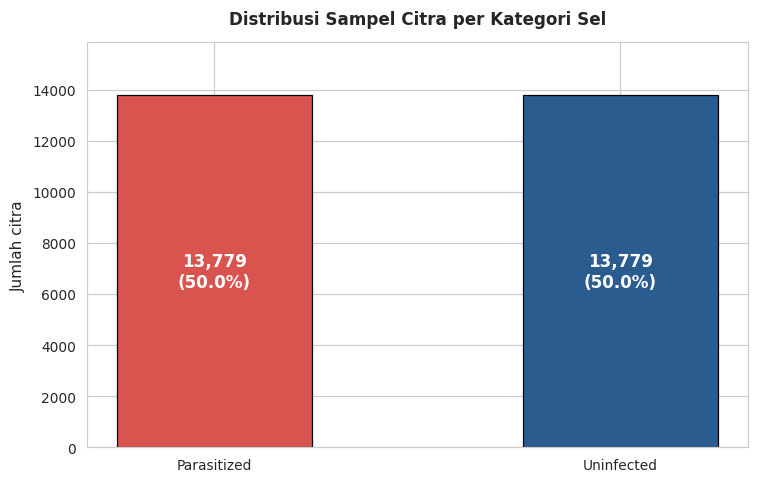

class_name,Parasitized,Uninfected,All
split,,,
train,9750,9811,19561
validation,1936,1993,3929
test,2093,1975,4068
All,13779,13779,27558


Rasio kelas terbanyak : terkecil = 1.000 : 1  -> penanganan class imbalance (oversampling/SMOTE/class_weight) tidak diperlukan bila rasio mendekati 1.


In [9]:
# ============================== 2A-2. Distribusi kelas (seluruh data) ==============================
def eda_plot_class_balance():
    order = ["Parasitized", "Uninfected"]
    counts = eda_df["class_name"].value_counts().reindex(order)
    with plt.rc_context(EDA_RC), sns.axes_style("whitegrid"):
        fig, ax = plt.subplots(figsize=(7, 4.5))
        bars = ax.bar(order, counts.values, color=[EDA_PALETTE[k] for k in order], width=0.48, edgecolor="black", linewidth=0.8)
        for bar in bars:
            hgt = bar.get_height()
            ax.annotate(f"{int(hgt):,}\n({hgt / len(eda_df) * 100:.1f}%)", (bar.get_x() + bar.get_width() / 2.0, hgt / 2),
                        ha="center", va="center", color="white", fontsize=11, fontweight="bold")
        ax.set_title("Distribusi Sampel Citra per Kategori Sel", fontweight="bold", pad=12)
        ax.set_ylabel("Jumlah citra")
        ax.set_ylim(0, counts.max() * 1.15)
        plt.tight_layout()
        plt.show()
    return counts

eda_class_counts = eda_plot_class_balance()
display(pd.crosstab(eda_df["split"], eda_df["class_name"], margins=True).reindex(["train", "validation", "test", "All"]))
print(f"Rasio kelas terbanyak : terkecil = {eda_class_counts.max() / eda_class_counts.min():.3f} : 1  "
      "-> penanganan class imbalance (oversampling/SMOTE/class_weight) tidak diperlukan bila rasio mendekati 1.")

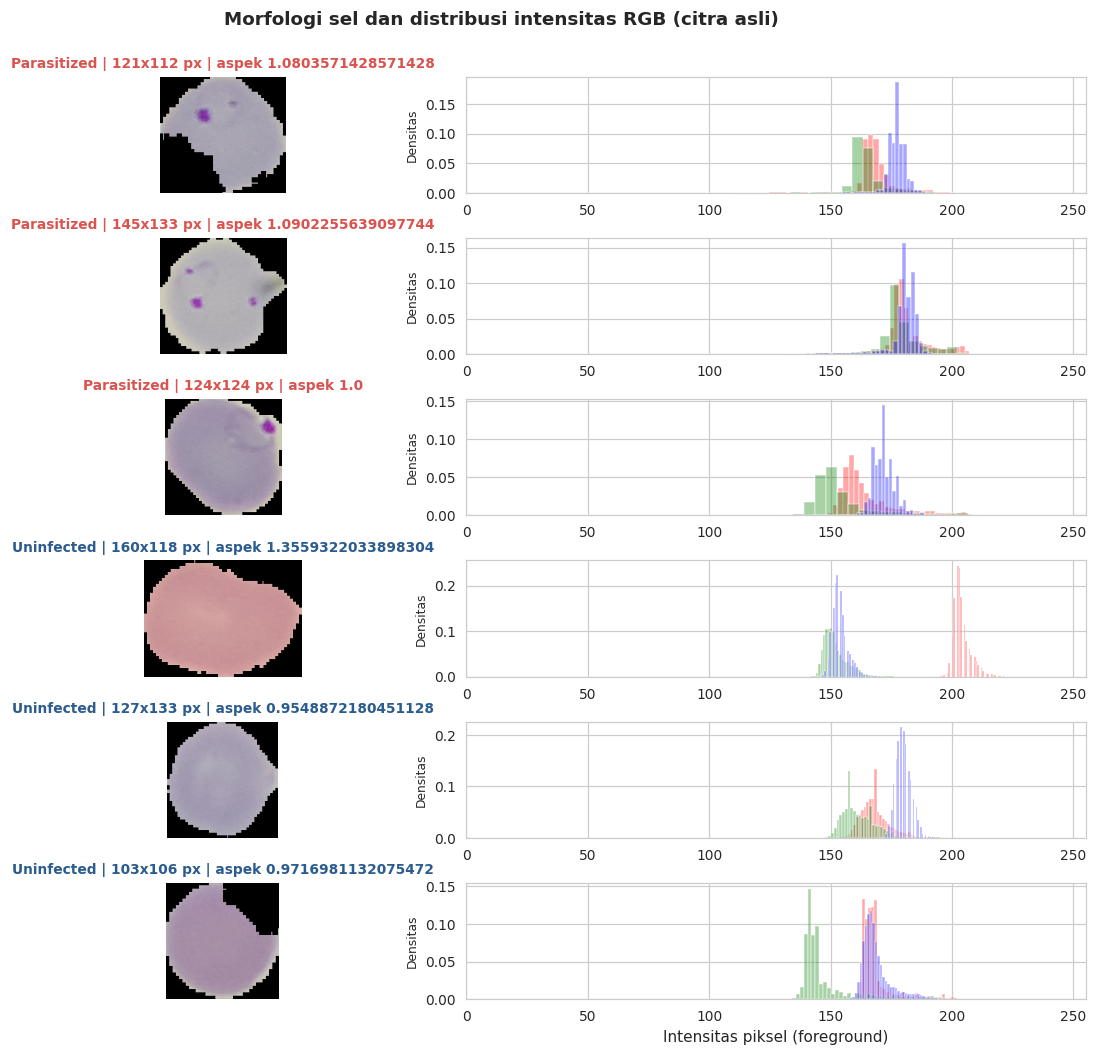

In [10]:
# ============================== 2A-3. Galeri morfologi dan histogram RGB (train/validation) ==============================
def eda_plot_samples(n_per_class=3, seed=15):
    with plt.rc_context(EDA_RC), sns.axes_style("whitegrid"):
        fig, axes = plt.subplots(n_per_class * 2, 2, figsize=(11, n_per_class * 3.2))
        row = 0
        for cls in ["Parasitized", "Uninfected"]:
            sample = eda_pix[eda_pix["class_name"] == cls].sample(n_per_class, random_state=seed)
            for _, item in sample.iterrows():
                with Image.open(item["abs_path"]) as im:
                    arr = np.asarray(im.convert("RGB"))
                axes[row, 0].imshow(arr)
                axes[row, 0].set_title(f"{cls} | {item['width']}x{item['height']} px | aspek {item['aspect_ratio']}",
                                       fontsize=9, fontweight="bold", color=EDA_PALETTE[cls])
                axes[row, 0].axis("off")
                for ch, col in enumerate(["red", "green", "blue"]):
                    vals = arr[:, :, ch].ravel()
                    vals = vals[vals > 15]                      # abaikan latar hitam
                    if len(vals):
                        axes[row, 1].hist(vals, bins=40, color=col, alpha=0.35, density=True)
                axes[row, 1].set_xlim(0, 255)
                axes[row, 1].set_ylabel("Densitas", fontsize=8)
                row += 1
        axes[-1, 1].set_xlabel("Intensitas piksel (foreground)")
        fig.suptitle("Morfologi sel dan distribusi intensitas RGB (citra asli)", fontweight="bold", y=0.995)
        plt.tight_layout()
        plt.show()

eda_plot_samples()

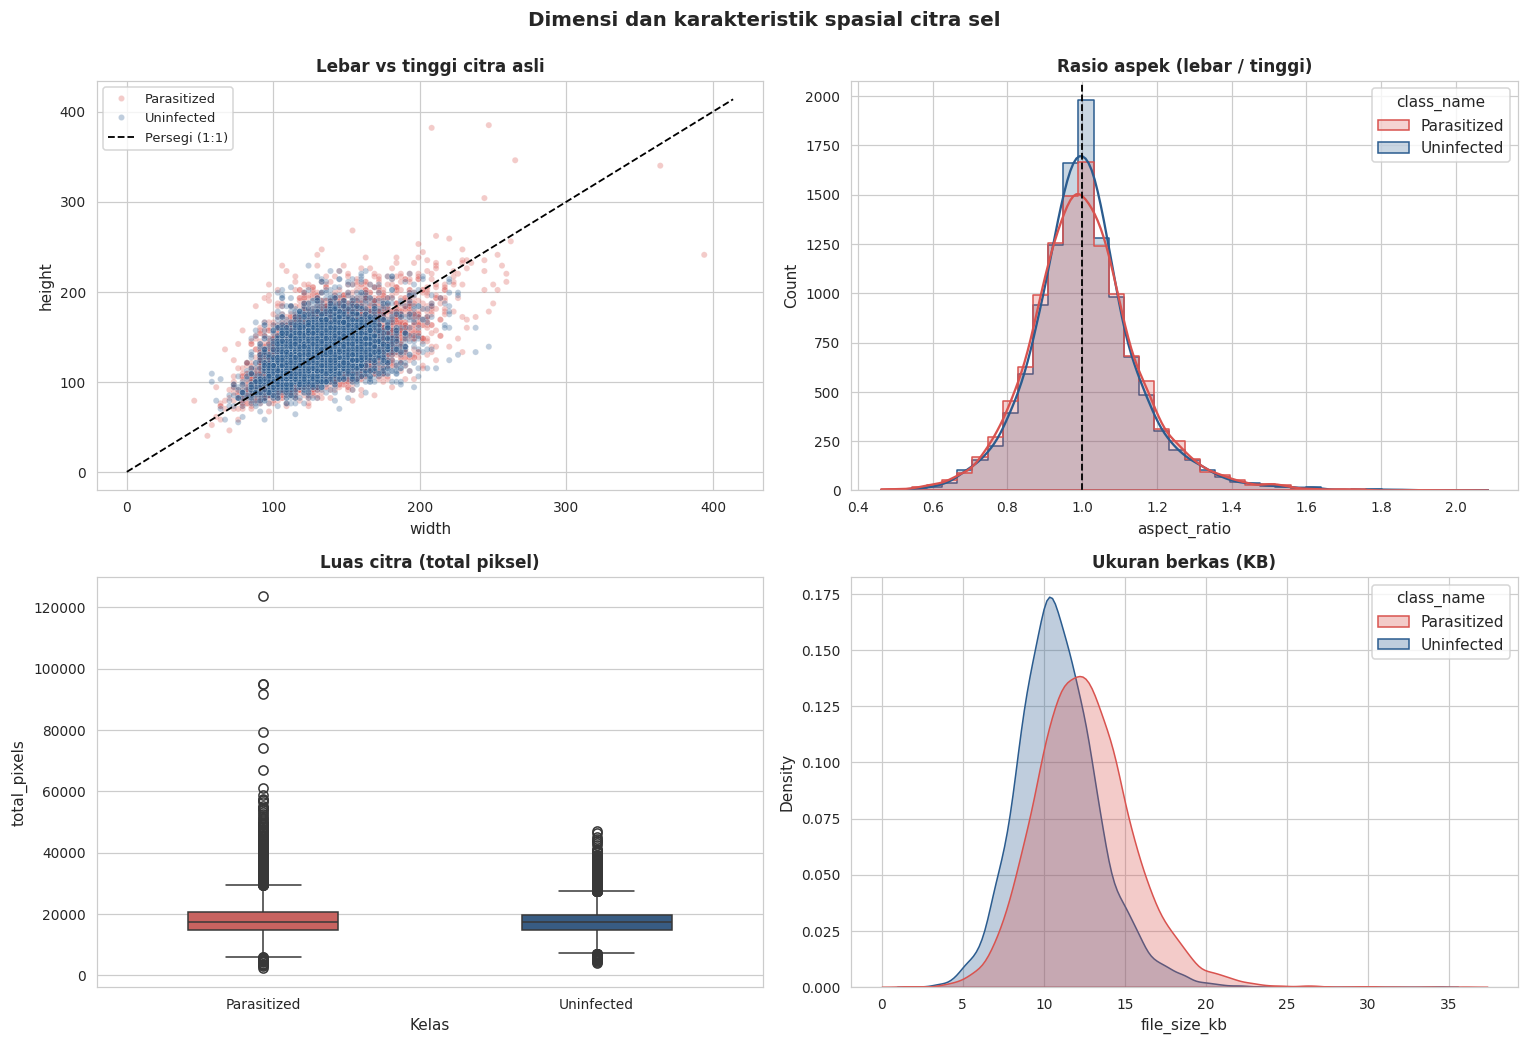

width                                height                     \
              min median        mean  max    std    min median        mean   
class_name                                                                   
Parasitized    46  133.0  133.377375  394  21.59     40  133.0  133.983741   
Uninfected     58  130.0  131.326923  247  18.60     55  130.0  131.540156   

                         ... total_pixels                                 \
             max    std  ...          min   median          mean     max   
class_name               ...                                               
Parasitized  385  22.32  ...         2200  17464.0  18144.610816  123760   
Uninfected   229  18.95  ...         3886  17182.0  17445.284819   47080   

                     file_size_kb                             
                 std          min median   mean    max   std  
class_name                                                    
Parasitized  5626.71         1.38  12.32  12.52  36.00  3.05  
Uninfected   4321.17         2.11  10.72  10.92  34.41  2.57  

[2 rows x 25 columns]

Citra non-persegi: 21,647 dari 23,490 (92.2%). Lebar 46-394 px, tinggi 40-385 px -> semua citra di-resize ke 128x128 (Bagian 4).


In [11]:
# ============================== 2A-4. Dimensi spasial citra (train/validation) ==============================
def eda_plot_dimensions():
    lim = float(max(eda_pix["width"].max(), eda_pix["height"].max())) * 1.05
    with plt.rc_context(EDA_RC), sns.axes_style("whitegrid"):
        fig, axes = plt.subplots(2, 2, figsize=(14, 9.5))
        sns.scatterplot(data=eda_pix, x="width", y="height", hue="class_name", alpha=0.3, s=16, palette=EDA_PALETTE, ax=axes[0, 0])
        axes[0, 0].plot([0, lim], [0, lim], color="black", linestyle="--", linewidth=1.2, label="Persegi (1:1)")
        axes[0, 0].set_title("Lebar vs tinggi citra asli", fontweight="bold")
        axes[0, 0].legend(loc="upper left", fontsize=8.5)
        sns.histplot(data=eda_pix, x="aspect_ratio", hue="class_name", bins=40, kde=True, palette=EDA_PALETTE, element="step", ax=axes[0, 1])
        axes[0, 1].axvline(1.0, color="black", linestyle="--", linewidth=1.2)
        axes[0, 1].set_title("Rasio aspek (lebar / tinggi)", fontweight="bold")
        sns.boxplot(data=eda_pix, x="class_name", y="total_pixels", hue="class_name", palette=EDA_PALETTE, width=0.45, legend=False, ax=axes[1, 0])
        axes[1, 0].set_title("Luas citra (total piksel)", fontweight="bold")
        axes[1, 0].set_xlabel("Kelas")
        sns.kdeplot(data=eda_pix, x="file_size_kb", hue="class_name", fill=True, alpha=0.3, common_norm=False, palette=EDA_PALETTE, ax=axes[1, 1])
        axes[1, 1].set_title("Ukuran berkas (KB)", fontweight="bold")
        fig.suptitle("Dimensi dan karakteristik spasial citra sel", fontsize=13, fontweight="bold", y=0.995)
        plt.tight_layout()
        plt.show()

eda_plot_dimensions()
eda_dim_summary = eda_pix.groupby("class_name")[["width", "height", "aspect_ratio", "total_pixels", "file_size_kb"]].agg(["min", "median", "mean", "max", "std"]).round(2)
display(eda_dim_summary)
eda_n_nonsquare = int((eda_pix["width"] != eda_pix["height"]).sum())
print(f"Citra non-persegi: {eda_n_nonsquare:,} dari {len(eda_pix):,} ({eda_n_nonsquare / len(eda_pix) * 100:.1f}%). "
      f"Lebar {eda_pix['width'].min()}-{eda_pix['width'].max()} px, tinggi {eda_pix['height'].min()}-{eda_pix['height'].max()} px "
      f"-> semua citra di-resize ke {IMAGE_SIZE}x{IMAGE_SIZE} (Bagian 4).")

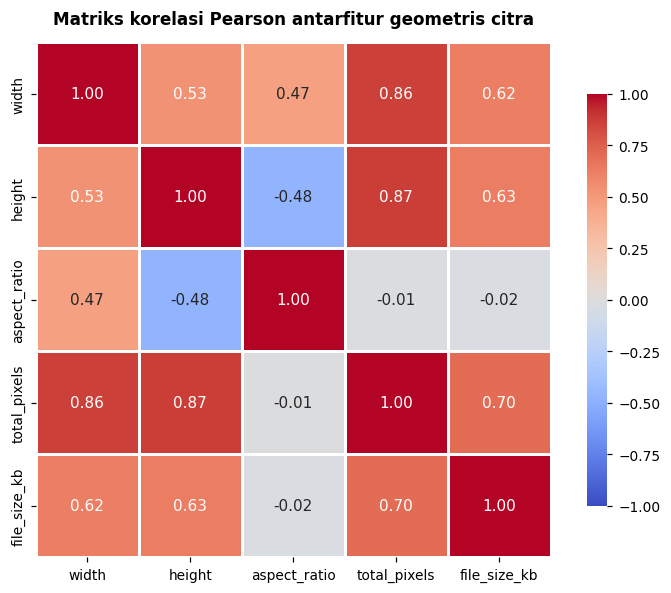

r(lebar, tinggi) = 0.53 | r(total piksel, ukuran berkas) = 0.70 | r(lebar, rasio aspek) = 0.47


In [12]:
# ============================== 2A-5. Korelasi fitur geometris (train/validation) ==============================
eda_geom_features = ["width", "height", "aspect_ratio", "total_pixels", "file_size_kb"]
eda_corr = eda_pix[eda_geom_features].corr()
with plt.rc_context(EDA_RC):
    plt.figure(figsize=(7, 5.5))
    sns.heatmap(eda_corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, square=True, linewidths=0.8, cbar_kws={"shrink": 0.8})
    plt.title("Matriks korelasi Pearson antarfitur geometris citra", fontweight="bold", pad=12)
    plt.tight_layout()
    plt.show()
print(f"r(lebar, tinggi) = {eda_corr.loc['width', 'height']:.2f} | r(total piksel, ukuran berkas) = {eda_corr.loc['total_pixels', 'file_size_kb']:.2f} "
      f"| r(lebar, rasio aspek) = {eda_corr.loc['width', 'aspect_ratio']:.2f}")

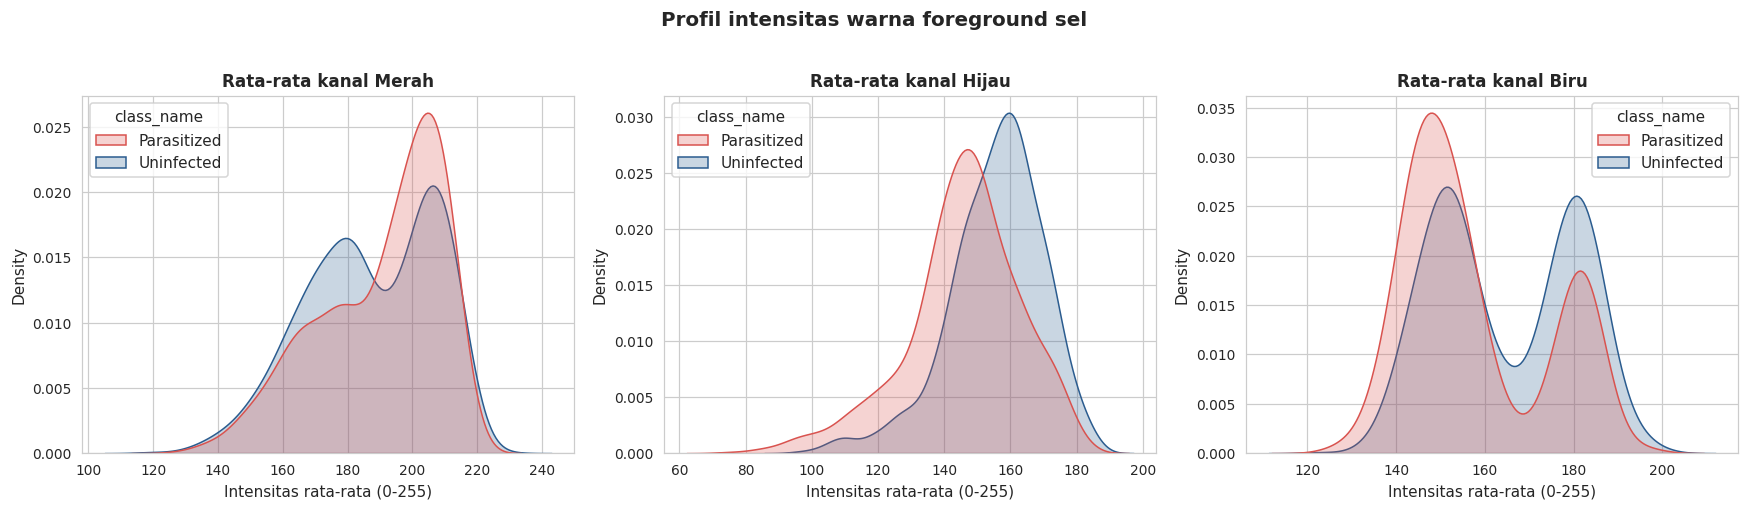

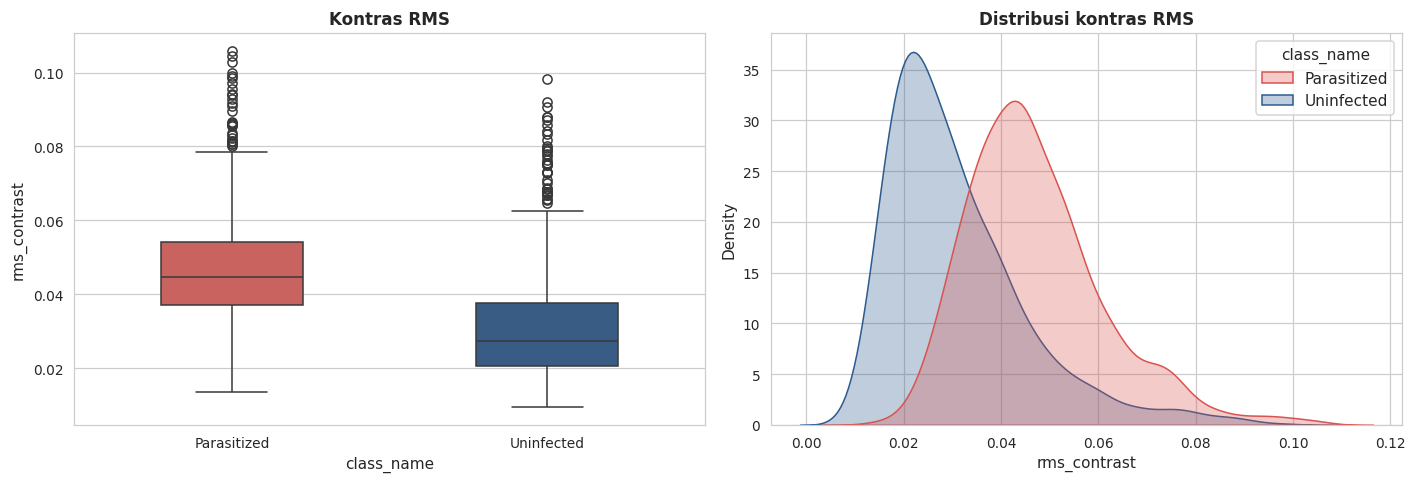

,mean_r,mean_g,mean_b,std_r,std_g,std_b
class_name,,,,,,
Parasitized,190.289993,145.570007,157.500000,8.72,15.38,5.76
Uninfected,187.369995,155.479996,164.789993,6.78,9.34,4.32


,count,mean,std,min,25%,50%,75%,max
class_name,,,,,,,,
Parasitized,1000.0,0.0471,0.0142,0.0137,0.0371,0.0446,0.0541,0.1058
Uninfected,1000.0,0.0309,0.0144,0.0095,0.0207,0.0275,0.0377,0.0983


Variasi antarslide (171 slide dalam sampel): rata-rata kanal hijau per slide berkisar 110.6-177.6 (SD 13.5).


In [13]:
# ============================== 2A-6. Profil warna RGB dan kontras RMS (sampel seimbang, train/validation) ==============================
def eda_color_stats(frame):
    rows = []
    for rel in frame["abs_path"]:
        with Image.open(rel) as im:
            rgb = np.asarray(im.convert("RGB"), dtype=np.float32)
            gray = np.asarray(im.convert("L"), dtype=np.float32) / 255.0
        mask = rgb.mean(axis=2) > 12                              # foreground sel (buang latar hitam)
        fg = rgb[mask] if mask.any() else rgb.reshape(-1, 3)
        fg_gray = gray[gray > 0.05]
        rows.append({"mean_r": fg[:, 0].mean(), "mean_g": fg[:, 1].mean(), "mean_b": fg[:, 2].mean(),
                     "std_r": fg[:, 0].std(), "std_g": fg[:, 1].std(), "std_b": fg[:, 2].std(),
                     "rms_contrast": float(fg_gray.std() if len(fg_gray) else gray.std())})
    return pd.DataFrame(rows, index=frame.index)

_n = min(EDA_COLOR_SAMPLE_PER_CLASS, int(eda_pix["class_name"].value_counts().min()))
eda_color = eda_pix.groupby("class_name").sample(n=_n, random_state=EDA_SEED).copy()
eda_color = eda_color.join(eda_color_stats(eda_color))

def eda_plot_color():
    with plt.rc_context(EDA_RC), sns.axes_style("whitegrid"):
        fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
        for ax, (col, title) in zip(axes, [("mean_r", "Merah"), ("mean_g", "Hijau"), ("mean_b", "Biru")]):
            sns.kdeplot(data=eda_color, x=col, hue="class_name", common_norm=False, fill=True, alpha=0.25, palette=EDA_PALETTE, ax=ax)
            ax.set_title(f"Rata-rata kanal {title}", fontweight="bold")
            ax.set_xlabel("Intensitas rata-rata (0-255)")
        fig.suptitle("Profil intensitas warna foreground sel", fontsize=13, fontweight="bold", y=1.02)
        plt.tight_layout()
        plt.show()

        fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
        sns.boxplot(data=eda_color, x="class_name", y="rms_contrast", hue="class_name", palette=EDA_PALETTE, width=0.45, legend=False, ax=axes[0])
        axes[0].set_title("Kontras RMS", fontweight="bold")
        sns.kdeplot(data=eda_color, x="rms_contrast", hue="class_name", common_norm=False, fill=True, alpha=0.3, palette=EDA_PALETTE, ax=axes[1])
        axes[1].set_title("Distribusi kontras RMS", fontweight="bold")
        plt.tight_layout()
        plt.show()

eda_plot_color()
display(eda_color.groupby("class_name")[["mean_r", "mean_g", "mean_b", "std_r", "std_g", "std_b"]].mean().round(2))
display(eda_color.groupby("class_name")["rms_contrast"].describe().round(4))

eda_slide_lum = eda_color.groupby("slide_id")[["mean_r", "mean_g", "mean_b"]].mean()
print(f"Variasi antarslide ({len(eda_slide_lum)} slide dalam sampel): rata-rata kanal hijau per slide berkisar "
      f"{eda_slide_lum['mean_g'].min():.1f}-{eda_slide_lum['mean_g'].max():.1f} (SD {eda_slide_lum['mean_g'].std():.1f}).")

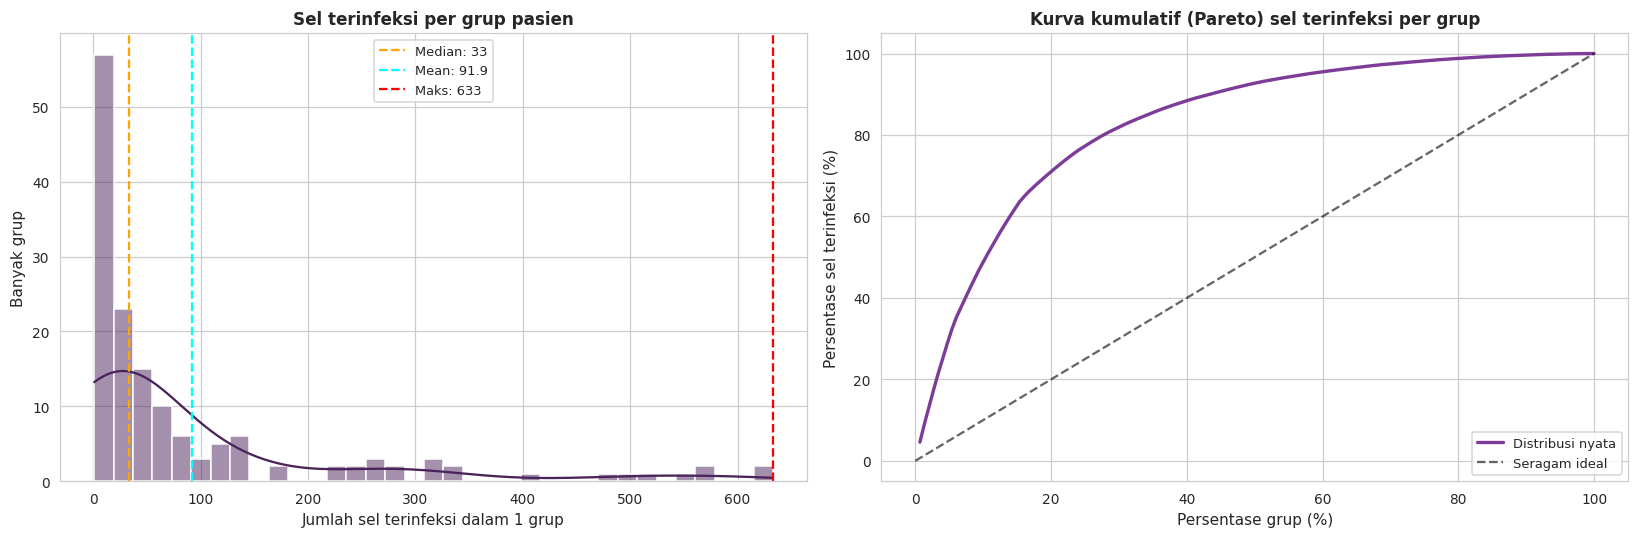

Slide unik: 201 | grup unik: 200 | grup terinfeksi: 150
Sel terinfeksi per grup: median 33, rentang 1-633; 10% grup teratas menyumbang 48.8% sel terinfeksi.


,group_id,sel_terinfeksi,kontribusi_total_%
0,pasien_p29,633,4.59
1,pasien_p4,616,4.47
2,pasien_p93,574,4.17
3,pasien_p60,564,4.09
4,pasien_p143,546,3.96
5,pasien_p20,507,3.68
6,pasien_p145,501,3.64
7,pasien_p141,479,3.48
8,pasien_p77,414,3.00
9,pasien_p98,332,2.41


Citra test yang grup pasiennya juga ada di train -> split acak per citra: 100.0% | split berbasis grup (manifest): 0.0%


In [14]:
# ============================== 2A-7. Struktur pasien/slide dan bukti group leakage (seluruh data: label + nama file) ==============================
eda_cells_per_group = eda_df.loc[eda_df["label"] == 1, "group_id"].value_counts()

def eda_plot_patients():
    global eda_sorted_counts, eda_cum_pct
    with plt.rc_context(EDA_RC), sns.axes_style("whitegrid"):
        fig, axes = plt.subplots(1, 2, figsize=(15, 5))
        sns.histplot(eda_cells_per_group.values, bins=35, kde=True, color="#4a235a", ax=axes[0])
        axes[0].axvline(eda_cells_per_group.median(), color="orange", linestyle="--", linewidth=1.5, label=f"Median: {eda_cells_per_group.median():.0f}")
        axes[0].axvline(eda_cells_per_group.mean(), color="cyan", linestyle="--", linewidth=1.5, label=f"Mean: {eda_cells_per_group.mean():.1f}")
        axes[0].axvline(eda_cells_per_group.max(), color="red", linestyle="--", linewidth=1.5, label=f"Maks: {eda_cells_per_group.max():.0f}")
        axes[0].set_title("Sel terinfeksi per grup pasien", fontweight="bold")
        axes[0].set_xlabel("Jumlah sel terinfeksi dalam 1 grup")
        axes[0].set_ylabel("Banyak grup")
        axes[0].legend(fontsize=8.5)

        eda_sorted_counts = np.sort(eda_cells_per_group.values)[::-1]
        eda_cum_pct = np.cumsum(eda_sorted_counts) / eda_sorted_counts.sum() * 100
        _pp = np.linspace(100 / len(eda_sorted_counts), 100, len(eda_sorted_counts))
        axes[1].plot(_pp, eda_cum_pct, color="#7d3c98", linewidth=2.2, label="Distribusi nyata")
        axes[1].plot([0, 100], [0, 100], color="black", linestyle="--", alpha=0.6, label="Seragam ideal")
        axes[1].set_title("Kurva kumulatif (Pareto) sel terinfeksi per grup", fontweight="bold")
        axes[1].set_xlabel("Persentase grup (%)")
        axes[1].set_ylabel("Persentase sel terinfeksi (%)")
        axes[1].legend(loc="lower right", fontsize=8.5)
        plt.tight_layout()
        plt.show()


eda_plot_patients()

_top10_n = max(1, int(np.ceil(0.10 * len(eda_sorted_counts))))
print(f"Slide unik: {eda_df['slide_id'].nunique()} | grup unik: {eda_df['group_id'].nunique()} | grup terinfeksi: {len(eda_cells_per_group)}")
print(f"Sel terinfeksi per grup: median {eda_cells_per_group.median():.0f}, rentang {eda_cells_per_group.min()}-{eda_cells_per_group.max()}; "
      f"10% grup teratas menyumbang {eda_cum_pct[_top10_n - 1]:.1f}% sel terinfeksi.")
display(pd.DataFrame({
    "group_id": eda_cells_per_group.head(10).index,
    "sel_terinfeksi": eda_cells_per_group.head(10).values,
    "kontribusi_total_%": (eda_cells_per_group.head(10).values / (eda_df["label"] == 1).sum() * 100).round(2),
}))

# Bukti leakage: split acak per citra (RandomState lokal) vs split berbasis grup yang dipakai eksperimen (manifest).
_rng = np.random.RandomState(EDA_SEED)
_perm = _rng.permutation(len(eda_df))
_n_test = int(round(len(eda_df) / 7))
_rand_test_idx, _rand_train_idx = _perm[:_n_test], _perm[2 * _n_test:]
_eda_g = eda_df["group_id"].to_numpy()
eda_leak_random = float(np.isin(_eda_g[_rand_test_idx], np.unique(_eda_g[_rand_train_idx])).mean() * 100)
_m_train = set(eda_df.loc[eda_df["split"] == "train", "group_id"])
eda_leak_manifest = float(eda_df.loc[eda_df["split"] == "test", "group_id"].isin(_m_train).mean() * 100)
print(f"Citra test yang grup pasiennya juga ada di train -> split acak per citra: {eda_leak_random:.1f}% | "
      f"split berbasis grup (manifest): {eda_leak_manifest:.1f}%")

In [15]:
# ============================== 2A-8. Sintesis temuan EDA (nilai dihitung dari data, bukan diketik) ==============================
_pos, _neg = int((eda_df["label"] == 1).sum()), int((eda_df["label"] == 0).sum())
_dark = ("Bukti kuantitatif: rata-rata kanal hijau per slide berkisar "
         f"{eda_slide_lum['mean_g'].min():.1f}-{eda_slide_lum['mean_g'].max():.1f} (SD {eda_slide_lum['mean_g'].std():.1f}) "
         f"pada {len(eda_slide_lum)} slide sampel.")
eda_synthesis = pd.DataFrame([
    {"Aspek": "Keseimbangan kelas",
     "Temuan": f"{_pos:,} Parasitized vs {_neg:,} Uninfected (rasio {max(_pos, _neg) / min(_pos, _neg):.2f} : 1).",
     "Implikasi": "Penanganan class imbalance tidak diperlukan; akurasi dan F1 dapat dibaca langsung."},
    {"Aspek": "Variasi dimensi",
     "Temuan": f"Lebar {eda_pix['width'].min()}-{eda_pix['width'].max()} px, tinggi {eda_pix['height'].min()}-{eda_pix['height'].max()} px; "
               f"{eda_n_nonsquare / len(eda_pix) * 100:.1f}% citra non-persegi.",
     "Implikasi": f"Resize bilinear ke {IMAGE_SIZE}x{IMAGE_SIZE} agar dapat disusun menjadi tensor 4D (Bagian 4)."},
    {"Aspek": "Struktur pasien",
     "Temuan": f"{len(eda_df):,} citra dari {eda_df['group_id'].nunique()} grup pasien/slide; sel terinfeksi per grup median "
               f"{eda_cells_per_group.median():.0f}, maksimum {eda_cells_per_group.max()}.",
     "Implikasi": f"Split acak per citra membocorkan grup ({eda_leak_random:.1f}% citra test punya grup di train) sedangkan manifest {eda_leak_manifest:.1f}%; "
                  "gunakan StratifiedGroupKFold berbasis group_id (Bagian 2)."},
    {"Aspek": "Variasi optik dan pewarnaan",
     "Temuan": _dark,
     "Implikasi": "Normalisasi piksel ke 0-1 (dibagi 255) dan Batch Normalization pada konfigurasi yang memakainya."},
    {"Aspek": "Artefak visual (kualitatif)",
     "Temuan": "Tidak diukur secara kuantitatif. Konfirmasi dari galeri sampel (2A-3) sebelum dinyatakan di laporan.",
     "Implikasi": "Motivasi Grad-CAM + deletion test dan kalibrasi keyakinan (Bagian 14-15) bersifat argumentatif, bukan hasil EDA."},
])
with pd.option_context("display.max_colwidth", None):
    display(eda_synthesis)
eda_synthesis.to_csv(OUTPUT_DIR / "tables" / "eda_synthesis.csv", index=False)

,Aspek,Temuan,Implikasi
0,Keseimbangan kelas,"13,779 Parasitized vs 13,779 Uninfected (rasio 1.00 : 1).",Penanganan class imbalance tidak diperlukan; akurasi dan F1 dapat dibaca langsung.
1,Variasi dimensi,"Lebar 46-394 px, tinggi 40-385 px; 92.2% citra non-persegi.",Resize bilinear ke 128x128 agar dapat disusun menjadi tensor 4D (Bagian 4).
2,Struktur pasien,"27,558 citra dari 200 grup pasien/slide; sel terinfeksi per grup median 33, maksimum 633.",Split acak per citra membocorkan grup (100.0% citra test punya grup di train) sedangkan manifest 0.0%; gunakan StratifiedGroupKFold berbasis group_id (Bagian 2).
3,Variasi optik dan pewarnaan,Bukti kuantitatif: rata-rata kanal hijau per slide berkisar 110.6-177.6 (SD 13.5) pada 171 slide sampel.,Normalisasi piksel ke 0-1 (dibagi 255) dan Batch Normalization pada konfigurasi yang memakainya.
4,Artefak visual (kualitatif),Tidak diukur secara kuantitatif. Konfirmasi dari galeri sampel (2A-3) sebelum dinyatakan di laporan.,"Motivasi Grad-CAM + deletion test dan kalibrasi keyakinan (Bagian 14-15) bersifat argumentatif, bukan hasil EDA."


## 3. Definisi konfigurasi dan arsitektur

**CNN kustom (A–L):** `Conv2D(5×5) → [BatchNorm] → ReLU → MaxPool → [Dropout 0,25]` × 3 blok (32, 64, 128 filter), lalu `GlobalAveragePooling → Dense(256, ReLU) → [Dropout 0,5] → Dense(1, sigmoid)`. BN dan Dropout hanya disisipkan sesuai konfigurasi; arsitektur selebihnya identik. Jumlah parameter diverifikasi terhadap protokol (291.905 tanpa BN; 292.801 dengan BN).

**MobileNetV2 fine-tuning (pembanding):** input 0–1 diubah ke rentang −1..1 (sesuai prapemrosesan MobileNetV2), `MobileNetV2(include_top=False, bobot ImageNet)` dengan **seluruh lapisan dilatih**, lalu `GlobalAveragePooling → Dense(1, sigmoid)`. Split, preprocessing (resize 128×128 dan skala piksel), loss, optimizer, batch size, tanpa augmentasi, pemilihan checkpoint, dan metrik sama dengan CNN kustom. Perbedaannya: LR konstan 1e-4 dan 15 epoch (model pre-trained konvergen lebih cepat); nilai ini tidak dituning.

In [ ]:
CONFIGS = {
    "A": {"bn": False, "dropout": False, "lr_mode": "constant", "phase": 1},
    "B": {"bn": True,  "dropout": False, "lr_mode": "constant", "phase": 1},
    "C": {"bn": False, "dropout": True,  "lr_mode": "constant", "phase": 1},
    "D": {"bn": True,  "dropout": True,  "lr_mode": "constant", "phase": 1},
    "E": {"bn": True,  "dropout": True,  "lr_mode": "plateau",  "phase": 1},
    "F": {"bn": True,  "dropout": True,  "lr_mode": "cosine",   "phase": 1},
    "G": {"bn": False, "dropout": False, "lr_mode": "plateau",  "phase": 2},
    "H": {"bn": False, "dropout": False, "lr_mode": "cosine",   "phase": 2},
    "I": {"bn": True,  "dropout": False, "lr_mode": "plateau",  "phase": 3},
    "J": {"bn": True,  "dropout": False, "lr_mode": "cosine",   "phase": 3},
    "K": {"bn": False, "dropout": True,  "lr_mode": "plateau",  "phase": 3},
    "L": {"bn": False, "dropout": True,  "lr_mode": "cosine",   "phase": 3},
}
MN_NAME = "MN"   # kode run MobileNetV2 fine-tuning


def build_model(use_bn: bool, use_dropout: bool, image_size: int = None):
    image_size = IMAGE_SIZE if image_size is None else image_size
    inputs = tf.keras.Input(shape=(image_size, image_size, 3), name="image")
    x = inputs
    for filters in [32, 64, 128]:
        x = tf.keras.layers.Conv2D(
            filters=filters, kernel_size=(5, 5), padding="same", use_bias=True,
            kernel_initializer="he_normal", bias_initializer="zeros",
        )(x)
        if use_bn:
            x = tf.keras.layers.BatchNormalization()(x)
        x = tf.keras.layers.Activation("relu")(x)
        x = tf.keras.layers.MaxPooling2D(pool_size=(2, 2))(x)
        if use_dropout:
            x = tf.keras.layers.Dropout(DROPOUT_CONV)(x)
    x = tf.keras.layers.GlobalAveragePooling2D()(x)
    x = tf.keras.layers.Dense(256, activation="relu", kernel_initializer="he_normal")(x)
    if use_dropout:
        x = tf.keras.layers.Dropout(DROPOUT_DENSE)(x)
    outputs = tf.keras.layers.Dense(1, activation="sigmoid", name="parasitized_probability")(x)
    return tf.keras.Model(inputs=inputs, outputs=outputs)


def build_mobilenet_finetune(image_size=None, weights="imagenet"):
    image_size = IMAGE_SIZE if image_size is None else image_size
    inputs = tf.keras.Input(shape=(image_size, image_size, 3), name="image")
    x = tf.keras.layers.Rescaling(scale=2.0, offset=-1.0, name="to_minus1_1")(inputs)   # 0..1 -> -1..1
    base = tf.keras.applications.MobileNetV2(
        input_shape=(image_size, image_size, 3), include_top=False, weights=weights, alpha=1.0)
    base.trainable = True            # fine-tuning: seluruh lapisan dilatih
    x = base(x)
    x = tf.keras.layers.GlobalAveragePooling2D()(x)
    outputs = tf.keras.layers.Dense(1, activation="sigmoid", name="parasitized_probability")(x)
    return tf.keras.Model(inputs=inputs, outputs=outputs)


def build_model_for_spec(spec, pretrained=True):
    """pretrained=False dipakai saat evaluasi: arsitektur sama, bobot dimuat dari checkpoint (tanpa unduhan)."""
    if spec["kind"] == "cnn":
        return build_model(spec["bn"], spec["dropout"])
    return build_mobilenet_finetune(IMAGE_SIZE, MOBILENET_WEIGHTS if pretrained else None)


def compile_model(model, spec):
    model.compile(
        optimizer=make_optimizer(spec["initial_lr"]),
        loss="binary_crossentropy",
        metrics=[tf.keras.metrics.BinaryAccuracy(name="accuracy")],
    )


# Uji jumlah parameter CNN sesuai tabel protokol.
model_A_check = build_model(False, False)
model_B_check = build_model(True, False)
print("Parameter A:", model_A_check.count_params(), "(target 291905)")
print("Parameter B:", model_B_check.count_params(), "(target 292801)")
assert model_A_check.count_params() == 291905, "Parameter baseline tidak cocok dengan protokol."
assert model_B_check.count_params() == 292801, "Parameter model dengan BN tidak cocok dengan protokol."
model_A_check.summary()
del model_A_check, model_B_check

# Uji awal MobileNetV2: pastikan bobot dapat dimuat SEKARANG, bukan di tengah eksperimen.
try:
    _mn_check = build_mobilenet_finetune(IMAGE_SIZE, MOBILENET_WEIGHTS)
    print("Parameter MobileNetV2 fine-tuning:", _mn_check.count_params(), "| bobot:", MOBILENET_WEIGHTS)
    del _mn_check
except Exception as exc:
    raise RuntimeError(
        "Bobot MobileNetV2 tidak dapat dimuat. Di Kaggle aktifkan Internet (Settings → Internet), atau unggah file bobot "
        "'mobilenet_v2_weights_tf_dim_ordering_tf_kernels_1.0_128_no_top.h5' sebagai dataset lalu isi MOBILENET_WEIGHTS "
        f"dengan path file tersebut. Galat asli: {exc}"
    ) from exc
tf.keras.backend.clear_session()

Parameter A: 291905 (target 291905)
Parameter B: 292801 (target 292801)


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ image (InputLayer)              │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 128, 128, 32)   │         2,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 128, 128, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 64)     │        51,264 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 64, 64, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 128)    │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 32, 32, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ parasitized_probability (Dense) │ (None, 1)              │           257 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 291,905 (1.11 MB)

 Trainable params: 291,905 (1.11 MB)

 Non-trainable params: 0 (0.00 B)

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
Parameter MobileNetV2 fine-tuning: 2259265 | bobot: imagenet


## 4. Pipeline input (tanpa augmentasi) dan cache RAM

Citra dibaca satu kali per sesi, di-resize bilinear ke 128×128 RGB, dan disimpan sebagai array `uint8` di RAM (sekitar 1,2 GB untuk train+validation; test baru dibaca saat evaluasi). Skala piksel 0–1 diterapkan saat batch dibentuk (bagi 255). Urutan data train per epoch adalah fungsi murni dari `(seed, epoch)`, sehingga run yang dilanjutkan tetap memakai urutan data yang sama dengan run tanpa gangguan. Validation dan test tidak diacak.

In [ ]:
def _decode_resize_uint8(path):
    image_bytes = tf.io.read_file(path)
    image = tf.io.decode_image(image_bytes, channels=3, expand_animations=False)
    image.set_shape([None, None, 3])
    image = tf.image.resize(image, [IMAGE_SIZE, IMAGE_SIZE], method="bilinear", antialias=False)
    return tf.cast(tf.clip_by_value(tf.round(image), 0.0, 255.0), tf.uint8)


def build_image_cache(frame, description):
    t0 = time.time()
    ds = (tf.data.Dataset.from_tensor_slices(frame.abs_path.astype(str).values)
          .map(_decode_resize_uint8, num_parallel_calls=tf.data.AUTOTUNE, deterministic=True)
          .batch(256).prefetch(2))
    x = np.concatenate([b.numpy() for b in ds], axis=0)
    print(f"Cache {description}: {x.shape} uint8, {x.nbytes / 1e9:.2f} GB, {time.time() - t0:.0f} dtk")
    return x


def epoch_permutation(n, seed, epoch):
    state = (int(seed) * 100003 + int(epoch) * 7919 + 12345) % (2 ** 32 - 1)
    return np.random.RandomState(state).permutation(n)


def make_train_dataset(seed, epoch):
    perm = epoch_permutation(len(TRAIN_Y), seed, epoch)

    def gen():
        for i in range(0, len(perm), BATCH_SIZE):
            idx = perm[i:i + BATCH_SIZE]
            yield TRAIN_X[idx].astype(np.float32) / 255.0, TRAIN_Y[idx]

    signature = (tf.TensorSpec(shape=(None, IMAGE_SIZE, IMAGE_SIZE, 3), dtype=tf.float32),
                 tf.TensorSpec(shape=(None,), dtype=tf.float32))
    return tf.data.Dataset.from_generator(gen, output_signature=signature).prefetch(tf.data.AUTOTUNE)


def make_eval_dataset(x_uint8, y=None):
    """Dataset deterministik tanpa pengacakan. y=None menghasilkan dataset hanya-citra (untuk predict)."""
    if y is None:
        ds = tf.data.Dataset.from_tensor_slices(x_uint8).batch(BATCH_SIZE)
        return ds.map(lambda x: tf.cast(x, tf.float32) / 255.0).prefetch(tf.data.AUTOTUNE)
    ds = tf.data.Dataset.from_tensor_slices((x_uint8, y)).batch(BATCH_SIZE)
    return ds.map(lambda x, t: (tf.cast(x, tf.float32) / 255.0, t)).prefetch(tf.data.AUTOTUNE)


def _balanced_sample(frame, n, seed):
    per_class = n // 2
    parts = [frame.loc[frame.label == c].sample(n=min(per_class, int((frame.label == c).sum())), random_state=seed)
             for c in [0, 1]]
    return pd.concat(parts).sort_values("path").reset_index(drop=True)


train_frame = sets["train"].reset_index(drop=True)
val_frame = sets["validation"].reset_index(drop=True)
test_frame = sets["test"].reset_index(drop=True)
if SMOKE_TEST:
    train_frame = _balanced_sample(train_frame, SMOKE_N_TRAIN, 2026)
    val_frame = _balanced_sample(val_frame, SMOKE_N_VAL, 2026)
    test_frame = _balanced_sample(test_frame, SMOKE_N_TEST, 2026)

TRAIN_X = build_image_cache(train_frame, "train")
TRAIN_Y = train_frame.label.to_numpy(dtype=np.float32)
VAL_X = build_image_cache(val_frame, "validation")
VAL_Y = val_frame.label.to_numpy(dtype=np.float32)
print("Jumlah batch train:", int(np.ceil(len(TRAIN_Y) / BATCH_SIZE)), "| validation:", int(np.ceil(len(VAL_Y) / BATCH_SIZE)))

Cache train: (19561, 128, 128, 3) uint8, 0.96 GB, 21 dtk
Cache validation: (3929, 128, 128, 3) uint8, 0.19 GB, 3 dtk
Jumlah batch train: 306 | validation: 62


## 4A. Uji kewarasan: baseline harus dapat menghafal ±200 citra

Baseline A dilatih pada subset **200 citra dari train saja** (100 per kelas) selama 200 epoch. Akurasi latih epoch terakhir harus ≥ 95%. Uji ini bukan bagian dari hasil penelitian, tidak memakai validation maupun test, dan hasilnya disimpan sehingga tidak diulang di sesi berikutnya.

In [ ]:
SANITY_CHECK_IMAGES_PER_CLASS = 100
SANITY_CHECK_EPOCHS = 200
SANITY_CHECK_THRESHOLD = 0.95
sanity_path = OUTPUT_DIR / "sanity_check_result.json"

sanity_result = read_json_safe(sanity_path)
if sanity_result is not None and (sanity_result.get("image_size") != IMAGE_SIZE
                                  or sanity_result.get("epochs") != SANITY_CHECK_EPOCHS
                                  or sanity_result.get("dataset_fingerprint") != dataset_fingerprint):
    sanity_result = None

if sanity_result is None:
    rng = np.random.RandomState(2026)
    pos = []
    for cls in [0, 1]:
        cls_idx = np.where(TRAIN_Y == cls)[0]
        pos.append(rng.choice(cls_idx, size=min(SANITY_CHECK_IMAGES_PER_CLASS, len(cls_idx)), replace=False))
    pos = np.concatenate(pos)
    rng.shuffle(pos)
    xs = TRAIN_X[pos].astype(np.float32) / 255.0
    ys = TRAIN_Y[pos]

    tf.keras.backend.clear_session()
    gc.collect()
    set_run_seed(2026)
    sanity_model = build_model(use_bn=False, use_dropout=False)
    sanity_model.compile(optimizer=make_optimizer(1e-3), loss="binary_crossentropy",
                         metrics=[tf.keras.metrics.BinaryAccuracy(name="accuracy")])
    sanity_history = sanity_model.fit(xs, ys, batch_size=BATCH_SIZE, epochs=SANITY_CHECK_EPOCHS,
                                      shuffle=True, verbose=0)
    sanity_train_accuracy = float(sanity_history.history["accuracy"][-1])
    sanity_result = {
        "images": int(len(pos)), "images_per_class": SANITY_CHECK_IMAGES_PER_CLASS,
        "epochs": SANITY_CHECK_EPOCHS, "train_accuracy_last_epoch": sanity_train_accuracy,
        "threshold": SANITY_CHECK_THRESHOLD, "image_size": IMAGE_SIZE,
        "dataset_fingerprint": dataset_fingerprint,
        "passed": bool(sanity_train_accuracy >= SANITY_CHECK_THRESHOLD),
    }
    save_json(sanity_path, sanity_result)
    del sanity_model, sanity_history, xs, ys
    tf.keras.backend.clear_session()
    gc.collect()

print("Hasil sanity check:", sanity_result)
if not sanity_result["passed"]:
    raise RuntimeError(
        f"Sanity check belum mencapai akurasi train {SANITY_CHECK_THRESHOLD:.0%}. "
        "Periksa pipeline/model sebelum melanjutkan eksperimen utama."
    )

2026-11-04 15:10:27.767113: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-11-04 15:10:27.921117: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
I0000 00:00:1793805030.998494      70 device_compiler.h:196] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.
2026-11-04 15:10:32.016425: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-11-04 15:10:32.159453: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-o

Hasil sanity check: {'images': 200, 'images_per_class': 100, 'epochs': 200, 'train_accuracy_last_epoch': 1.0, 'threshold': 0.95, 'image_size': 128, 'dataset_fingerprint': 'f9c606cec18732ec77b7503b86205b1c447c406e13f7ab0299ae0dc6c5f74ee9', 'passed': True}


## 5. Mesin pelatihan dengan resume per epoch

Satu fungsi `train_one_run` melatih semua jenis run (pilot, CNN A–L, MobileNetV2). Tiap epoch:
1. LR ditetapkan menurut mode (konstan, `ReduceLROnPlateau` dengan faktor 0,5, patience 3, min LR 1e-6, atau cosine decay per epoch).
2. Satu epoch dilatih pada urutan data `(seed, epoch)`, lalu divalidasi.
3. Bobot terbaik (val loss terendah) disimpan atomik ke `best.weights.h5`.
4. **Checkpoint** (model + optimizer + riwayat + status scheduler + `state.json`) ditulis ke dua slot bergantian (`ckpt_a`/`ckpt_b`); slot hanya sah bila `state.json`-nya lengkap, jadi gangguan di tengah penulisan tidak merusak checkpoint sebelumnya.
5. Penjaga waktu memeriksa sisa waktu sesi; bila tidak cukup, pelatihan berhenti dengan rapi.

**Sidik jari run (kompatibilitas resume).** Run hanya dilanjutkan bila definisi eksperimennya cocok persis: konfigurasi, seed, LR, epoch, ukuran input, batch size, sidik jari dataset, hash manifest, dan versi mayor Keras. Versi library, jenis GPU, dan platform **hanya dicatat** (bukan syarat), supaya run dapat dilanjutkan dari Kaggle ke Colab dan sebaliknya. Bila tidak cocok atau checkpoint tidak terbaca, run diulang dari epoch 0.

Setelah run selesai: bobot terbaik dimuat, prediksi validation disimpan (`val_predictions.csv`), `history.csv` dan `training_metadata.json` ditulis, dan checkpoint dihapus. **Test set tidak disentuh di sini.**

In [ ]:
def hard_fingerprint(spec, seed):
    """Definisi eksperimen yang HARUS sama agar resume sah. Versi library/GPU/platform sengaja tidak dimasukkan."""
    return norm_json({
        "protocol_version": PROTOCOL_VERSION,
        "spec": {k: v for k, v in spec.items() if k != "phase"},
        "seed": int(seed),
        "image_size": IMAGE_SIZE, "batch_size": BATCH_SIZE, "min_lr": MIN_LR,
        "dropout_conv": DROPOUT_CONV, "dropout_dense": DROPOUT_DENSE,
        "dataset_fingerprint": dataset_fingerprint, "manifest_hash": manifest_hash,
        "n_train": int(len(TRAIN_Y)), "n_val": int(len(VAL_Y)),
        "keras_major": KERAS_MAJOR, "smoke": bool(SMOKE_TEST),
    })


def plateau_update(plateau, val_loss, factor=0.5, patience=3, min_delta=1e-4, min_lr=None):
    """Replika ReduceLROnPlateau Keras (monitor val_loss, mode min, cooldown 0); status mudah diserialisasi."""
    min_lr = MIN_LR if min_lr is None else min_lr
    best = float("inf") if plateau["best"] is None else float(plateau["best"])
    if val_loss < best - min_delta:
        plateau["best"] = float(val_loss)
        plateau["wait"] = 0
    else:
        plateau["wait"] += 1
        if plateau["wait"] >= patience:
            if plateau["lr"] > min_lr:
                new_lr = max(plateau["lr"] * factor, min_lr)
                print(f"    ReduceLROnPlateau: LR {plateau['lr']:.3g} -> {new_lr:.3g}")
                plateau["lr"] = float(new_lr)
            plateau["wait"] = 0
    return plateau


def lr_for_epoch(spec, epoch, plateau):
    if spec["lr_mode"] == "plateau":
        return float(plateau["lr"])
    if spec["lr_mode"] == "cosine":
        return cosine_lr_for_epoch(epoch, spec["epochs"], spec["initial_lr"], MIN_LR)
    return float(spec["initial_lr"])


def save_best_weights(model, best_path):
    best_path = Path(best_path)
    tmp = best_path.with_name("best.tmp.weights.h5")
    model.save_weights(str(tmp))
    os.replace(tmp, best_path)


def save_checkpoint(run_dir, epoch_completed, model, state):
    slot = CKPT_SLOTS[epoch_completed % 2]
    d = Path(run_dir) / slot
    d.mkdir(parents=True, exist_ok=True)
    state_path = d / "state.json"
    if state_path.exists():
        state_path.unlink()                      # slot tidak sah selama sedang ditulis
    tmp_model = d / "model.tmp.keras"
    model.save(str(tmp_model))
    os.replace(tmp_model, d / "model.keras")
    save_json(state_path, {**state, "epoch_completed": int(epoch_completed)})   # terakhir: slot menjadi sah


def load_checkpoint(run_dir, fp):
    """Kembalikan ((model, state), None) bila ada checkpoint sah dan kompatibel; selain itu (None, alasan)."""
    run_dir = Path(run_dir)
    slots = valid_checkpoint_slots(run_dir)
    if not slots:
        return None, "tidak ada checkpoint"
    reason = "checkpoint tidak terbaca"
    for epoch_completed, slot, st in slots:
        if norm_json(st.get("hard_fingerprint")) != fp:
            return None, "sidik jari berbeda (konfigurasi/dataset/pengaturan berubah)"
        if len(st.get("history", [])) != epoch_completed:
            reason = "riwayat tidak konsisten dengan epoch"
            continue
        if st.get("best_epoch", 0) > 0 and not (run_dir / "best.weights.h5").exists():
            reason = "best.weights.h5 hilang"
            continue
        try:
            model = tf.keras.models.load_model(str(run_dir / slot / "model.keras"))
            return (model, st), None
        except Exception as exc:
            reason = f"gagal memuat model checkpoint: {exc}"
    return None, reason


def reset_run_dir(run_dir):
    run_dir = Path(run_dir)
    for item in list(run_dir.iterdir()):
        if item.is_dir():
            shutil.rmtree(item, ignore_errors=True)
        else:
            item.unlink()


def _hist_value(h, *keys):
    for k in keys:
        if k in h and len(h[k]):
            return float(h[k][-1])
    return float("nan")


def train_one_run(spec, seed, run_dir):
    """Latih (atau lanjutkan) satu run. Mengembalikan metadata dengan status 'completed' atau 'interrupted'."""
    global STOP_REQUESTED
    run_dir = Path(run_dir)
    run_dir.mkdir(parents=True, exist_ok=True)
    run_id = f"{spec['name']}_seed_{seed}"
    status_path = run_dir / "training_metadata.json"
    best_path = run_dir / "best.weights.h5"
    history_path = run_dir / "history.csv"
    valpred_path = run_dir / "val_predictions.csv"
    fp = hard_fingerprint(spec, seed)

    # 1) Sudah selesai dan kompatibel?
    if status_path.exists() and not FORCE_RERUN_COMPLETED_RUNS:
        old = read_json_safe(status_path)
        if (old and old.get("status") == "completed" and norm_json(old.get("hard_fingerprint")) == fp
                and best_path.exists() and history_path.exists() and valpred_path.exists()):
            print(f"[SKIP] {run_id} sudah selesai dan kompatibel.")
            return old
        print(f"[ULANG] {run_id}: hasil lama tidak lengkap/tidak kompatibel dengan pengaturan saat ini.")

    # 2) Lanjutkan dari checkpoint bila sah
    resumed = None
    if not FORCE_RERUN_COMPLETED_RUNS:
        resumed, why = load_checkpoint(run_dir, fp)
        if resumed is None and why != "tidak ada checkpoint":
            print(f"[CHECKPOINT DIABAIKAN] {run_id}: {why}. Run diulang dari epoch 0.")
    if resumed is None:
        reset_run_dir(run_dir)

    tf.keras.backend.clear_session()
    gc.collect()
    total_epochs = int(spec["epochs"])

    if resumed is not None:
        model, st = resumed
        history_rows = list(st["history"])
        best_val_loss = st["best_val_loss"]
        best_epoch = int(st["best_epoch"])
        plateau = dict(st["plateau"])
        train_seconds = float(st["train_seconds"])
        resume_log = list(st.get("resume_log", []))
        platforms = list(st.get("platforms", []))
        resume_log.append({"at": datetime.now().isoformat(timespec="seconds"), "platform": PLATFORM_NAME,
                           "resumed_from_epoch": len(history_rows)})
        if PLATFORM_NAME not in platforms:
            platforms.append(PLATFORM_NAME)
        set_run_seed(int(seed) * 1000 + len(history_rows))      # seed baru agar mask Dropout tidak mengulang epoch 0
        if getattr(model, "optimizer", None) is None:
            compile_model(model, spec)
        print(f"\n[RESUME] {run_id}: dilanjutkan dari epoch {len(history_rows)}/{total_epochs} (platform: {PLATFORM_NAME})")
    else:
        history_rows, best_val_loss, best_epoch = [], None, 0
        plateau = {"best": None, "wait": 0, "lr": float(spec["initial_lr"])}
        train_seconds, resume_log, platforms = 0.0, [], [PLATFORM_NAME]
        set_run_seed(seed)
        model = build_model_for_spec(spec, pretrained=True)
        compile_model(model, spec)
        print(f"\n[TRAIN] {run_id} | {spec['kind']} BN={spec.get('bn')} Dropout={spec.get('dropout')} "
              f"LR={spec['lr_mode']}({spec['initial_lr']:g}) | params={model.count_params():,}")

    params = int(model.count_params())
    save_json(run_dir / "config.json", {"run_id": run_id, "hard_fingerprint": fp, "parameters": params,
                                        "optimizer": "Adam(beta_1=0.9, beta_2=0.999)", "loss": "binary_crossentropy",
                                        "augmentation": "none", "precision": "float32"})
    val_ds = make_eval_dataset(VAL_X, VAL_Y)
    last_epoch_seconds = None
    interrupted = False

    for epoch in range(len(history_rows), total_epochs):
        if not time_budget_allows(last_epoch_seconds):
            interrupted = True
            break
        lr = lr_for_epoch(spec, epoch, plateau)
        set_learning_rate(model, lr)
        t0 = time.perf_counter()
        h = model.fit(make_train_dataset(seed, epoch), validation_data=val_ds, epochs=1, verbose=0).history
        seconds = time.perf_counter() - t0
        row = {"epoch": epoch + 1,
               "loss": _hist_value(h, "loss"), "accuracy": _hist_value(h, "accuracy", "binary_accuracy"),
               "val_loss": _hist_value(h, "val_loss"), "val_accuracy": _hist_value(h, "val_accuracy", "val_binary_accuracy"),
               "learning_rate": float(lr), "seconds": float(seconds)}
        history_rows.append(row)
        train_seconds += seconds
        last_epoch_seconds = seconds

        if spec["lr_mode"] == "plateau":
            plateau_update(plateau, row["val_loss"])
        if best_val_loss is None or row["val_loss"] < best_val_loss:
            best_val_loss, best_epoch = float(row["val_loss"]), epoch + 1
            save_best_weights(model, best_path)

        state = {"hard_fingerprint": fp, "history": history_rows, "best_val_loss": best_val_loss,
                 "best_epoch": best_epoch, "plateau": plateau, "train_seconds": train_seconds,
                 "resume_log": resume_log, "platforms": platforms, "environment": env_snapshot()}
        save_checkpoint(run_dir, epoch + 1, model, state)
        print(f"  epoch {epoch + 1}/{total_epochs} - {seconds:.0f}s - loss {row['loss']:.4f} acc {row['accuracy']:.4f} "
              f"- val_loss {row['val_loss']:.4f} val_acc {row['val_accuracy']:.4f} - lr {lr:.3g}")

    if interrupted:
        STOP_REQUESTED = True
        done = len(history_rows)
        print(f"[BERHENTI] {run_id}: penjaga waktu menghentikan run pada epoch {done}/{total_epochs}. "
              f"Checkpoint tersimpan; jalankan notebook lagi (sesi baru) untuk melanjutkan.")
        del model
        tf.keras.backend.clear_session()
        gc.collect()
        return {"status": "interrupted", "run_id": run_id, "epochs_completed": done}

    # 3) Finalisasi: bobot terbaik, prediksi validation, riwayat, metadata
    if not best_path.exists():
        raise RuntimeError(f"Checkpoint terbaik tidak ditemukan untuk {run_id}.")
    model.load_weights(str(best_path))
    val_prob = np.asarray(model.predict(make_eval_dataset(VAL_X), verbose=0)).reshape(-1)
    pd.DataFrame({"path": val_frame.path.values, "y_true": VAL_Y.astype(int),
                  "y_probability_parasitized": val_prob}).to_csv(valpred_path, index=False)
    history_df = pd.DataFrame(history_rows)
    history_df.to_csv(history_path, index=False)

    best_idx = int(np.argmin(history_df["val_loss"].values))
    min_val_loss = float(history_df.loc[best_idx, "val_loss"])
    train_loss_at_best = float(history_df.loc[best_idx, "loss"])
    convergence_epochs = np.where(history_df["val_loss"].values <= 1.05 * min_val_loss)[0]
    convergence_epoch = int(convergence_epochs[0] + 1) if len(convergence_epochs) else None
    metadata = {
        "status": "completed", "run_id": run_id, "config": spec["name"], "seed": int(seed),
        "kind": spec["kind"], "lr_mode": spec["lr_mode"], "initial_learning_rate": float(spec["initial_lr"]),
        "epochs": total_epochs, "image_size": IMAGE_SIZE, "batch_size": BATCH_SIZE, "parameters": params,
        "epochs_completed": int(len(history_df)),
        "best_epoch": int(history_df.loc[best_idx, "epoch"]), "best_val_loss": min_val_loss,
        "train_loss_at_best_epoch": train_loss_at_best,
        "val_minus_train_loss_at_best": float(min_val_loss - train_loss_at_best),
        "convergence_epoch": convergence_epoch,
        "training_duration_seconds": float(train_seconds),
        "seconds_per_epoch": float(train_seconds / max(len(history_df), 1)),
        "resumed": bool(resume_log), "resume_log": resume_log, "platforms_used": platforms,
        "environment_last_session": env_snapshot(), "hard_fingerprint": fp,
        "completed_at": datetime.now().isoformat(timespec="seconds"),
    }
    save_json(status_path, metadata)
    for slot in CKPT_SLOTS:
        shutil.rmtree(run_dir / slot, ignore_errors=True)       # checkpoint tidak diperlukan lagi
    print(f"[DONE] {run_id}: best val_loss={min_val_loss:.6f} epoch={metadata['best_epoch']} | "
          f"{train_seconds / 60:.1f} menit{' | DILANJUTKAN dari checkpoint' if resume_log else ''}")
    del model
    tf.keras.backend.clear_session()
    gc.collect()
    return metadata

## 6. Pilot learning rate (baseline A, seed 1)

Baseline A dilatih 15 epoch dengan LR 3e-4 dan 1e-3 memakai split train/validation yang sama. LR dengan **validation loss minimum** lebih kecil dipakai untuk **semua** konfigurasi (A–L). Test set tidak dipakai. Pilot memakai mesin pelatihan yang sama sehingga juga bisa dilanjutkan bila terputus. Keterbatasan (dicatat di laporan): LR dipilih dari baseline A, sehingga konfigurasi BN yang biasanya tahan LR lebih besar tidak dieksploitasi penuh.

In [ ]:
def pilot_spec(lr):
    return {"name": f"PILOT_{lr:.0e}", "kind": "cnn", "bn": False, "dropout": False,
            "lr_mode": "constant", "initial_lr": float(lr), "epochs": PILOT_EPOCHS}


pilot_selection_path = OUTPUT_DIR / "pilot" / "lr_selection.json"
pilot_selection = None
if pilot_selection_path.exists() and not FORCE_RERUN_PILOT:
    cand = read_json_safe(pilot_selection_path)
    if (cand and cand.get("image_size") == IMAGE_SIZE and cand.get("dataset_fingerprint") == dataset_fingerprint
            and cand.get("manifest_hash") == manifest_hash and cand.get("pilot_epochs") == PILOT_EPOCHS
            and sorted(float(c["learning_rate"]) for c in cand.get("candidates", [])) == sorted(PILOT_LR_CANDIDATES)):
        pilot_selection = cand
        print("Memakai LR pilot yang sudah dipilih:", {k: pilot_selection[k] for k in ["selected_learning_rate", "pilot_epochs"]})

if pilot_selection is None:
    pilot_results = []
    for lr in PILOT_LR_CANDIDATES:
        meta = train_one_run(pilot_spec(lr), 1, OUTPUT_DIR / "pilot" / f"lr_{lr:.0e}")
        if meta.get("status") != "completed":
            break
        pilot_results.append({"learning_rate": float(lr), "image_size": IMAGE_SIZE,
                              "best_val_loss": meta["best_val_loss"], "best_epoch": meta["best_epoch"],
                              "train_loss_at_best_epoch": meta["train_loss_at_best_epoch"],
                              "epochs_completed": meta["epochs_completed"],
                              "duration_seconds": meta["training_duration_seconds"]})
    if len(pilot_results) == len(PILOT_LR_CANDIDATES):
        pilot_results = sorted(pilot_results, key=lambda r: r["best_val_loss"])
        pilot_selection = {
            "selected_learning_rate": pilot_results[0]["learning_rate"],
            "image_size": IMAGE_SIZE, "dataset_fingerprint": dataset_fingerprint, "manifest_hash": manifest_hash,
            "selection_rule": "minimum validation loss terendah pada pilot baseline A",
            "pilot_epochs": PILOT_EPOCHS, "seed": 1, "candidates": pilot_results,
            "selected_at": datetime.now().isoformat(timespec="seconds"),
        }
        save_json(pilot_selection_path, pilot_selection)

if pilot_selection is not None:
    INITIAL_LR = float(pilot_selection["selected_learning_rate"])
    print(f"\nLR TERPILIH UNTUK SEMUA KONFIGURASI CNN: {INITIAL_LR:g}")
else:
    STOP_REQUESTED = True
    print("\nPilot belum selesai (sesi dihentikan penjaga waktu). Jalankan notebook lagi di sesi baru untuk melanjutkan.")


[TRAIN] PILOT_3e-04_seed_1 | cnn BN=False Dropout=False LR=constant(0.0003) | params=291,905


2026-11-04 15:11:39.529162: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-11-04 15:11:39.679185: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


  epoch 1/15 - 28s - loss 0.6273 acc 0.6498 - val_loss 0.6114 val_acc 0.6676 - lr 0.0003
  epoch 2/15 - 17s - loss 0.3512 acc 0.8529 - val_loss 0.2402 val_acc 0.9023 - lr 0.0003
  epoch 3/15 - 18s - loss 0.1994 acc 0.9290 - val_loss 0.2156 val_acc 0.9175 - lr 0.0003
  epoch 4/15 - 18s - loss 0.1728 acc 0.9406 - val_loss 0.1436 val_acc 0.9514 - lr 0.0003
  epoch 5/15 - 18s - loss 0.1635 acc 0.9440 - val_loss 0.1334 val_acc 0.9588 - lr 0.0003
  epoch 6/15 - 17s - loss 0.1496 acc 0.9491 - val_loss 0.1307 val_acc 0.9590 - lr 0.0003
  epoch 7/15 - 17s - loss 0.1432 acc 0.9508 - val_loss 0.1245 val_acc 0.9593 - lr 0.0003
  epoch 8/15 - 18s - loss 0.1363 acc 0.9524 - val_loss 0.1191 val_acc 0.9598 - lr 0.0003
  epoch 9/15 - 18s - loss 0.1301 acc 0.9542 - val_loss 0.1158 val_acc 0.9631 - lr 0.0003
  epoch 10/15 - 18s - loss 0.1269 acc 0.9543 - val_loss 0.1204 val_acc 0.9616 - lr 0.0003
  epoch 11/15 - 18s - loss 0.1248 acc 0.9568 - val_loss 0.1125 val_acc 0.9654 - lr 0.0003
  epoch 12/15 - 17s

## 7. Urutan run dan pelatihan utama (36 CNN + 3 MobileNetV2)

Urutan prioritas (dikunci sebelum eksperimen): **Fase 1** A–F seed 1–3 → **Pembanding** MobileNetV2 seed 1–3 → **Fase 2** G, H seed 1–3 → **Fase 3** I–L seed 1–3. Dalam tiap fase, seed 1 dijalankan lebih dulu untuk semua konfigurasi (A–F seed 1 berfungsi sebagai smoke test awal). Run yang sudah selesai dilewati, run yang punya checkpoint dilanjutkan, sisanya dilatih dari awal.

Bila penjaga waktu menghentikan pelatihan, sel-sel berikutnya (evaluasi dan analisis) dilewati dengan rapi tanpa galat; jalankan notebook lagi di sesi baru. Test set tidak dibaca sebelum seluruh run selesai.

In [ ]:
PHASE_CONFIGS = {1: ["A", "B", "C", "D", "E", "F"], 2: ["G", "H"], 3: ["I", "J", "K", "L"]}


def make_cnn_spec(name):
    cfg = CONFIGS[name]
    return {"name": name, "kind": "cnn", "bn": cfg["bn"], "dropout": cfg["dropout"],
            "lr_mode": cfg["lr_mode"], "initial_lr": INITIAL_LR, "epochs": EPOCHS}


def make_mobilenet_spec():
    return {"name": MN_NAME, "kind": "mobilenet", "bn": None, "dropout": None, "lr_mode": "constant",
            "initial_lr": float(MOBILENET_LR), "epochs": MOBILENET_EPOCHS, "weights": str(MOBILENET_WEIGHTS)}


RUN_PLAN = []      # daftar (nama_run, seed) sesuai urutan prioritas
RUN_SPECS = {}
if INITIAL_LR is not None:
    def _keep(name):
        return (not SMOKE_TEST) or name in SMOKE_CONFIGS
    for seed in SEEDS:
        for name in PHASE_CONFIGS[1]:
            if _keep(name):
                RUN_PLAN.append((name, seed))
    for seed in SEEDS:
        RUN_PLAN.append((MN_NAME, seed))
    for phase in [2, 3]:
        for seed in SEEDS:
            for name in PHASE_CONFIGS[phase]:
                if _keep(name):
                    RUN_PLAN.append((name, seed))
    for name, _ in RUN_PLAN:
        if name not in RUN_SPECS:
            RUN_SPECS[name] = make_mobilenet_spec() if name == MN_NAME else make_cnn_spec(name)

    cnn_runs = sum(1 for n, _ in RUN_PLAN if n != MN_NAME)
    print(f"Total run dijadwalkan: {len(RUN_PLAN)} ({cnn_runs} CNN kustom + {len(RUN_PLAN) - cnn_runs} MobileNetV2)")

    training_metadata = {}
    for name, seed in RUN_PLAN:
        if STOP_REQUESTED:
            break
        if not time_budget_allows(None):
            STOP_REQUESTED = True
            print("[BERHENTI] Penjaga waktu: sisa waktu sesi tidak cukup untuk memulai run berikutnya.")
            break
        meta = train_one_run(RUN_SPECS[name], seed, OUTPUT_DIR / "runs" / f"{name}_seed_{seed}")
        training_metadata[(name, seed)] = meta
else:
    print("INITIAL_LR belum tersedia (pilot belum selesai): pelatihan utama dilewati.")

# Status seluruh run terjadwal (dibaca dari disk, jadi akurat lintas sesi).
status_rows = []
for name, seed in RUN_PLAN:
    d = OUTPUT_DIR / "runs" / f"{name}_seed_{seed}"
    meta = read_json_safe(d / "training_metadata.json") if d.exists() else None
    if meta and meta.get("status") == "completed":
        fp_ok = norm_json(meta.get("hard_fingerprint")) == hard_fingerprint(RUN_SPECS[name], seed)
        status_rows.append({"run": f"{name}_seed_{seed}", "status": "selesai" if fp_ok else "tidak kompatibel",
                            "epochs": meta.get("epochs_completed"), "resumed": meta.get("resumed"),
                            "platforms": ",".join(meta.get("platforms_used", []))})
    else:
        prog = run_progress(d) if d.exists() else (0, 0)
        status_rows.append({"run": f"{name}_seed_{seed}", "status": f"parsial (epoch {prog[1]})" if prog[0] == 1 else "belum dimulai",
                            "epochs": prog[1], "resumed": None, "platforms": ""})
run_status_df = pd.DataFrame(status_rows)
if len(run_status_df):
    run_status_df.to_csv(OUTPUT_DIR / "tables" / "run_status.csv", index=False)
n_done = int((run_status_df.status == "selesai").sum()) if len(run_status_df) else 0
ALL_RUNS_DONE = bool(RUN_PLAN) and n_done == len(RUN_PLAN)

print("\n" + "=" * 72)
print(f"Run selesai: {n_done}/{len(RUN_PLAN)}")
if len(run_status_df):
    print(run_status_df.status.value_counts().to_string())
if ALL_RUNS_DONE:
    print("SEMUA RUN SELESAI. Lanjut ke evaluasi test dan analisis di sel berikutnya.")
else:
    print("PELATIHAN BELUM LENGKAP. Jalankan notebook ini lagi di sesi baru (Kaggle: Add Input -> Notebook Output "
          "dari versi sebelumnya; Colab: output tersimpan di Drive). Sel evaluasi/analisis dilewati sampai semua run selesai.")
print("=" * 72)

Total run dijadwalkan: 39 (36 CNN kustom + 3 MobileNetV2)

[TRAIN] A_seed_1 | cnn BN=False Dropout=False LR=constant(0.001) | params=291,905
  epoch 1/40 - 23s - loss 0.5199 acc 0.7253 - val_loss 0.2256 val_acc 0.9109 - lr 0.001
  epoch 2/40 - 17s - loss 0.2142 acc 0.9245 - val_loss 0.1603 val_acc 0.9514 - lr 0.001
  epoch 3/40 - 17s - loss 0.1663 acc 0.9416 - val_loss 0.1413 val_acc 0.9501 - lr 0.001
  epoch 4/40 - 17s - loss 0.1429 acc 0.9508 - val_loss 0.1164 val_acc 0.9621 - lr 0.001
  epoch 5/40 - 17s - loss 0.1357 acc 0.9517 - val_loss 0.1134 val_acc 0.9677 - lr 0.001
  epoch 6/40 - 17s - loss 0.1298 acc 0.9550 - val_loss 0.1216 val_acc 0.9621 - lr 0.001
  epoch 7/40 - 17s - loss 0.1209 acc 0.9579 - val_loss 0.1172 val_acc 0.9608 - lr 0.001
  epoch 8/40 - 17s - loss 0.1178 acc 0.9582 - val_loss 0.1085 val_acc 0.9679 - lr 0.001
  epoch 9/40 - 17s - loss 0.1126 acc 0.9600 - val_loss 0.1069 val_acc 0.9684 - lr 0.001
  epoch 10/40 - 17s - loss 0.1091 acc 0.9603 - val_loss 0.1105 val_

2026-11-04 19:14:22.599072: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-11-04 19:14:22.735636: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-11-04 19:15:13.766819: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-11-04 19:15:13.920855: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-11-04 19:15:14.058580: E external/local_xla/xla/stream_

  epoch 1/15 - 121s - loss 0.1443 acc 0.9470 - val_loss 0.6038 val_acc 0.8114 - lr 0.0001
  epoch 2/15 - 22s - loss 0.0593 acc 0.9794 - val_loss 0.5512 val_acc 0.8307 - lr 0.0001
  epoch 3/15 - 22s - loss 0.0346 acc 0.9886 - val_loss 0.2608 val_acc 0.9277 - lr 0.0001
  epoch 4/15 - 22s - loss 0.0208 acc 0.9932 - val_loss 0.1673 val_acc 0.9463 - lr 0.0001
  epoch 5/15 - 22s - loss 0.0148 acc 0.9944 - val_loss 0.1301 val_acc 0.9695 - lr 0.0001
  epoch 6/15 - 22s - loss 0.0156 acc 0.9945 - val_loss 0.1220 val_acc 0.9677 - lr 0.0001
  epoch 7/15 - 22s - loss 0.0104 acc 0.9965 - val_loss 0.1360 val_acc 0.9682 - lr 0.0001
  epoch 8/15 - 22s - loss 0.0118 acc 0.9957 - val_loss 0.2467 val_acc 0.9499 - lr 0.0001
  epoch 9/15 - 22s - loss 0.0159 acc 0.9943 - val_loss 0.1502 val_acc 0.9560 - lr 0.0001
  epoch 10/15 - 22s - loss 0.0113 acc 0.9954 - val_loss 0.1573 val_acc 0.9590 - lr 0.0001
  epoch 11/15 - 22s - loss 0.0106 acc 0.9963 - val_loss 0.1701 val_acc 0.9628 - lr 0.0001
  epoch 12/15 - 22

## 8. Evaluasi test final

Sel ini baru membaca test set setelah **seluruh** run selesai. Tiap checkpoint terbaik dievaluasi satu kali pada test set (threshold 0,5). Prediksi per citra (path relatif) dan metrik disimpan per run, sehingga evaluasi yang sudah ada tidak diulang.

In [ ]:
if not ALL_RUNS_DONE:
    print('Sel dilewati: pelatihan belum lengkap (lihat status run di sel sebelumnya). Jalankan notebook lagi di sesi baru sampai semua run selesai.')
else:
    def test_dataset_ready():
        global TEST_X, TEST_Y
        if "TEST_X" not in globals() or TEST_X is None:
            TEST_X = build_image_cache(test_frame, "test")
            TEST_Y = test_frame.label.to_numpy(dtype=np.int32)


    def evaluate_one_run(name, seed):
        run_id = f"{name}_seed_{seed}"
        run_dir = OUTPUT_DIR / "runs" / run_id
        metrics_path = run_dir / "test_metrics.json"
        predictions_path = run_dir / "test_predictions.csv"
        weights_path = run_dir / "best.weights.h5"
        if metrics_path.exists() and predictions_path.exists() and not FORCE_RERUN_COMPLETED_RUNS:
            cached = read_json_safe(metrics_path)
            if cached is not None and cached.get("test_images") == len(test_frame):
                print(f"[TEST SKIP] {run_id} sudah dievaluasi.")
                return cached
        if not weights_path.exists():
            print(f"[TEST SKIP] checkpoint tidak ada: {run_id}")
            return None

        test_dataset_ready()
        tf.keras.backend.clear_session()
        model = build_model_for_spec(RUN_SPECS[name], pretrained=False)
        model.load_weights(str(weights_path))
        y_true = TEST_Y
        y_prob = np.asarray(model.predict(make_eval_dataset(TEST_X), verbose=0)).reshape(-1)
        y_pred = (y_prob >= THRESHOLD).astype(np.int32)
        tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
        eps = 1e-7
        clipped = np.clip(y_prob, eps, 1 - eps)
        test_loss = float(np.mean(-(y_true * np.log(clipped) + (1 - y_true) * np.log(1 - clipped))))
        try:
            auc = float(roc_auc_score(y_true, y_prob))
        except ValueError:
            auc = float("nan")
        metrics = {
            "run_id": run_id, "config": name, "seed": int(seed),
            "accuracy": float(accuracy_score(y_true, y_pred)),
            "precision_parasitized": float(precision_score(y_true, y_pred, zero_division=0)),
            "recall_parasitized": float(recall_score(y_true, y_pred, zero_division=0)),
            "f1_parasitized": float(f1_score(y_true, y_pred, zero_division=0)),
            "auc_roc": auc, "test_loss": test_loss,
            "tn": int(tn), "fp": int(fp), "fn": int(fn), "tp": int(tp),
            "test_images": int(len(y_true)), "threshold": THRESHOLD,
        }
        pd.DataFrame({
            "path": test_frame.path.values, "y_true": y_true, "y_probability_parasitized": y_prob, "y_pred": y_pred,
            "error_type": np.where((y_true == 0) & (y_pred == 1), "FP", np.where((y_true == 1) & (y_pred == 0), "FN", "correct")),
        }).to_csv(predictions_path, index=False)
        save_json(metrics_path, metrics)
        print(f"[TEST DONE] {run_id}: F1={metrics['f1_parasitized']:.4f} | AUC={metrics['auc_roc']:.4f}")
        del model
        tf.keras.backend.clear_session()
        gc.collect()
        return metrics


    all_test_metrics = []
    for name, seed in RUN_PLAN:
        result = evaluate_one_run(name, seed)
        if result is not None:
            all_test_metrics.append(result)
    if not all_test_metrics:
        raise RuntimeError("Tidak ada run lengkap yang dapat dievaluasi. Periksa status training.")

    metrics_all_df = pd.DataFrame(all_test_metrics).sort_values(["config", "seed"]).reset_index(drop=True)
    metrics_all_df.to_csv(OUTPUT_DIR / "tables" / "test_metrics_per_run.csv", index=False)
    metrics_df = metrics_all_df[metrics_all_df.config.isin(CONFIGS.keys())].reset_index(drop=True)   # 12 konfigurasi faktorial
    completed_pairs = [(n, s) for n, s in RUN_PLAN]
    print("Jumlah run yang sudah dievaluasi:", len(metrics_all_df), "(faktorial:", len(metrics_df), "| MobileNetV2:", len(metrics_all_df) - len(metrics_df), ")")
    metrics_all_df.head()

Cache test: (4068, 128, 128, 3) uint8, 0.20 GB, 3 dtk
[TEST DONE] A_seed_1: F1=0.9650 | AUC=0.9912
[TEST DONE] B_seed_1: F1=0.9666 | AUC=0.9928
[TEST DONE] C_seed_1: F1=0.9631 | AUC=0.9913
[TEST DONE] D_seed_1: F1=0.9632 | AUC=0.9904
[TEST DONE] E_seed_1: F1=0.9612 | AUC=0.9897
[TEST DONE] F_seed_1: F1=0.9647 | AUC=0.9912
[TEST DONE] A_seed_2: F1=0.9620 | AUC=0.9902
[TEST DONE] B_seed_2: F1=0.9593 | AUC=0.9906
[TEST DONE] C_seed_2: F1=0.9672 | AUC=0.9920
[TEST DONE] D_seed_2: F1=0.9674 | AUC=0.9912
[TEST DONE] E_seed_2: F1=0.9645 | AUC=0.9915
[TEST DONE] F_seed_2: F1=0.9662 | AUC=0.9918
[TEST DONE] A_seed_3: F1=0.9636 | AUC=0.9913
[TEST DONE] B_seed_3: F1=0.9627 | AUC=0.9905
[TEST DONE] C_seed_3: F1=0.9671 | AUC=0.9921
[TEST DONE] D_seed_3: F1=0.9631 | AUC=0.9918
[TEST DONE] E_seed_3: F1=0.9637 | AUC=0.9922
[TEST DONE] F_seed_3: F1=0.9643 | AUC=0.9919


2026-11-04 23:22:15.523686: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-11-04 23:22:15.660705: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


[TEST DONE] MN_seed_1: F1=0.9649 | AUC=0.9907
[TEST DONE] MN_seed_2: F1=0.9640 | AUC=0.9926
[TEST DONE] MN_seed_3: F1=0.9549 | AUC=0.9887
[TEST DONE] G_seed_1: F1=0.9629 | AUC=0.9909
[TEST DONE] H_seed_1: F1=0.9665 | AUC=0.9915
[TEST DONE] G_seed_2: F1=0.9606 | AUC=0.9899
[TEST DONE] H_seed_2: F1=0.9632 | AUC=0.9896
[TEST DONE] G_seed_3: F1=0.9658 | AUC=0.9903
[TEST DONE] H_seed_3: F1=0.9648 | AUC=0.9907
[TEST DONE] I_seed_1: F1=0.9621 | AUC=0.9919
[TEST DONE] J_seed_1: F1=0.9618 | AUC=0.9914
[TEST DONE] K_seed_1: F1=0.9641 | AUC=0.9912
[TEST DONE] L_seed_1: F1=0.9673 | AUC=0.9915
[TEST DONE] I_seed_2: F1=0.9645 | AUC=0.9919
[TEST DONE] J_seed_2: F1=0.9671 | AUC=0.9926
[TEST DONE] K_seed_2: F1=0.9658 | AUC=0.9911
[TEST DONE] L_seed_2: F1=0.9640 | AUC=0.9908
[TEST DONE] I_seed_3: F1=0.9609 | AUC=0.9916
[TEST DONE] J_seed_3: F1=0.9594 | AUC=0.9915
[TEST DONE] K_seed_3: F1=0.9667 | AUC=0.9916
[TEST DONE] L_seed_3: F1=0.9672 | AUC=0.9920
Jumlah run yang sudah dievaluasi: 39 (faktorial: 36 

## 9. Ringkasan per konfigurasi dan perbandingan berpasangan (12 konfigurasi faktorial)

Metrik dilaporkan sebagai mean ± SD lintas seed (n = 3). F1 kelas `parasitized` adalah metrik utama. Aturan klaim protokol diterapkan secara mekanis: satu konfigurasi disebut "lebih baik" hanya jika rentang mean ± SD kedua konfigurasi tidak tumpang tindih **dan** arah selisih sama pada semua 3 seed. Selebihnya: "tidak dapat dibedakan". Dengan n = 3, jangan mengandalkan nilai-p.

In [ ]:
if not ALL_RUNS_DONE:
    print('Sel dilewati: pelatihan belum lengkap (lihat status run di sel sebelumnya). Jalankan notebook lagi di sesi baru sampai semua run selesai.')
else:
    metric_cols = ["accuracy", "precision_parasitized", "recall_parasitized", "f1_parasitized", "auc_roc", "test_loss"]
    summary_rows = []
    for config_name, group in metrics_df.groupby("config"):
        row = {"config": config_name, "n_seeds": int(group.seed.nunique())}
        for metric in metric_cols:
            row[f"{metric}_mean"] = float(group[metric].mean())
            row[f"{metric}_sd"] = float(group[metric].std(ddof=1)) if len(group) > 1 else 0.0
        row["confusion_TN_mean"] = float(group.tn.mean())
        row["confusion_FP_mean"] = float(group.fp.mean())
        row["confusion_FN_mean"] = float(group.fn.mean())
        row["confusion_TP_mean"] = float(group.tp.mean())
        summary_rows.append(row)
    summary_df = pd.DataFrame(summary_rows).sort_values("config")
    summary_df.to_csv(OUTPUT_DIR / "tables" / "summary_by_configuration.csv", index=False)

    # Biaya pelatihan dan parameter dari metadata training (semua run, termasuk MobileNetV2).
    metadata_rows = []
    for name, seed in completed_pairs:
        m = read_json_safe(OUTPUT_DIR / "runs" / f"{name}_seed_{seed}" / "training_metadata.json")
        if not m or m.get("status") != "completed":
            continue
        metadata_rows.append({"config": name, "seed": seed, "parameters": m["parameters"],
                              "seconds_per_epoch": m["seconds_per_epoch"],
                              "training_duration_seconds": m["training_duration_seconds"],
                              "best_epoch": m["best_epoch"], "convergence_epoch": m["convergence_epoch"],
                              "val_minus_train_loss_at_best": m["val_minus_train_loss_at_best"],
                              "resumed": m.get("resumed", False), "platforms_used": ",".join(m.get("platforms_used", []))})
    metadata_df = pd.DataFrame(metadata_rows)
    metadata_df.to_csv(OUTPUT_DIR / "tables" / "training_cost_per_run.csv", index=False)

    summary_with_cost = summary_df.merge(
        metadata_df.groupby("config").agg(
            parameters=("parameters", "first"),
            seconds_per_epoch_mean=("seconds_per_epoch", "mean"),
            seconds_per_epoch_sd=("seconds_per_epoch", "std"),
            convergence_epoch_mean=("convergence_epoch", "mean"),
            convergence_epoch_sd=("convergence_epoch", "std"),
            train_val_gap_mean=("val_minus_train_loss_at_best", "mean"),
            train_val_gap_sd=("val_minus_train_loss_at_best", "std"),
        ).reset_index(), on="config", how="left")
    summary_with_cost.to_csv(OUTPUT_DIR / "tables" / "summary_by_configuration_with_cost.csv", index=False)

    # Perbandingan terencana: selisih = F1(konfigurasi kanan) - F1(konfigurasi kiri).
    planned_pairs = [
        ("A", "B", "Efek BN pada LR konstan"),
        ("A", "C", "Efek Dropout pada LR konstan"),
        ("A", "D", "Efek gabungan BN+Dropout pada LR konstan"),
        ("B", "D", "Nilai tambah Dropout ketika BN aktif (LR konstan)"),
        ("C", "D", "Nilai tambah BN ketika Dropout aktif (LR konstan)"),
        ("A", "G", "ReduceLROnPlateau pada baseline"),
        ("A", "H", "Cosine pada baseline"),
        ("B", "I", "ReduceLROnPlateau pada BN saja"),
        ("B", "J", "Cosine pada BN saja"),
        ("C", "K", "ReduceLROnPlateau pada Dropout saja"),
        ("C", "L", "Cosine pada Dropout saja"),
        ("D", "E", "ReduceLROnPlateau di atas BN+Dropout"),
        ("D", "F", "Cosine di atas BN+Dropout"),
        ("G", "H", "ReduceLROnPlateau vs Cosine pada baseline"),
        ("I", "J", "ReduceLROnPlateau vs Cosine pada BN saja"),
        ("K", "L", "ReduceLROnPlateau vs Cosine pada Dropout saja"),
        ("E", "F", "ReduceLROnPlateau vs Cosine pada BN+Dropout"),
    ]

    pair_rows = []
    for left, right, description in planned_pairs:
        left_df = metrics_df.loc[metrics_df.config == left, ["seed", "f1_parasitized"]].rename(columns={"f1_parasitized": "f1_left"})
        right_df = metrics_df.loc[metrics_df.config == right, ["seed", "f1_parasitized"]].rename(columns={"f1_parasitized": "f1_right"})
        paired = left_df.merge(right_df, on="seed", how="inner")
        if paired.empty:
            continue
        diffs = (paired.f1_right - paired.f1_left).to_numpy(dtype=float)
        mean_diff = float(np.mean(diffs))
        sd_diff = float(np.std(diffs, ddof=1)) if len(diffs) > 1 else 0.0
        n = len(diffs)
        consistent = int(np.sum(diffs >= 0)) if mean_diff >= 0 else int(np.sum(diffs <= 0))
        required_consistency = n          # n = 3: semua seed harus searah
        lrow = summary_df.loc[summary_df.config == left]
        rrow = summary_df.loc[summary_df.config == right]
        nonoverlap = False
        if not lrow.empty and not rrow.empty:
            lm, ls = float(lrow.iloc[0].f1_parasitized_mean), float(lrow.iloc[0].f1_parasitized_sd)
            rm, rs = float(rrow.iloc[0].f1_parasitized_mean), float(rrow.iloc[0].f1_parasitized_sd)
            nonoverlap = (lm + ls < rm - rs) or (rm + rs < lm - ls)
        claim_rule = bool(nonoverlap and consistent >= required_consistency and mean_diff != 0)
        pair_rows.append({
            "comparison": f"{right}-{left}", "description": description, "n_paired_seeds": n,
            "mean_F1_difference_right_minus_left": mean_diff,
            "sd_of_paired_difference": sd_diff,
            "direction_consistent_seeds": consistent,
            "required_consistent_seeds": required_consistency,
            "mean_plus_minus_SD_nonoverlap": nonoverlap,
            "protocol_rule_met": claim_rule,
        })
    pairwise_df = pd.DataFrame(pair_rows)
    pairwise_df.to_csv(OUTPUT_DIR / "tables" / "planned_pairwise_comparisons.csv", index=False)

    print("Ringkasan konfigurasi:")
    display(summary_with_cost[["config", "n_seeds", "f1_parasitized_mean", "f1_parasitized_sd", "accuracy_mean", "recall_parasitized_mean", "parameters", "seconds_per_epoch_mean"]])
    print("Perbandingan berpasangan:")
    display(pairwise_df)

Ringkasan konfigurasi:


,config,n_seeds,f1_parasitized_mean,f1_parasitized_sd,accuracy_mean,recall_parasitized_mean,parameters,seconds_per_epoch_mean
0,A,3,0.963503,0.001502,0.962717,0.956362,291905,17.482559
1,B,3,0.962851,0.003620,0.961980,0.957477,292801,19.888543
2,C,3,0.965818,0.002365,0.965011,0.960663,291905,17.929440
3,D,3,0.964570,0.002492,0.963864,0.956044,292801,20.033866
4,E,3,0.963134,0.001728,0.962553,0.950788,292801,20.027031
5,F,3,0.965064,0.001003,0.964356,0.956840,292801,20.032920
6,G,3,0.963085,0.002573,0.962307,0.955566,291905,17.545179
7,H,3,0.964827,0.001618,0.964110,0.956681,291905,17.532738
8,I,3,0.962486,0.001849,0.961816,0.952062,292801,19.849051
9,J,3,0.962799,0.003930,0.961816,0.960344,292801,19.868522


Perbandingan berpasangan:


,comparison,description,n_paired_seeds,mean_F1_difference_right_minus_left,sd_of_paired_difference,direction_consistent_seeds,required_consistent_seeds,mean_plus_minus_SD_nonoverlap,protocol_rule_met
0,B-A,Efek BN pada LR konstan,3,-0.000652,0.002132,2,3,False,False
1,C-A,Efek Dropout pada LR konstan,3,0.002315,0.003719,2,3,False,False
2,D-A,Efek gabungan BN+Dropout pada LR konstan,3,0.001067,0.003879,1,3,False,False
3,D-B,Nilai tambah Dropout ketika BN aktif (LR konstan),3,0.001720,0.005847,2,3,False,False
4,D-C,Nilai tambah BN ketika Dropout aktif (LR konstan),3,-0.001248,0.002468,1,3,False,False
5,G-A,ReduceLROnPlateau pada baseline,3,-0.000417,0.002248,2,3,False,False
6,H-A,Cosine pada baseline,3,0.001324,0.000173,3,3,False,False
7,I-B,ReduceLROnPlateau pada BN saja,3,-0.000365,0.004979,2,3,False,False
8,J-B,Cosine pada BN saja,3,-0.000051,0.006835,2,3,False,False
9,K-C,ReduceLROnPlateau pada Dropout saja,3,-0.000264,0.001205,2,3,False,False


## 10. Pembanding baseline: konfigurasi A vs MobileNetV2 fine-tuning

Kedua model memakai split, preprocessing, loss, optimizer, batch size, tanpa augmentasi, pemilihan checkpoint (val loss terendah), dan evaluasi test yang sama. Perbedaan yang disengaja: MobileNetV2 memakai bobot ImageNet, LR konstan 1e-4, dan 15 epoch. Tabel memuat metrik test (mean ± SD, 3 seed), jumlah parameter, dan biaya pelatihan, sehingga tradeoff akurasi, ukuran, dan waktu dapat dibaca langsung. Selisih F1 dihitung per seed (MobileNetV2 − A).

In [ ]:
if not ALL_RUNS_DONE:
    print('Sel dilewati: pelatihan belum lengkap (lihat status run di sel sebelumnya). Jalankan notebook lagi di sesi baru sampai semua run selesai.')
else:
    baseline_rows = []
    for name, label in [("A", "CNN kustom - konfigurasi A (baseline)"), (MN_NAME, "MobileNetV2 fine-tuning (pre-trained)")]:
        g = metrics_all_df[metrics_all_df.config == name]
        if g.empty:
            continue
        row = {"model": label, "config": name, "n_seeds": int(g.seed.nunique())}
        for metric in metric_cols:
            row[f"{metric}_mean"] = float(g[metric].mean())
            row[f"{metric}_sd"] = float(g[metric].std(ddof=1)) if len(g) > 1 else 0.0
        cost = metadata_df[metadata_df.config == name]
        row["parameters"] = int(cost.parameters.iloc[0]) if len(cost) else None
        row["seconds_per_epoch_mean"] = float(cost.seconds_per_epoch.mean()) if len(cost) else None
        row["training_minutes_mean"] = float(cost.training_duration_seconds.mean() / 60) if len(cost) else None
        row["epochs"] = int(EPOCHS if name != MN_NAME else MOBILENET_EPOCHS)
        baseline_rows.append(row)
    baseline_df = pd.DataFrame(baseline_rows)
    baseline_df.to_csv(OUTPUT_DIR / "tables" / "baseline_comparison_A_vs_MobileNetV2.csv", index=False)
    print("Perbandingan baseline (mean ± SD, n = 3 seed):")
    display(baseline_df[["model", "n_seeds", "accuracy_mean", "accuracy_sd", "precision_parasitized_mean", "recall_parasitized_mean",
                         "f1_parasitized_mean", "f1_parasitized_sd", "auc_roc_mean", "parameters", "seconds_per_epoch_mean", "epochs"]])

    a_f1 = metrics_all_df.loc[metrics_all_df.config == "A", ["seed", "f1_parasitized"]].rename(columns={"f1_parasitized": "f1_A"})
    m_f1 = metrics_all_df.loc[metrics_all_df.config == MN_NAME, ["seed", "f1_parasitized"]].rename(columns={"f1_parasitized": "f1_MN"})
    baseline_pair = a_f1.merge(m_f1, on="seed")
    if len(baseline_pair):
        baseline_pair["F1_MN_minus_A"] = baseline_pair.f1_MN - baseline_pair.f1_A
        baseline_pair.to_csv(OUTPUT_DIR / "tables" / "baseline_paired_F1_per_seed.csv", index=False)
        print("Selisih F1 per seed (MobileNetV2 - A):")
        display(baseline_pair)

Perbandingan baseline (mean ± SD, n = 3 seed):


,model,n_seeds,accuracy_mean,accuracy_sd,precision_parasitized_mean,recall_parasitized_mean,f1_parasitized_mean,f1_parasitized_sd,auc_roc_mean,parameters,seconds_per_epoch_mean,epochs
0,CNN kustom - konfigurasi A (baseline),3,0.962717,0.001727,0.970787,0.956362,0.963503,0.001502,0.990882,291905,17.482559,40
1,MobileNetV2 fine-tuning (pre-trained),3,0.960013,0.005865,0.958650,0.964007,0.961267,0.005501,0.990676,2259265,26.841993,15


Selisih F1 per seed (MobileNetV2 - A):


,seed,f1_A,f1_MN,F1_MN_minus_A
0,1,0.964950,0.964853,-0.000097
1,2,0.961953,0.964015,0.002063
2,3,0.963606,0.954934,-0.008672


## 11. ANOVA tiga arah (hanya desain lengkap)

ANOVA dijalankan hanya bila seluruh A–L tersedia dan jumlah seed per konfigurasi sama (minimal 3). Faktor: BN (ya/tidak), Dropout (ya/tidak), dan mode LR (constant/plateau/cosine). Dengan hanya 3 seed per sel dan selisih antar-konfigurasi yang kecil, kekuatan uji rendah: ANOVA melengkapi, bukan menggantikan, tabel rata-rata ± SD. MobileNetV2 tidak termasuk dalam ANOVA.

In [ ]:
if not ALL_RUNS_DONE:
    print('Sel dilewati: pelatihan belum lengkap (lihat status run di sel sebelumnya). Jalankan notebook lagi di sesi baru sampai semua run selesai.')
else:
    import statsmodels.api as sm
    import statsmodels.formula.api as smf

    required_configs = set(CONFIGS.keys())
    observed_configs = set(metrics_df.config.unique())
    seed_counts = metrics_df.groupby("config").seed.nunique()
    run_anova = (observed_configs == required_configs and len(seed_counts) == 12 and seed_counts.nunique() == 1 and int(seed_counts.iloc[0]) >= 3)

    if run_anova:
        anova_data = metrics_df.copy()
        anova_data["BN"] = anova_data.config.map(lambda c: "yes" if CONFIGS[c]["bn"] else "no")
        anova_data["Dropout"] = anova_data.config.map(lambda c: "yes" if CONFIGS[c]["dropout"] else "no")
        anova_data["LR_mode"] = anova_data.config.map(lambda c: CONFIGS[c]["lr_mode"])
        anova_model = smf.ols("f1_parasitized ~ C(BN) * C(Dropout) * C(LR_mode)", data=anova_data).fit()
        anova_table = sm.stats.anova_lm(anova_model, typ=2)
        anova_table.to_csv(OUTPUT_DIR / "tables" / "anova_three_way_F1.csv")
        (OUTPUT_DIR / "tables" / "anova_three_way_F1.txt").write_text(anova_table.to_string(), encoding="utf-8")
        print("ANOVA tiga arah F1 (Type II):")
        display(anova_table)
    else:
        print("ANOVA tiga arah dilewati: A-L belum lengkap / jumlah seed tidak seimbang / seed < 3 (normal pada uji cepat).")

ANOVA tiga arah F1 (Type II):


,sum_sq,df,F,PR(>F)
C(BN),1.633086e-05,1.0,3.034452,0.094318
C(Dropout),2.909228e-05,1.0,5.405663,0.028852
C(LR_mode),8.054675e-06,2.0,0.748323,0.483880
C(BN):C(Dropout),5.799854e-07,1.0,0.107768,0.745547
C(BN):C(LR_mode),7.173360e-07,2.0,0.066644,0.935700
C(Dropout):C(LR_mode),3.182991e-07,2.0,0.029572,0.970897
C(BN):C(Dropout):C(LR_mode),2.768679e-06,2.0,0.257225,0.775298
Residual,1.291636e-04,24.0,NaN,NaN


## 12. Pemilihan model final (berdasarkan validation)

Laporan, kode, dan video harus membahas **satu model final**. Aturan pemilihan (ditetapkan sebelum eksperimen, **hanya memakai validation, bukan test**): di antara 12 konfigurasi CNN kustom, pilih konfigurasi dengan **rata-rata F1 validation (kelas parasitized, ambang 0,5) tertinggi**; bila seri, pilih val loss terbaik rata-rata terendah. Seed yang dipakai adalah seed dengan F1 validation paling dekat dengan rata-rata konfigurasi itu. MobileNetV2 hanya pembanding dan tidak ikut dipilih. Model final disimpan di `final_model/` dan dipakai untuk analisis kesalahan serta kedua fitur unik.

In [ ]:
if not ALL_RUNS_DONE:
    print('Sel dilewati: pelatihan belum lengkap (lihat status run di sel sebelumnya). Jalankan notebook lagi di sesi baru sampai semua run selesai.')
else:
    val_rows = []
    for name, seed in RUN_PLAN:
        if name not in CONFIGS:
            continue
        d = OUTPUT_DIR / "runs" / f"{name}_seed_{seed}"
        vp = pd.read_csv(d / "val_predictions.csv")
        meta = read_json_safe(d / "training_metadata.json")
        pred = (vp.y_probability_parasitized >= THRESHOLD).astype(int)
        val_rows.append({"config": name, "seed": int(seed),
                         "val_f1_parasitized": float(f1_score(vp.y_true, pred, zero_division=0)),
                         "val_accuracy": float(accuracy_score(vp.y_true, pred)),
                         "best_val_loss": float(meta["best_val_loss"])})
    val_df = pd.DataFrame(val_rows)
    val_summary = (val_df.groupby("config")
                   .agg(val_f1_mean=("val_f1_parasitized", "mean"), val_f1_sd=("val_f1_parasitized", "std"),
                        val_accuracy_mean=("val_accuracy", "mean"), best_val_loss_mean=("best_val_loss", "mean"))
                   .reset_index()
                   .sort_values(["val_f1_mean", "best_val_loss_mean"], ascending=[False, True])
                   .reset_index(drop=True))
    val_summary.to_csv(OUTPUT_DIR / "tables" / "final_model_selection_validation.csv", index=False)

    FINAL_CONFIG = str(val_summary.loc[0, "config"])
    _g = val_df[val_df.config == FINAL_CONFIG]
    _g = _g.assign(dist=(_g.val_f1_parasitized - _g.val_f1_parasitized.mean()).abs()).sort_values(["dist", "seed"])
    FINAL_SEED = int(_g.iloc[0].seed)
    FINAL_RUN_DIR = OUTPUT_DIR / "runs" / f"{FINAL_CONFIG}_seed_{FINAL_SEED}"
    print("Peringkat konfigurasi menurut F1 validation (mean lintas seed):")
    display(val_summary)
    print(f"MODEL FINAL: konfigurasi {FINAL_CONFIG}, seed {FINAL_SEED}")

    final_dir = OUTPUT_DIR / "final_model"
    final_dir.mkdir(exist_ok=True)
    _final_model = build_model_for_spec(RUN_SPECS[FINAL_CONFIG], pretrained=False)
    _final_model.load_weights(str(FINAL_RUN_DIR / "best.weights.h5"))
    _final_model.save(str(final_dir / "final_model.keras"))
    shutil.copy2(FINAL_RUN_DIR / "best.weights.h5", final_dir / "best.weights.h5")
    _test_row = metrics_all_df[(metrics_all_df.config == FINAL_CONFIG) & (metrics_all_df.seed == FINAL_SEED)].iloc[0]
    save_json(final_dir / "final_model_info.json", {
        "config": FINAL_CONFIG, "seed": FINAL_SEED, "selection_rule": "mean F1 validation tertinggi (seri: val loss terendah)",
        "image_size": IMAGE_SIZE, "preprocessing": "resize bilinear ke IMAGE_SIZE x IMAGE_SIZE RGB, bagi 255 (tanpa augmentasi)",
        "label": "1 = parasitized (kelas positif), 0 = uninfected", "threshold": THRESHOLD,
        "parameters": int(_final_model.count_params()),
        "cnn_spec": {k: v for k, v in RUN_SPECS[FINAL_CONFIG].items()},
        "test_metrics_this_seed": {k: float(_test_row[k]) for k in ["accuracy", "precision_parasitized", "recall_parasitized", "f1_parasitized", "auc_roc"]},
    })
    del _final_model
    tf.keras.backend.clear_session()
    print("Model final disimpan di:", final_dir)

Peringkat konfigurasi menurut F1 validation (mean lintas seed):


,config,val_f1_mean,val_f1_sd,val_accuracy_mean,best_val_loss_mean
0,D,0.969980,0.001769,0.970646,0.094986
1,L,0.969812,0.000420,0.970391,0.097363
2,K,0.969619,0.000419,0.970221,0.097834
3,F,0.969613,0.000601,0.970306,0.096468
4,C,0.969293,0.001498,0.969882,0.096911
5,J,0.969224,0.000331,0.969882,0.094661
6,I,0.969184,0.001228,0.969967,0.094304
7,E,0.968917,0.001912,0.969712,0.100454
8,B,0.968345,0.000713,0.969034,0.096477
9,G,0.968103,0.001589,0.968779,0.102615


MODEL FINAL: konfigurasi D, seed 2
Model final disimpan di: /kaggle/working/malaria_cnn_experiment/final_model


## 13. Kurva training, confusion matrix, ROC, dan analisis kesalahan FP/FN

- **Kurva loss dan akurasi train vs validation** (mean ± SD lintas seed): konfigurasi kunci A, D, E, F, G, H sesuai protokol; seluruh 12 konfigurasi dalam satu grid; dan A vs MobileNetV2.
- **Confusion matrix** (dijumlahkan lintas seed) dan **kurva ROC** (seed representatif) untuk A, model final, dan MobileNetV2.
- **Analisis kesalahan:** dilakukan pada **model final** (dipilih lewat validation). Contoh citra FP dan FN dengan keyakinan tertinggi disimpan.

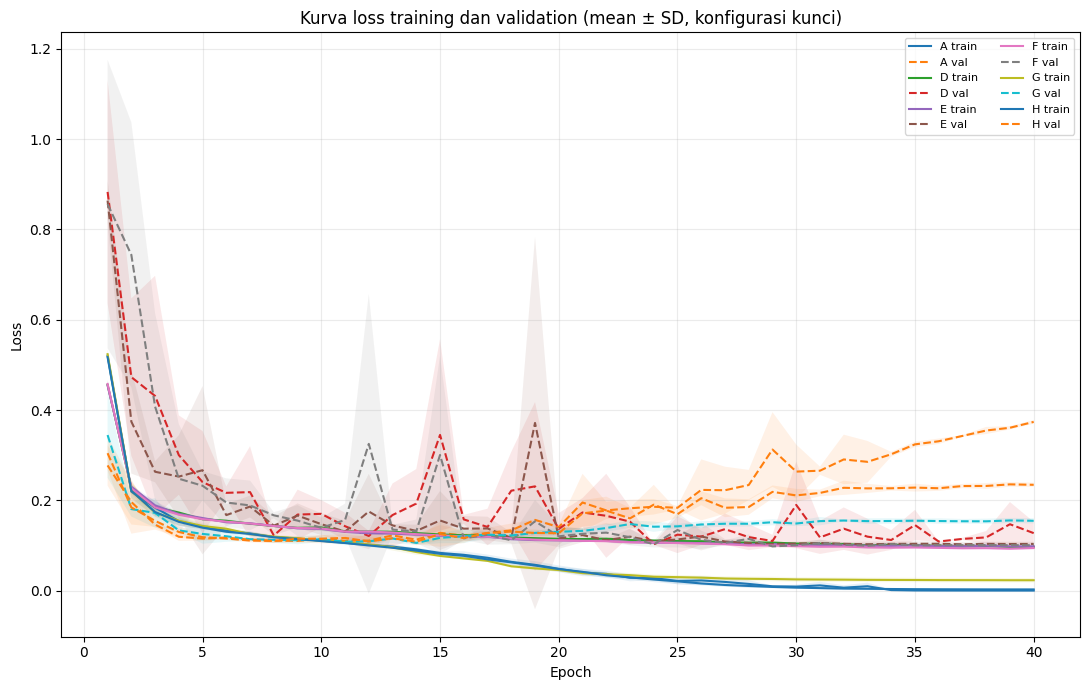

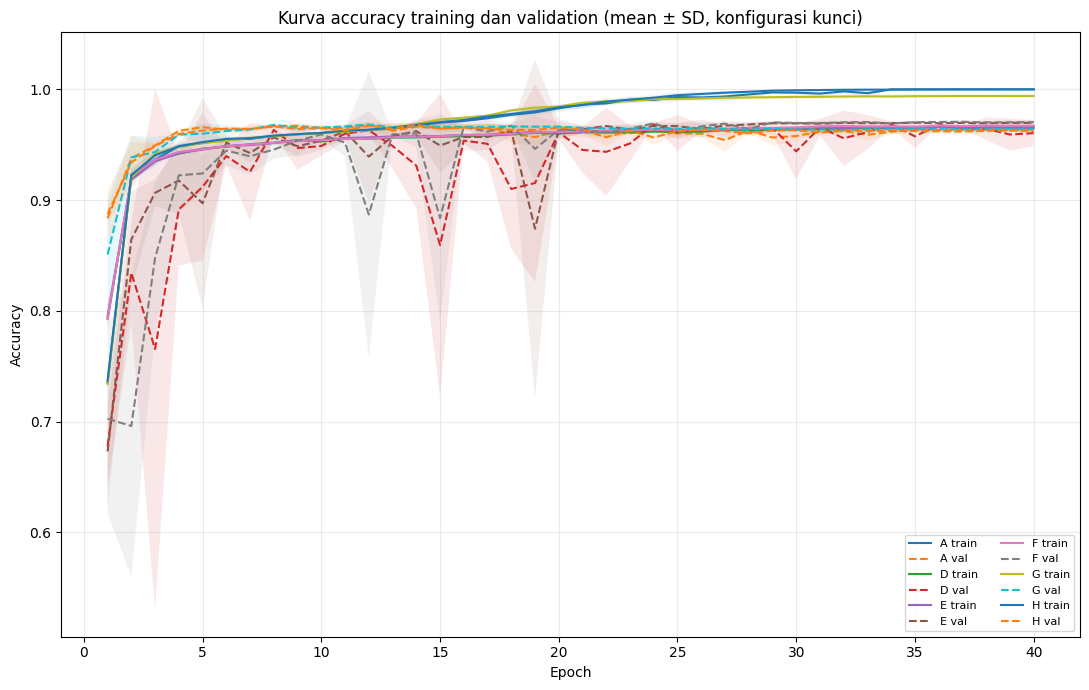

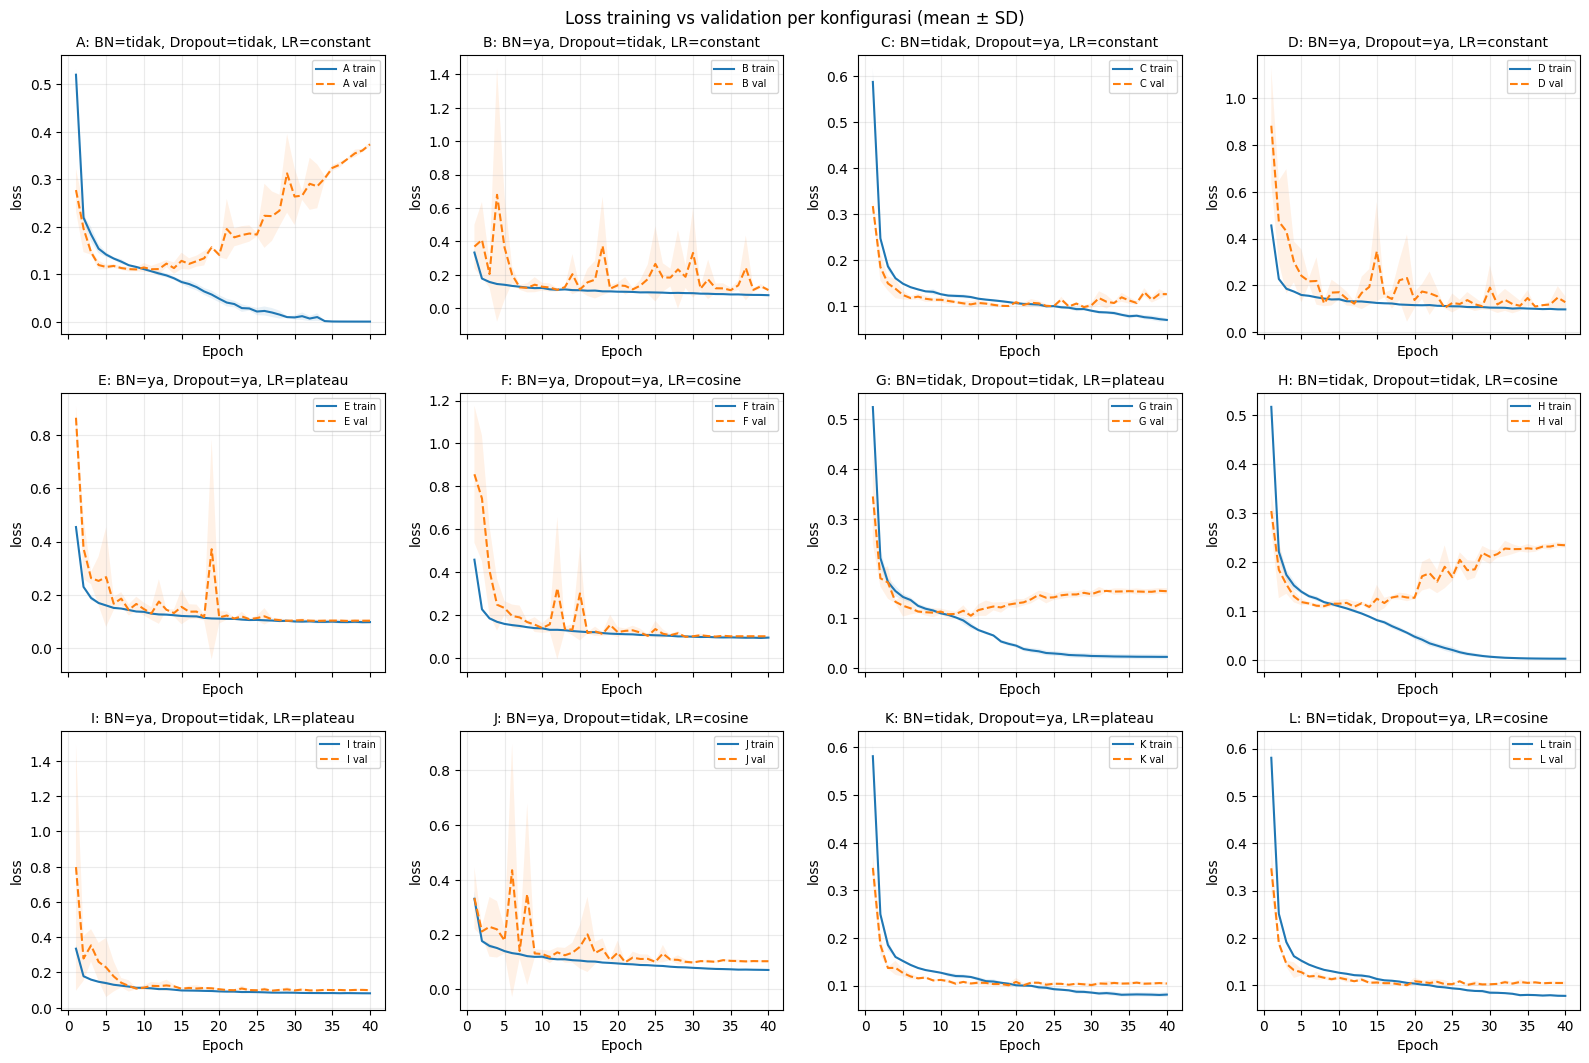

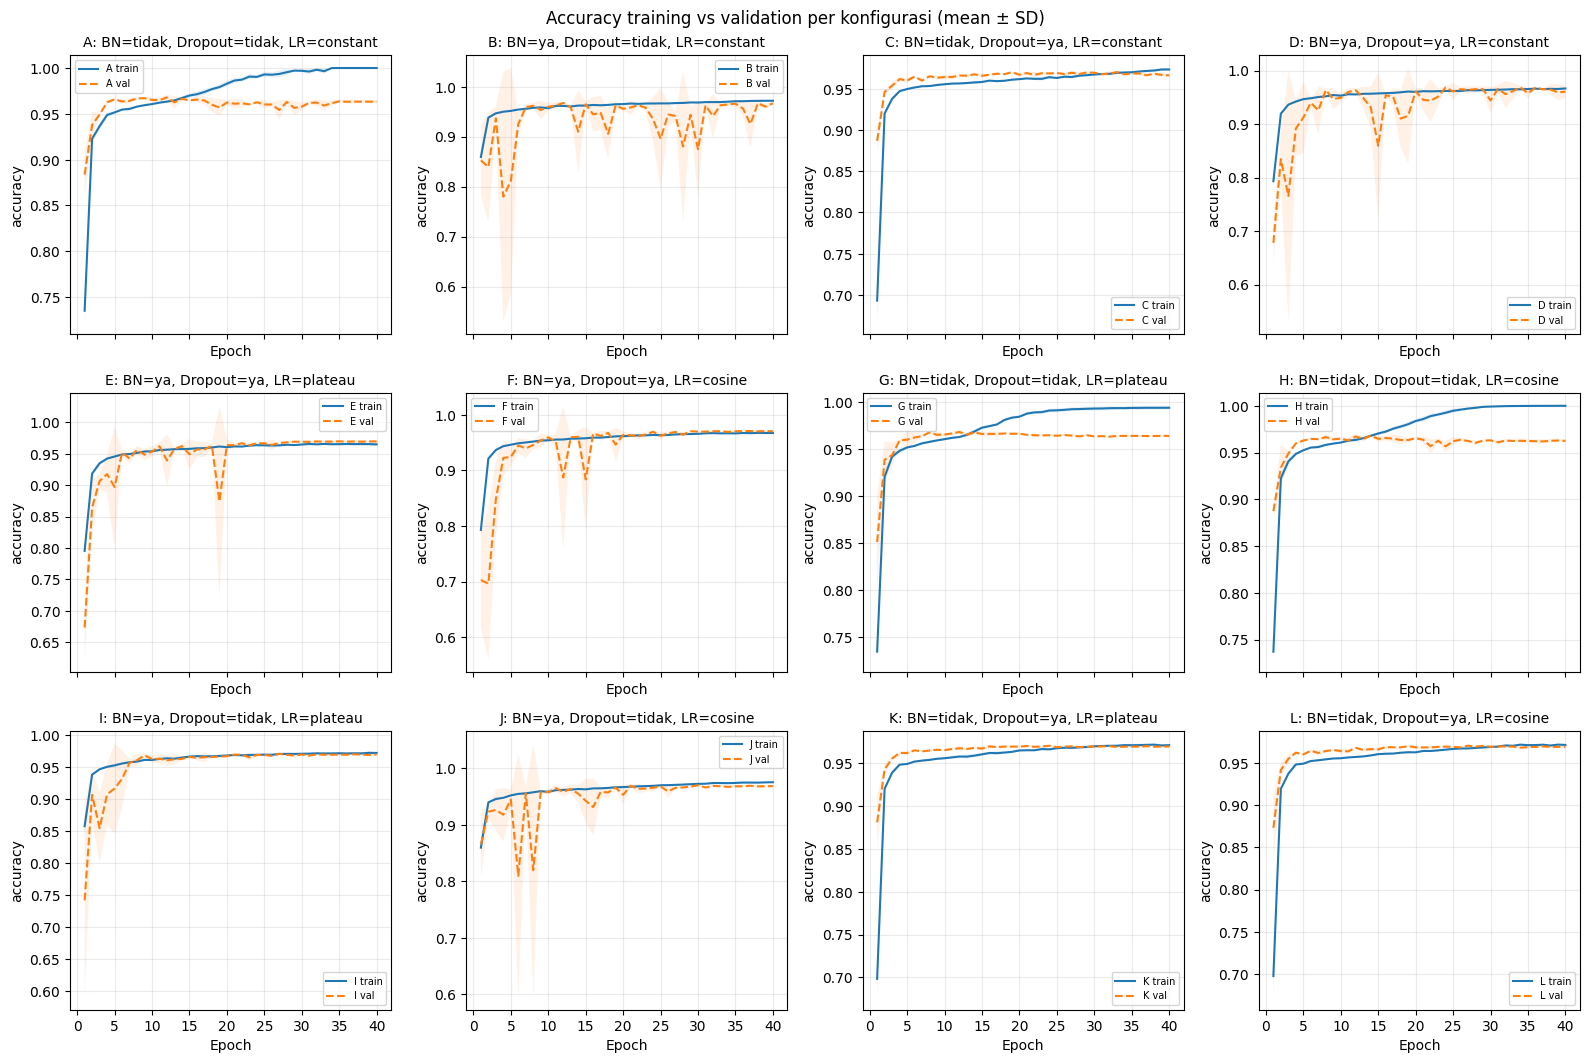

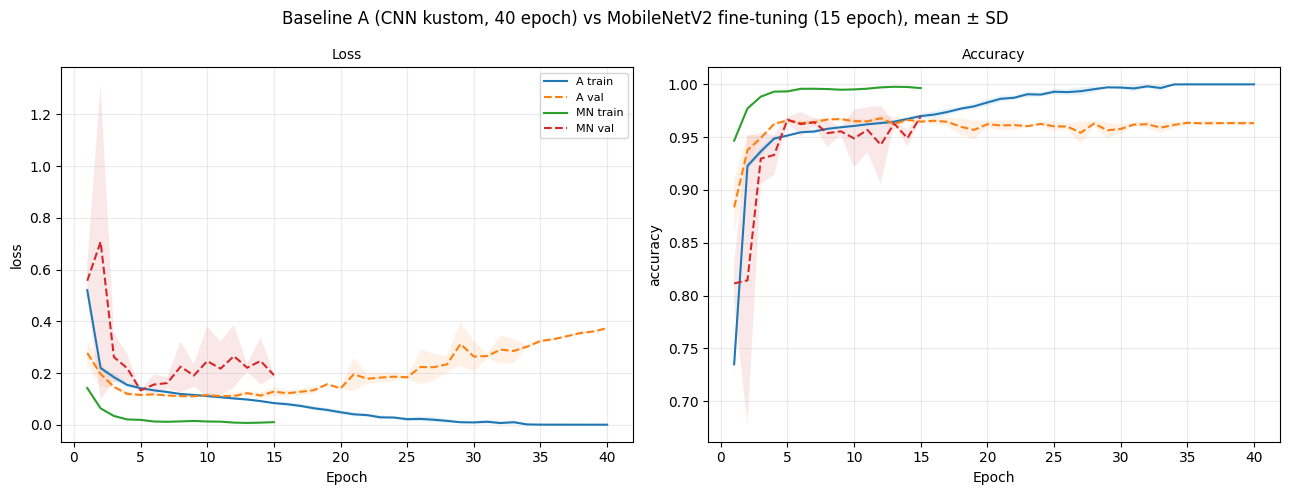

Model final: konfigurasi D, seed 2 (mean F1 test lintas seed: 0.9646)


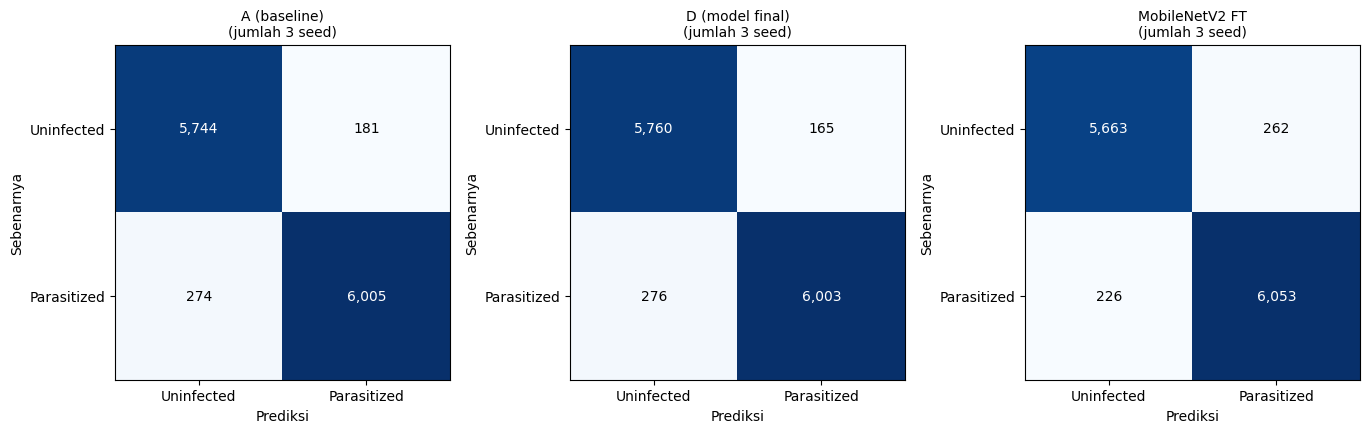

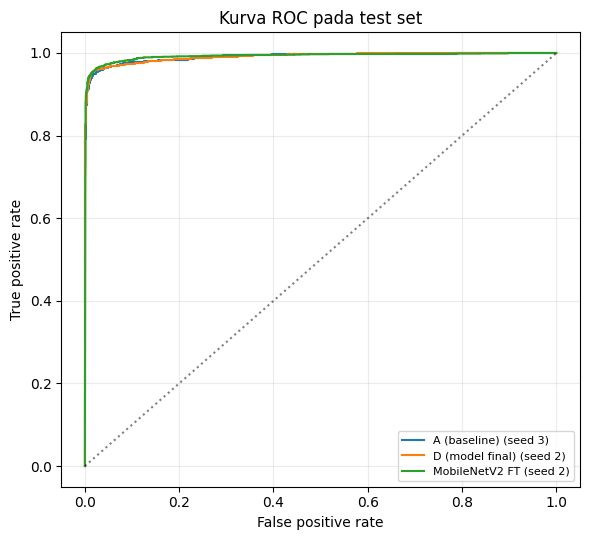

Contoh FP: 48 | contoh FN: 87
Contoh gambar disimpan di: /kaggle/working/malaria_cnn_experiment/error_examples/D_seed_2


In [ ]:
if not ALL_RUNS_DONE:
    print('Sel dilewati: pelatihan belum lengkap (lihat status run di sel sebelumnya). Jalankan notebook lagi di sesi baru sampai semua run selesai.')
else:
    from sklearn.metrics import roc_curve
    from matplotlib.ticker import MaxNLocator

    PLOT_CONFIGS = ["A", "D", "E", "F", "G", "H"]
    (OUTPUT_DIR / "plots").mkdir(exist_ok=True)

    def load_histories(names):
        out = {}
        for cfg in names:
            frames = []
            for seed in SEEDS:
                hp = OUTPUT_DIR / "runs" / f"{cfg}_seed_{seed}" / "history.csv"
                if hp.exists():
                    h = pd.read_csv(hp)
                    h["seed"] = int(seed)
                    frames.append(h)
            if frames:
                out[cfg] = pd.concat(frames, ignore_index=True)
        return out

    def draw_curves(ax, history_map, names, metric, title=None):
        for cfg in names:
            if cfg not in history_map:
                continue
            h = history_map[cfg]
            for prefix, style in [("", "-"), ("val_", "--")]:
                col = f"{prefix}{metric}"
                if col not in h.columns:
                    continue
                grouped = h.groupby("epoch")[col]
                mean, sd = grouped.mean(), grouped.std(ddof=1).fillna(0)
                ax.plot(mean.index.to_numpy(), mean.to_numpy(), linestyle=style, label=f"{cfg} {'val' if prefix else 'train'}")
                ax.fill_between(mean.index.to_numpy(), (mean - sd).to_numpy(), (mean + sd).to_numpy(), alpha=0.10)
        ax.set_xlabel("Epoch")
        ax.set_ylabel(metric)
        ax.xaxis.set_major_locator(MaxNLocator(integer=True))
        ax.grid(alpha=0.25)
        if title:
            ax.set_title(title, fontsize=10)

    # 1) Konfigurasi kunci (A, D, E, F, G, H)
    hist_key = load_histories([c for c in PLOT_CONFIGS if c in set(metrics_df.config)])
    for metric, ylabel, filename in [("loss", "Loss", "kurva_loss_konfigurasi.png"),
                                     ("accuracy", "Accuracy", "kurva_akurasi_konfigurasi.png")]:
        fig, ax = plt.subplots(figsize=(11, 7))
        draw_curves(ax, hist_key, PLOT_CONFIGS, metric)
        ax.set_ylabel(ylabel)
        ax.set_title(f"Kurva {ylabel.lower()} training dan validation (mean ± SD, konfigurasi kunci)")
        ax.legend(ncol=2, fontsize=8)
        fig.tight_layout()
        fig.savefig(OUTPUT_DIR / "plots" / filename, dpi=180)
        plt.show()
        plt.close(fig)

    # 2) Seluruh konfigurasi dalam grid
    present = [c for c in CONFIGS if c in set(metrics_df.config)]
    hist_all = load_histories(present)
    for metric, ylabel, filename in [("loss", "Loss", "kurva_loss_semua_konfigurasi.png"),
                                     ("accuracy", "Accuracy", "kurva_akurasi_semua_konfigurasi.png")]:
        ncols = 4
        nrows = int(np.ceil(len(present) / ncols))
        fig, axes = plt.subplots(nrows, ncols, figsize=(16, 3.6 * nrows), squeeze=False, sharex=True)
        for ax in axes.ravel():
            ax.axis("off")
        for ax, cfg in zip(axes.ravel(), present):
            ax.axis("on")
            c = CONFIGS[cfg]
            draw_curves(ax, hist_all, [cfg], metric, title=f"{cfg}: BN={'ya' if c['bn'] else 'tidak'}, Dropout={'ya' if c['dropout'] else 'tidak'}, LR={c['lr_mode']}")
            ax.legend(fontsize=7)
        fig.suptitle(f"{ylabel} training vs validation per konfigurasi (mean ± SD)")
        fig.tight_layout()
        fig.savefig(OUTPUT_DIR / "plots" / filename, dpi=150)
        plt.show()
        plt.close(fig)

    # 3) Baseline A vs MobileNetV2
    hist_base = load_histories(["A", MN_NAME])
    if len(hist_base) == 2:
        fig, axes = plt.subplots(1, 2, figsize=(13, 5))
        draw_curves(axes[0], hist_base, ["A", MN_NAME], "loss", "Loss")
        draw_curves(axes[1], hist_base, ["A", MN_NAME], "accuracy", "Accuracy")
        axes[0].legend(fontsize=8)
        fig.suptitle("Baseline A (CNN kustom, 40 epoch) vs MobileNetV2 fine-tuning (15 epoch), mean ± SD")
        fig.tight_layout()
        fig.savefig(OUTPUT_DIR / "plots" / "kurva_baseline_A_vs_MobileNetV2.png", dpi=170)
        plt.show()
        plt.close(fig)

    # 4) Model final (dipilih lewat validation pada sel sebelumnya)
    best_config = FINAL_CONFIG
    representative_seed = FINAL_SEED
    best_mean_f1 = float(summary_df.loc[summary_df.config == best_config, "f1_parasitized_mean"].iloc[0])
    print(f"Model final: konfigurasi {best_config}, seed {representative_seed} (mean F1 test lintas seed: {best_mean_f1:.4f})")

    # 5) Confusion matrix (dijumlahkan lintas seed) dan ROC (seed representatif)
    compare = [("A", "A (baseline)")]
    if best_config != "A":
        compare.append((best_config, f"{best_config} (model final)"))
    if (metrics_all_df.config == MN_NAME).any():
        compare.append((MN_NAME, "MobileNetV2 FT"))

    fig, axes = plt.subplots(1, len(compare), figsize=(4.6 * len(compare), 4.4), squeeze=False)
    for ax, (cfg, label) in zip(axes.ravel(), compare):
        g = metrics_all_df[metrics_all_df.config == cfg]
        cm = np.array([[g.tn.sum(), g.fp.sum()], [g.fn.sum(), g.tp.sum()]])
        ax.imshow(cm, cmap="Blues")
        for i in range(2):
            for j in range(2):
                ax.text(j, i, f"{int(cm[i, j]):,}", ha="center", va="center",
                        color="white" if cm[i, j] > cm.max() / 2 else "black")
        ax.set_xticks([0, 1]); ax.set_xticklabels(["Uninfected", "Parasitized"])
        ax.set_yticks([0, 1]); ax.set_yticklabels(["Uninfected", "Parasitized"])
        ax.set_xlabel("Prediksi"); ax.set_ylabel("Sebenarnya")
        ax.set_title(f"{label}\n(jumlah {len(g)} seed)", fontsize=10)
    fig.tight_layout()
    fig.savefig(OUTPUT_DIR / "plots" / "confusion_matrix_test.png", dpi=170)
    plt.show()
    plt.close(fig)

    fig, ax = plt.subplots(figsize=(6, 5.5))
    for cfg, label in compare:
        g = metrics_all_df[metrics_all_df.config == cfg]
        rep_seed = FINAL_SEED if cfg == FINAL_CONFIG else int(g.assign(d=(g.f1_parasitized - g.f1_parasitized.mean()).abs()).sort_values("d").iloc[0].seed)
        pr = pd.read_csv(OUTPUT_DIR / "runs" / f"{cfg}_seed_{rep_seed}" / "test_predictions.csv")
        fpr, tpr, _ = roc_curve(pr.y_true, pr.y_probability_parasitized)
        ax.plot(fpr, tpr, label=f"{label} (seed {rep_seed})")
    ax.plot([0, 1], [0, 1], "k:", alpha=0.5)
    ax.set_xlabel("False positive rate"); ax.set_ylabel("True positive rate")
    ax.set_title("Kurva ROC pada test set")
    ax.legend(fontsize=8); ax.grid(alpha=0.25)
    fig.tight_layout()
    fig.savefig(OUTPUT_DIR / "plots" / "roc_test.png", dpi=170)
    plt.show()
    plt.close(fig)

    # 6) Contoh kesalahan FP/FN dari model final
    rep_predictions = pd.read_csv(OUTPUT_DIR / "runs" / f"{best_config}_seed_{representative_seed}" / "test_predictions.csv")
    error_root = OUTPUT_DIR / "error_examples" / f"{best_config}_seed_{representative_seed}"
    for kind in ["FP", "FN"]:
        (error_root / kind).mkdir(parents=True, exist_ok=True)

    error_manifest = []
    MAX_EXAMPLES_PER_TYPE = 16
    for kind in ["FP", "FN"]:
        subset = rep_predictions.loc[rep_predictions.error_type == kind].copy()
        subset["confidence"] = subset.y_probability_parasitized if kind == "FP" else 1.0 - subset.y_probability_parasitized
        subset = subset.sort_values("confidence", ascending=False).head(MAX_EXAMPLES_PER_TYPE)
        for idx, row in enumerate(subset.itertuples(index=False), start=1):
            src = DATASET_ROOT / row.path
            out = error_root / kind / f"{kind}_{idx:02d}_{Path(row.path).stem}.png"
            with Image.open(src) as im:
                im.convert("RGB").save(out)
            error_manifest.append({"type": kind, "source_path": row.path, "saved_path": str(out.relative_to(OUTPUT_DIR)),
                                   "y_true": int(row.y_true), "probability": float(row.y_probability_parasitized)})

    pd.DataFrame(error_manifest).to_csv(error_root / "error_examples_manifest.csv", index=False)
    print("Contoh FP:", int((rep_predictions.error_type == "FP").sum()), "| contoh FN:", int((rep_predictions.error_type == "FN").sum()))
    print("Contoh gambar disimpan di:", error_root)

## 14. Fitur unik 1: Grad-CAM dengan deletion test

**Apa:** Grad-CAM membuat peta panas yang menunjukkan bagian citra yang paling mendukung keputusan model (kelas yang diprediksi), dihitung dari fitur konvolusi terakhir (sebelum Global Average Pooling) dan gradien skor kelas terhadapnya.

**Mengapa dibutuhkan:** model klasifikasi medis tidak boleh menjadi kotak hitam. Peta panas membantu menilai apakah model melihat sel dan parasit, bukan artefak latar atau tepi gambar.

**Bukti dampak (deletion test):** peta panas bisa tampak meyakinkan tetapi tidak benar-benar mencerminkan apa yang dipakai model. Karena itu diuji: area paling panas ditutup (diisi warna rata-rata citra) lalu penurunan keyakinan pada kelas yang semula diprediksi diukur. Pembandingnya adalah penutupan area acak dengan luas yang sama pada citra yang sama. Bila penurunan akibat area Grad-CAM jauh lebih besar dari area acak, peta panas terbukti menunjuk bagian yang benar-benar dipakai model. Diuji pada 250 citra per kelas dari test set (seed pengacakan tetap) untuk beberapa luas penutupan (5–50% area). Keterbatasan: area acak dipilih dari sel-sel peta panas secara terpisah-pisah (tidak menyatu), dan tidak ada anotasi parasit sebagai kebenaran dasar sehingga ini bukti perilaku model, bukan bukti lokalisasi medis.

**Keluaran:** `tables/gradcam_deletion_test.csv`, `plots/gradcam_deletion_curve.png`, `plots/gradcam_examples.png` (TP, TN, FP, FN), dan fungsi `compute_gradcam` yang bisa dipakai ulang untuk demo.

Deletion test pada 500 citra test (model final D, seed 2):


,mask_fraction,n_images,mean_drop_gradcam,sd_drop_gradcam,mean_drop_random,sd_drop_random,mean_paired_diff_gradcam_minus_random,pct_images_gradcam_drop_larger,label_flip_rate_gradcam_pct,label_flip_rate_random_pct
0,0.05,500,0.399446,0.446217,0.004893,0.018219,0.394553,85.8,42.2,0.4
1,0.10,500,0.459462,0.460683,0.011130,0.038935,0.448332,88.8,48.4,0.8
2,0.20,500,0.487324,0.463324,0.020575,0.063907,0.466748,92.8,49.4,1.6
3,0.30,500,0.498525,0.457714,0.034329,0.098626,0.464196,94.4,50.2,2.4
4,0.50,500,0.506771,0.443059,0.078552,0.192046,0.428219,97.4,50.2,6.8


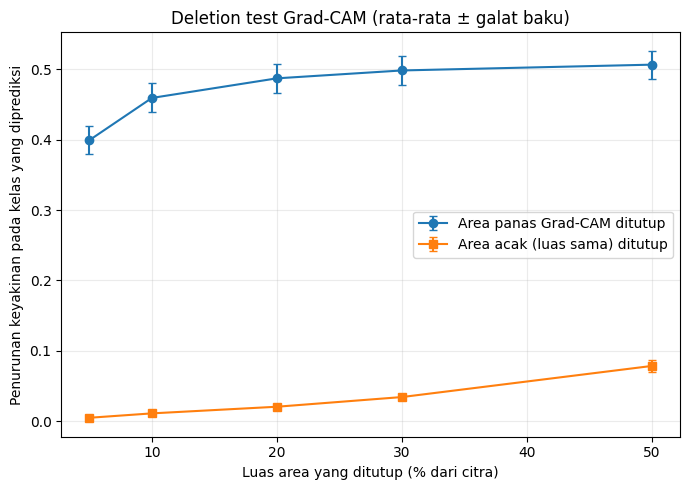

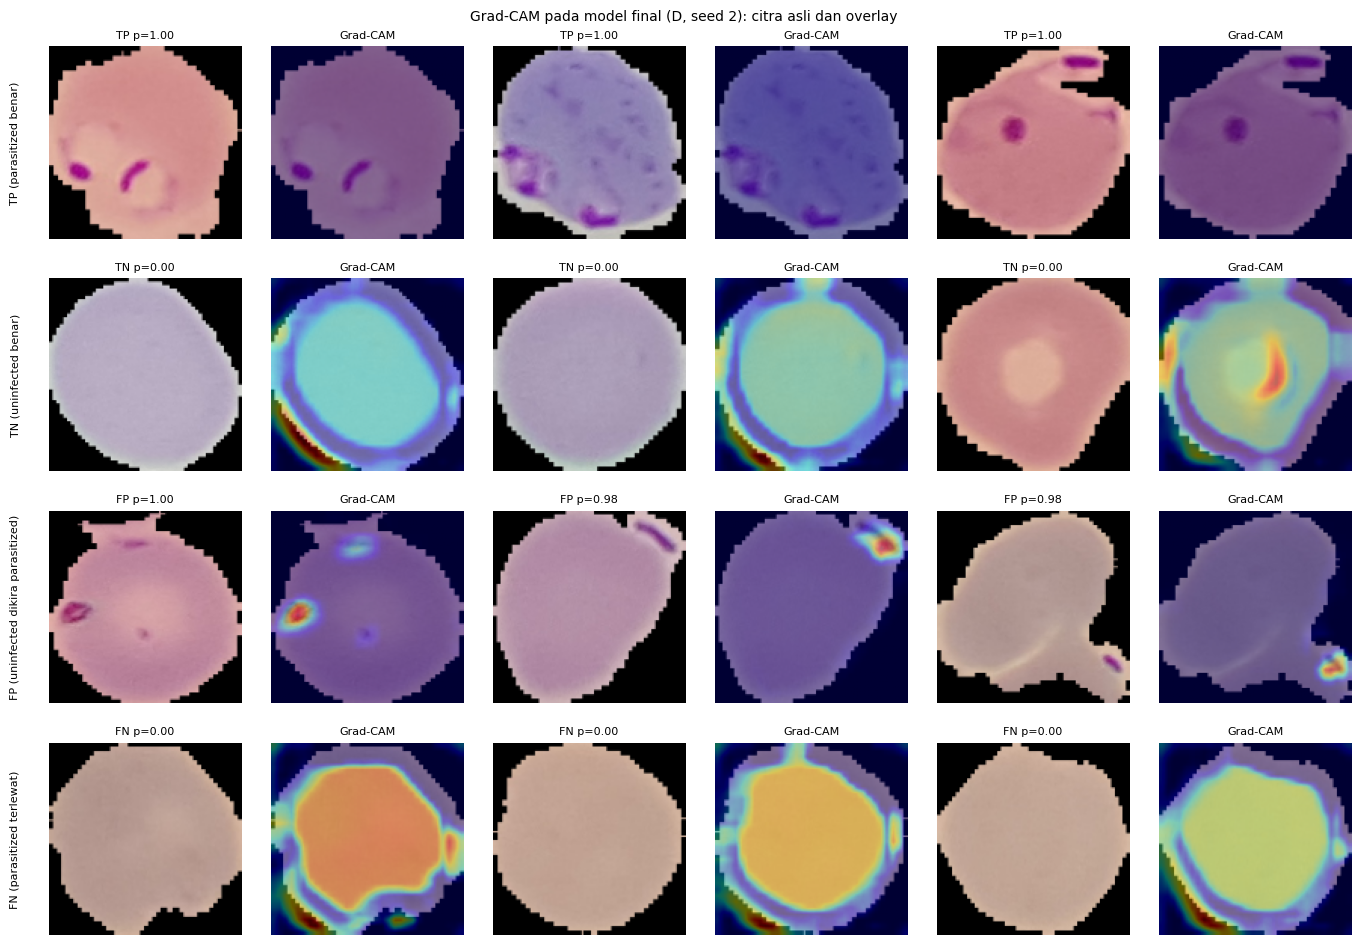

Grad-CAM menurunkan keyakinan lebih besar daripada area acak pada 5 dari 5 luas penutupan.


In [ ]:
if not ALL_RUNS_DONE:
    print('Sel dilewati: pelatihan belum lengkap (lihat status run di sel sebelumnya). Jalankan notebook lagi di sesi baru sampai semua run selesai.')
else:
    GRADCAM_FRACTIONS = [0.05, 0.10, 0.20, 0.30, 0.50]
    DELETION_N_PER_CLASS = 40 if SMOKE_TEST else 250
    GRADCAM_BATCH = 50

    test_dataset_ready()
    gradcam_final_model = build_model_for_spec(RUN_SPECS[FINAL_CONFIG], pretrained=False)
    gradcam_final_model.load_weights(str(FINAL_RUN_DIR / "best.weights.h5"))

    # --- AWAL FUNGSI GRADCAM TF
    def build_gradcam_model(model):
        # Secara dinamis mencari lapisan Conv2D paling terakhir pada arsitektur apa pun
        last_conv_layer = [l for l in model.layers if isinstance(l, tf.keras.layers.Conv2D)][-1]

        # Mencari lapisan Activation (ReLU) yang mengikutinya (setelah opsi BatchNormalization)
        conv_idx = model.layers.index(last_conv_layer)
        target_layer = last_conv_layer
        for i in range(conv_idx, len(model.layers)):
            if isinstance(model.layers[i], tf.keras.layers.Activation):
                target_layer = model.layers[i]
                break

        return tf.keras.Model(inputs=model.inputs, outputs=[target_layer.output, model.output])


    def compute_gradcam(grad_model, x_float, sign):
        # sign = +1 bila model memprediksi parasitized, -1 bila uninfected (peta = bukti untuk kelas yang diprediksi).
        x = tf.convert_to_tensor(x_float, dtype=tf.float32)
        s = tf.convert_to_tensor(sign, dtype=tf.float32)
        with tf.GradientTape() as tape:
            conv, pred = grad_model(x, training=False)
            score = pred[:, 0] * s
        grads = tape.gradient(score, conv)
        weights = tf.reduce_mean(grads, axis=(1, 2))
        cam = tf.nn.relu(tf.einsum("bhwc,bc->bhw", conv, weights)).numpy()
        cam = cam / (cam.max(axis=(1, 2), keepdims=True) + 1e-8)
        return cam.astype(np.float32)
    # --- AKHIR FUNGSI GRADCAM TF

    gradcam_model = build_gradcam_model(gradcam_final_model)


    def predict_probs(x_float):
        return np.asarray(gradcam_final_model.predict(x_float, batch_size=BATCH_SIZE, verbose=0)).reshape(-1)


    def gradcam_for(x_float, sign):
        out = []
        for i in range(0, len(x_float), GRADCAM_BATCH):
            out.append(compute_gradcam(gradcam_model, x_float[i:i + GRADCAM_BATCH], sign[i:i + GRADCAM_BATCH]))
        return np.concatenate(out, axis=0)


    def mask_images(x, order, fraction, cam_hw):
        """Tutup `fraction` sel peta teratas (menurut `order`) dengan warna rata-rata tiap citra."""
        n, h, w = x.shape[0], cam_hw[0], cam_hw[1]
        k = max(1, int(round(fraction * h * w)))
        low = np.zeros((n, h * w), dtype=np.float32)
        low[np.arange(n)[:, None], order[:, :k]] = 1.0
        low = low.reshape(n, h, w)
        scale = x.shape[1] // h
        m = np.repeat(np.repeat(low, scale, axis=1), scale, axis=2)[..., None]
        mean_color = x.mean(axis=(1, 2), keepdims=True)
        return x * (1.0 - m) + mean_color * m


    # ---------------------------------------------------------------- deletion test
    rng = np.random.RandomState(2026)
    idx_pos, idx_neg = np.where(TEST_Y == 1)[0], np.where(TEST_Y == 0)[0]
    sample_idx = np.concatenate([
        rng.choice(idx_pos, size=min(DELETION_N_PER_CLASS, len(idx_pos)), replace=False),
        rng.choice(idx_neg, size=min(DELETION_N_PER_CLASS, len(idx_neg)), replace=False)])
    x_s = TEST_X[sample_idx].astype(np.float32) / 255.0
    p_s = predict_probs(x_s)
    pred_cls = (p_s >= THRESHOLD).astype(int)
    conf_orig = np.where(pred_cls == 1, p_s, 1.0 - p_s)
    cams = gradcam_for(x_s, np.where(pred_cls == 1, 1.0, -1.0))
    cam_hw = cams.shape[1:3]
    n_img = len(x_s)
    flat = cams.reshape(n_img, -1)
    order_cam = np.argsort(-(flat + 1e-6 * rng.rand(*flat.shape)), axis=1, kind="stable")   # jitter: tie acak, bukan bias pojok
    order_rand = np.stack([rng.permutation(flat.shape[1]) for _ in range(n_img)])

    def conf_in_pred_class(x_masked):
        p = predict_probs(x_masked)
        return np.where(pred_cls == 1, p, 1.0 - p), (p >= THRESHOLD).astype(int)

    rows = []
    for frac in GRADCAM_FRACTIONS:
        c_g, lab_g = conf_in_pred_class(mask_images(x_s, order_cam, frac, cam_hw))
        c_r, lab_r = conf_in_pred_class(mask_images(x_s, order_rand, frac, cam_hw))
        drop_g, drop_r = conf_orig - c_g, conf_orig - c_r
        rows.append({
            "mask_fraction": frac, "n_images": n_img,
            "mean_drop_gradcam": float(drop_g.mean()), "sd_drop_gradcam": float(drop_g.std(ddof=1)),
            "mean_drop_random": float(drop_r.mean()), "sd_drop_random": float(drop_r.std(ddof=1)),
            "mean_paired_diff_gradcam_minus_random": float((drop_g - drop_r).mean()),
            "pct_images_gradcam_drop_larger": float(np.mean(drop_g > drop_r) * 100),
            "label_flip_rate_gradcam_pct": float(np.mean(lab_g != pred_cls) * 100),
            "label_flip_rate_random_pct": float(np.mean(lab_r != pred_cls) * 100),
        })
    deletion_df = pd.DataFrame(rows)
    deletion_df.to_csv(OUTPUT_DIR / "tables" / "gradcam_deletion_test.csv", index=False)
    print(f"Deletion test pada {n_img} citra test (model final {FINAL_CONFIG}, seed {FINAL_SEED}):")
    display(deletion_df)

    fig, ax = plt.subplots(figsize=(7, 5))
    fr = deletion_df.mask_fraction * 100
    ax.errorbar(fr, deletion_df.mean_drop_gradcam, yerr=deletion_df.sd_drop_gradcam / np.sqrt(n_img), marker="o", capsize=3, label="Area panas Grad-CAM ditutup")
    ax.errorbar(fr, deletion_df.mean_drop_random, yerr=deletion_df.sd_drop_random / np.sqrt(n_img), marker="s", capsize=3, label="Area acak (luas sama) ditutup")
    ax.set_xlabel("Luas area yang ditutup (% dari citra)")
    ax.set_ylabel("Penurunan keyakinan pada kelas yang diprediksi")
    ax.set_title("Deletion test Grad-CAM (rata-rata ± galat baku)")
    ax.grid(alpha=0.25); ax.legend()
    fig.tight_layout()
    fig.savefig(OUTPUT_DIR / "plots" / "gradcam_deletion_curve.png", dpi=170)
    plt.show()
    plt.close(fig)

    # ---------------------------------------------------------------- contoh peta panas: TP, TN, FP, FN
    pred_df = pd.read_csv(FINAL_RUN_DIR / "test_predictions.csv")
    pred_df["confidence"] = np.where(pred_df.y_pred == 1, pred_df.y_probability_parasitized, 1.0 - pred_df.y_probability_parasitized)
    pred_df["category"] = np.select(
        [(pred_df.y_true == 1) & (pred_df.y_pred == 1), (pred_df.y_true == 0) & (pred_df.y_pred == 0),
         (pred_df.y_true == 0) & (pred_df.y_pred == 1), (pred_df.y_true == 1) & (pred_df.y_pred == 0)],
        ["TP", "TN", "FP", "FN"], default="?")
    EX_PER_CAT = 3
    cat_titles = {"TP": "TP (parasitized benar)", "TN": "TN (uninfected benar)", "FP": "FP (uninfected dikira parasitized)", "FN": "FN (parasitized terlewat)"}
    fig, axes = plt.subplots(4, 2 * EX_PER_CAT, figsize=(2.3 * 2 * EX_PER_CAT, 9.6), squeeze=False)
    for ax in axes.ravel():
        ax.axis("off")
    example_rows = []
    jet = plt.get_cmap("jet")
    for r, cat in enumerate(["TP", "TN", "FP", "FN"]):
        sub = pred_df[pred_df.category == cat].sort_values("confidence", ascending=False).head(EX_PER_CAT)
        if sub.empty:
            axes[r, 0].text(0, 0.5, f"{cat}: tidak ada contoh", fontsize=9)
            continue
        xi = TEST_X[sub.index.values].astype(np.float32) / 255.0
        pc = (sub.y_pred.values == 1)
        cam_i = gradcam_for(xi, np.where(pc, 1.0, -1.0))
        for j in range(len(sub)):
            scale = IMAGE_SIZE // cam_i.shape[1]
            cam_up = np.asarray(Image.fromarray((cam_i[j] * 255).astype(np.uint8)).resize((IMAGE_SIZE, IMAGE_SIZE), Image.BILINEAR), dtype=np.float32) / 255.0
            overlay = 0.6 * xi[j] + 0.4 * jet(cam_up)[..., :3]
            a0, a1 = axes[r, 2 * j], axes[r, 2 * j + 1]
            a0.imshow(xi[j]); a0.axis("off")
            a1.imshow(np.clip(overlay, 0, 1)); a1.axis("off")
            a0.set_title(f"{cat} p={sub.y_probability_parasitized.values[j]:.2f}", fontsize=8)
            a1.set_title("Grad-CAM", fontsize=8)
            example_rows.append({"category": cat, "path": sub.path.values[j], "probability_parasitized": float(sub.y_probability_parasitized.values[j])})
        axes[r, 0].text(-0.15, 0.5, cat_titles[cat], transform=axes[r, 0].transAxes, rotation=90, va="center", ha="right", fontsize=8)
    fig.suptitle(f"Grad-CAM pada model final ({FINAL_CONFIG}, seed {FINAL_SEED}): citra asli dan overlay", fontsize=10)
    fig.tight_layout()
    fig.savefig(OUTPUT_DIR / "plots" / "gradcam_examples.png", dpi=170)
    plt.show()
    plt.close(fig)
    pd.DataFrame(example_rows).to_csv(OUTPUT_DIR / "tables" / "gradcam_examples_manifest.csv", index=False)

    _better = int((deletion_df.mean_paired_diff_gradcam_minus_random > 0).sum())
    print(f"Grad-CAM menurunkan keyakinan lebih besar daripada area acak pada {_better} dari {len(deletion_df)} luas penutupan.")
    del gradcam_final_model, gradcam_model
    tf.keras.backend.clear_session()

## 15. Fitur unik 2: Kalibrasi keyakinan dan ambang "Tidak yakin"

**Apa:** (a) *Temperature scaling*: satu angka T dipelajari dari data validation untuk menyesuaikan keyakinan model agar sesuai dengan akurasi sebenarnya (`p_kalibrasi = sigmoid(logit / T)`); urutan prediksi tidak berubah, jadi F1/AUC tetap. (b) Ambang keyakinan τ: prediksi dengan keyakinan di bawah τ dikeluarkan sebagai **"Tidak yakin"** dan dirujuk ke pemeriksaan manual.

**Mengapa:** CNN umumnya terlalu percaya diri. Dalam skrining malaria, prediksi salah yang meyakinkan lebih berbahaya daripada model yang tahu kapan harus ragu.

**Bukti dampak:** ECE (Expected Calibration Error, 10 bin), NLL dan Brier sebelum vs sesudah kalibrasi pada validation dan test; diagram keandalan; serta tabel/kurva *coverage–accuracy* (berapa persen citra tetap diputuskan otomatis dan seberapa akurat sebagian itu). T dan τ **dipilih hanya dari validation** (τ = τ terkecil yang membuat akurasi pada citra yang diterima ≥ target, dengan minimal 50 citra diterima); test hanya dipakai untuk melaporkan. Target 0,98 adalah pilihan kami dan bukan hasil tuning pada test.

**Keluaran:** `tables/calibration_summary.csv`, `tables/selective_prediction.csv`, `plots/reliability_diagram.png`, `plots/risk_coverage_curve.png`, `final_model/calibration.json`, dan fungsi `predict_with_confidence`.

Temperature T (dari validation) = 1.215  (T>1 berarti model semula terlalu percaya diri)
Kalibrasi (T hanya dipelajari dari validation):


,split,kalibrasi,ECE,NLL,Brier,accuracy,mean_confidence
0,validation,sebelum,0.009378,0.094897,0.023658,0.971494,0.979261
1,validation,sesudah,0.003249,0.091828,0.023559,0.971494,0.970547
2,test,sebelum,0.013837,0.112853,0.027938,0.966814,0.977319
3,test,sesudah,0.009051,0.107524,0.027801,0.966814,0.968175


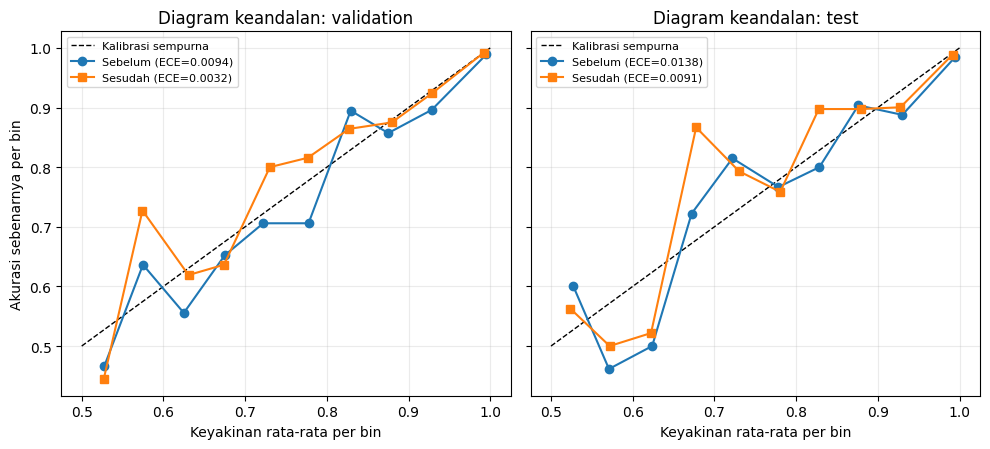

Ambang keyakinan terpilih (dari validation): tau = 0.755  [tau terkecil di validation dengan akurasi diterima >= 0.98]


,split,tau,coverage,n_accepted,accuracy_accepted,recall_parasitized_accepted,errors_accepted,errors_referred,fn_referred
51,validation,0.755,0.972767,3822,0.980638,0.973741,74,38,22
151,test,0.755,0.970747,3949,0.975437,0.962782,97,38,11


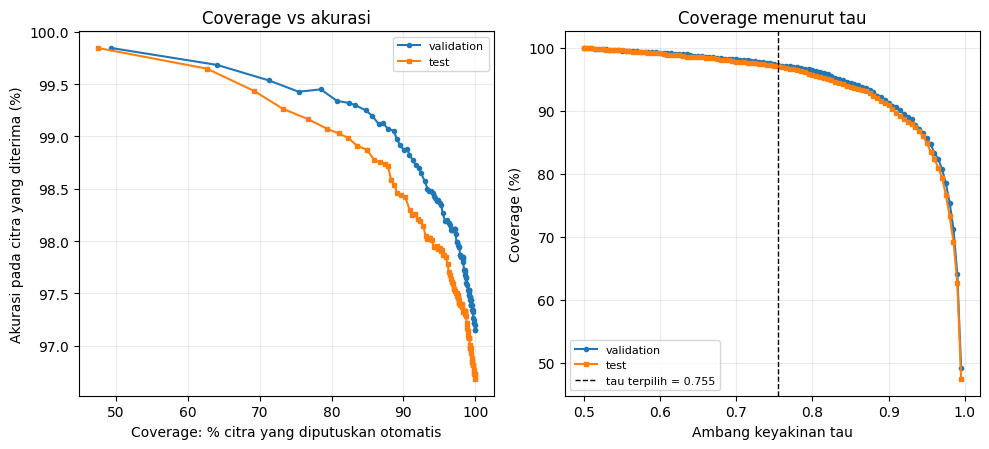

Keputusan pada test: {'Parasitized': 1987, 'Uninfected': 1962, 'Tidak yakin': 119}


In [ ]:
if not ALL_RUNS_DONE:
    print('Sel dilewati: pelatihan belum lengkap (lihat status run di sel sebelumnya). Jalankan notebook lagi di sesi baru sampai semua run selesai.')
else:
    CONFIDENCE_TARGET_ACCURACY = 0.98
    MIN_ACCEPTED = 50
    TAU_GRID = np.round(np.arange(0.50, 0.9951, 0.005), 3)

    _vp = pd.read_csv(FINAL_RUN_DIR / "val_predictions.csv")
    _tp = pd.read_csv(FINAL_RUN_DIR / "test_predictions.csv")
    yv, pv = _vp.y_true.values.astype(int), _vp.y_probability_parasitized.values.astype(np.float64)
    yt, pt = _tp.y_true.values.astype(int), _tp.y_probability_parasitized.values.astype(np.float64)

    EPS = 1e-7
    def to_logit(p):
        p = np.clip(p, EPS, 1 - EPS)
        return np.log(p / (1 - p))

    def apply_temperature(p, T):
        return 1.0 / (1.0 + np.exp(-to_logit(p) / T))

    def nll(y, p):
        p = np.clip(p, EPS, 1 - EPS)
        return float(-np.mean(y * np.log(p) + (1 - y) * np.log(1 - p)))

    def brier(y, p):
        return float(np.mean((p - y) ** 2))

    def ece_binary(y, p, n_bins=10):
        # confidence = peluang kelas yang diprediksi, jadi rentang 0.5-1
        pred = (p >= THRESHOLD).astype(int)
        conf = np.where(pred == 1, p, 1 - p)
        correct = (pred == y).astype(float)
        edges = np.linspace(0.5, 1.0, n_bins + 1)
        idx = np.clip(np.digitize(conf, edges[1:-1]), 0, n_bins - 1)
        ece, rows = 0.0, []
        for b in range(n_bins):
            m = idx == b
            if m.any():
                ece += m.mean() * abs(correct[m].mean() - conf[m].mean())
                rows.append((b, int(m.sum()), float(conf[m].mean()), float(correct[m].mean())))
        return float(ece), rows

    # ---- cari T di validation (grid log T, minimalkan NLL)
    _grid = np.exp(np.linspace(np.log(0.25), np.log(8.0), 400))
    TEMPERATURE = float(_grid[int(np.argmin([nll(yv, apply_temperature(pv, t)) for t in _grid]))])
    pv_cal, pt_cal = apply_temperature(pv, TEMPERATURE), apply_temperature(pt, TEMPERATURE)
    print(f"Temperature T (dari validation) = {TEMPERATURE:.3f}  (T>1 berarti model semula terlalu percaya diri)")

    cal_rows = []
    for split, y, p_raw, p_cal in [("validation", yv, pv, pv_cal), ("test", yt, pt, pt_cal)]:
        for state, p in [("sebelum", p_raw), ("sesudah", p_cal)]:
            e, _ = ece_binary(y, p)
            cal_rows.append({"split": split, "kalibrasi": state, "ECE": e, "NLL": nll(y, p), "Brier": brier(y, p),
                             "accuracy": float(np.mean((p >= THRESHOLD).astype(int) == y)),
                             "mean_confidence": float(np.mean(np.where(p >= THRESHOLD, p, 1 - p)))})
    cal_df = pd.DataFrame(cal_rows)
    cal_df.to_csv(OUTPUT_DIR / "tables" / "calibration_summary.csv", index=False)
    print("Kalibrasi (T hanya dipelajari dari validation):")
    display(cal_df)

    # ---- diagram keandalan
    fig, axes = plt.subplots(1, 2, figsize=(10, 4.6), sharey=True)
    for ax, (split, y, p_raw, p_cal) in zip(axes, [("validation", yv, pv, pv_cal), ("test", yt, pt, pt_cal)]):
        ax.plot([0.5, 1], [0.5, 1], "k--", lw=1, label="Kalibrasi sempurna")
        for p, lab, mk in [(p_raw, "Sebelum", "o"), (p_cal, "Sesudah", "s")]:
            e, rows = ece_binary(y, p)
            if rows:
                ax.plot([r[2] for r in rows], [r[3] for r in rows], marker=mk, label=f"{lab} (ECE={e:.4f})")
        ax.set_title(f"Diagram keandalan: {split}")
        ax.set_xlabel("Keyakinan rata-rata per bin")
        ax.grid(alpha=0.25); ax.legend(fontsize=8)
    axes[0].set_ylabel("Akurasi sebenarnya per bin")
    fig.tight_layout()
    fig.savefig(OUTPUT_DIR / "plots" / "reliability_diagram.png", dpi=170)
    plt.show()
    plt.close(fig)

    # ---- prediksi selektif
    def selective_table(y, p, split):
        pred = (p >= THRESHOLD).astype(int)
        conf = np.where(pred == 1, p, 1 - p)
        rows = []
        for tau in TAU_GRID:
            a = conf >= tau
            n = int(a.sum())
            rows.append({"split": split, "tau": float(tau), "coverage": n / len(y), "n_accepted": n,
                         "accuracy_accepted": float(np.mean(pred[a] == y[a])) if n else np.nan,
                         "recall_parasitized_accepted": float(np.mean(pred[a & (y == 1)] == 1)) if (a & (y == 1)).any() else np.nan,
                         "errors_accepted": int(np.sum(pred[a] != y[a])),
                         "errors_referred": int(np.sum(pred[~a] != y[~a])),
                         "fn_referred": int(np.sum((pred[~a] == 0) & (y[~a] == 1)))})
        return pd.DataFrame(rows)

    sel_val = selective_table(yv, pv_cal, "validation")
    sel_test = selective_table(yt, pt_cal, "test")
    _ok = sel_val[(sel_val.accuracy_accepted >= CONFIDENCE_TARGET_ACCURACY) & (sel_val.n_accepted >= MIN_ACCEPTED)]
    if len(_ok):
        CONFIDENCE_TAU = float(_ok.tau.min()); _rule = f"tau terkecil di validation dengan akurasi diterima >= {CONFIDENCE_TARGET_ACCURACY}"
    else:
        CONFIDENCE_TAU = 0.90; _rule = "FALLBACK 0.90: target akurasi tidak tercapai di validation"
        print("PERINGATAN: target akurasi tidak tercapai pada validation; memakai tau = 0.90.")
    selective_df = pd.concat([sel_val, sel_test], ignore_index=True)
    selective_df.to_csv(OUTPUT_DIR / "tables" / "selective_prediction.csv", index=False)
    print(f"Ambang keyakinan terpilih (dari validation): tau = {CONFIDENCE_TAU}  [{_rule}]")
    display(selective_df[np.isclose(selective_df.tau, CONFIDENCE_TAU)])

    fig, axes = plt.subplots(1, 2, figsize=(10, 4.6))
    for split, sel, mk in [("validation", sel_val, "o"), ("test", sel_test, "s")]:
        axes[0].plot(sel.coverage * 100, sel.accuracy_accepted * 100, marker=mk, ms=3, label=split)
        axes[1].plot(sel.tau, sel.coverage * 100, marker=mk, ms=3, label=split)
    axes[0].set_xlabel("Coverage: % citra yang diputuskan otomatis"); axes[0].set_ylabel("Akurasi pada citra yang diterima (%)")
    axes[0].set_title("Coverage vs akurasi")
    axes[1].axvline(CONFIDENCE_TAU, color="k", ls="--", lw=1, label=f"tau terpilih = {CONFIDENCE_TAU}")
    axes[1].set_xlabel("Ambang keyakinan tau"); axes[1].set_ylabel("Coverage (%)"); axes[1].set_title("Coverage menurut tau")
    for ax in axes:
        ax.grid(alpha=0.25); ax.legend(fontsize=8)
    fig.tight_layout()
    fig.savefig(OUTPUT_DIR / "plots" / "risk_coverage_curve.png", dpi=170)
    plt.show()
    plt.close(fig)

    # ---- fungsi pemakaian + simpan
    def predict_with_confidence(prob_raw, T=TEMPERATURE, tau=CONFIDENCE_TAU):
        """prob_raw: peluang parasitized mentah dari model. Mengembalikan label teks per citra."""
        p = apply_temperature(np.atleast_1d(np.asarray(prob_raw, dtype=np.float64)), T)
        pred = (p >= THRESHOLD).astype(int)
        conf = np.where(pred == 1, p, 1 - p)
        labels = np.where(conf < tau, "Tidak yakin", np.where(pred == 1, "Parasitized", "Uninfected"))
        return labels, conf

    _lab, _conf = predict_with_confidence(pt)
    demo = pd.DataFrame({"path": _tp.path, "y_true": yt, "prob_raw": pt, "keyakinan_kalibrasi": _conf, "keputusan": _lab})
    demo.to_csv(OUTPUT_DIR / "tables" / "confidence_decisions_test.csv", index=False)
    print("Keputusan pada test:", demo.keputusan.value_counts().to_dict())

    _tr = sel_test[np.isclose(sel_test.tau, CONFIDENCE_TAU)].iloc[0]
    save_json(OUTPUT_DIR / "final_model" / "calibration.json", {
        "config": FINAL_CONFIG, "seed": FINAL_SEED, "temperature": TEMPERATURE, "tau": CONFIDENCE_TAU, "tau_rule": _rule,
        "target_accuracy": CONFIDENCE_TARGET_ACCURACY, "fitted_on": "validation",
        "test_at_tau": {k: (None if pd.isna(_tr[k]) else float(_tr[k])) for k in ["coverage", "accuracy_accepted", "recall_parasitized_accepted", "errors_referred", "fn_referred"]},
    })

## 16. Catatan reproducibility dan ringkasan akhir

Notebook menyimpan versi pustaka, perangkat, platform, split manifest, pengaturan eksperimen, metadata tiap run (termasuk run yang dilanjutkan dan platformnya), dan tabel hasil. File utama untuk laporan: `tables/summary_by_configuration_with_cost.csv`, `tables/planned_pairwise_comparisons.csv`, `tables/anova_three_way_F1.csv`, `tables/baseline_comparison_A_vs_MobileNetV2.csv`, dan folder `plots/`. Untuk menjaga konsistensi laporan, kode, dan video, unggah ke GitHub notebook ini apa adanya beserta `split_manifest.csv` dan `lr_selection.json`.

In [ ]:
import PIL
import matplotlib

env_final = {
    **env_snapshot(),
    "pillow": PIL.__version__,
    "matplotlib": matplotlib.__version__,
    "protocol_version": PROTOCOL_VERSION,
    "image_size": IMAGE_SIZE, "batch_size": BATCH_SIZE, "epochs": EPOCHS,
    "mobilenet_epochs": MOBILENET_EPOCHS, "mobilenet_lr": MOBILENET_LR, "mobilenet_weights": str(MOBILENET_WEIGHTS),
    "pilot_epochs": PILOT_EPOCHS, "selected_initial_learning_rate": INITIAL_LR,
    "seeds": SEEDS, "split_random_state": SPLIT_RANDOM_STATE,
    "dataset_fingerprint": dataset_fingerprint, "manifest_hash": manifest_hash,
    "layout_optimizer_disabled": LAYOUT_OPTIMIZER_DISABLED, "smoke_test": SMOKE_TEST,
    "all_runs_done": bool(ALL_RUNS_DONE),
}
try:
    import statsmodels
    env_final["statsmodels"] = statsmodels.__version__
except Exception:
    pass
save_json(OUTPUT_DIR / "environment.json", env_final)

print("=" * 72)
print("EKSPERIMEN SELESAI" if ALL_RUNS_DONE else "EKSPERIMEN BELUM LENGKAP: jalankan lagi di sesi baru")
print("=" * 72)
print("Dataset images:", len(df))
print("Split manifest:", manifest_path)
print("LR terpilih dari pilot:", INITIAL_LR)
print(f"Run selesai: {n_done}/{len(RUN_PLAN)}")
if ALL_RUNS_DONE:
    print("Run yang telah dievaluasi:", len(metrics_all_df))
print("Folder seluruh hasil:", OUTPUT_DIR.resolve())
print("\nFile hasil utama:")
for p in [
    OUTPUT_DIR / "audit_summary.json",
    OUTPUT_DIR / "split_manifest.csv",
    OUTPUT_DIR / "pilot" / "lr_selection.json",
    OUTPUT_DIR / "tables" / "run_status.csv",
    OUTPUT_DIR / "tables" / "test_metrics_per_run.csv",
    OUTPUT_DIR / "tables" / "summary_by_configuration_with_cost.csv",
    OUTPUT_DIR / "tables" / "planned_pairwise_comparisons.csv",
    OUTPUT_DIR / "tables" / "anova_three_way_F1.csv",
    OUTPUT_DIR / "tables" / "baseline_comparison_A_vs_MobileNetV2.csv",
    OUTPUT_DIR / "plots" / "kurva_loss_konfigurasi.png",
    OUTPUT_DIR / "plots" / "kurva_akurasi_konfigurasi.png",
    OUTPUT_DIR / "plots" / "confusion_matrix_test.png",
    OUTPUT_DIR / "tables" / "final_model_selection_validation.csv",
    OUTPUT_DIR / "final_model" / "final_model.keras",
    OUTPUT_DIR / "final_model" / "calibration.json",
    OUTPUT_DIR / "tables" / "gradcam_deletion_test.csv",
    OUTPUT_DIR / "plots" / "gradcam_deletion_curve.png",
    OUTPUT_DIR / "plots" / "gradcam_examples.png",
    OUTPUT_DIR / "tables" / "calibration_summary.csv",
    OUTPUT_DIR / "tables" / "selective_prediction.csv",
    OUTPUT_DIR / "plots" / "reliability_diagram.png",
    OUTPUT_DIR / "plots" / "risk_coverage_curve.png",
]:
    print(("[ADA] " if p.exists() else "[TIDAK ADA / TIDAK BERLAKU] ") + str(p))

EKSPERIMEN SELESAI
Dataset images: 27558
Split manifest: /kaggle/working/malaria_cnn_experiment/split_manifest.csv
LR terpilih dari pilot: 0.001
Run selesai: 39/39
Run yang telah dievaluasi: 39
Folder seluruh hasil: /kaggle/working/malaria_cnn_experiment

File hasil utama:
[ADA] /kaggle/working/malaria_cnn_experiment/audit_summary.json
[ADA] /kaggle/working/malaria_cnn_experiment/split_manifest.csv
[ADA] /kaggle/working/malaria_cnn_experiment/pilot/lr_selection.json
[ADA] /kaggle/working/malaria_cnn_experiment/tables/run_status.csv
[ADA] /kaggle/working/malaria_cnn_experiment/tables/test_metrics_per_run.csv
[ADA] /kaggle/working/malaria_cnn_experiment/tables/summary_by_configuration_with_cost.csv
[ADA] /kaggle/working/malaria_cnn_experiment/tables/planned_pairwise_comparisons.csv
[ADA] /kaggle/working/malaria_cnn_experiment/tables/anova_three_way_F1.csv
[ADA] /kaggle/working/malaria_cnn_experiment/tables/baseline_comparison_A_vs_MobileNetV2.csv
[ADA] /kaggle/working/malaria_cnn_experim

## 17. Baseline Vanilla CNN (konfigurasi V) vs konfigurasi A: perbandingan head-to-head

**Tujuan.** Konfigurasi **A** (CNN kustom: kernel 5×5, Global Average Pooling, He init) dibandingkan dengan arsitektur CNN "paket pemula" yang lazim di tutorial: tiga blok `Conv2D(3×3) → ReLU → MaxPool` (32, 64, 128 filter), `Flatten`, `Dense(128, ReLU)`, `Dense(1, sigmoid)`, memakai nilai bawaan Keras (padding `valid`, inisialisasi Glorot). Seperti A, V **tanpa BatchNorm, Dropout, regularisasi L2, maupun augmentasi**, dengan LR konstan.

**Prinsip adil (diperiksa otomatis oleh kode, bukan hanya diklaim).**
- *Pelatihan:* mesin pelatihan yang sama (`train_one_run`), split train/validation/test yang sama (hash manifest dan sidik jari dataset dicocokkan dengan run A), seed 1, 2, 3, urutan data per epoch yang sama, 40 epoch, batch 64, Adam dengan LR awal yang sama seperti A (LR hasil pilot, tidak dituning ulang untuk V), loss sama, dan pemilihan bobot terbaik berdasarkan *validation loss* terendah.
- *Evaluasi:* test set dibuka sekali per run setelah ketiga run V selesai, ambang 0,5, metrik yang sama (accuracy, precision, recall, F1 kelas parasitized, AUC, test loss, confusion matrix), mean ± SD lintas 3 seed, selisih berpasangan per seed, dan aturan klaim protokol (rentang mean ± SD tidak tumpang tindih **dan** arah selisih sama pada semua seed).
- *Hasil A tidak dilatih ulang:* dibaca dari `runs/A_seed_*` hasil run utama.

**Perbedaan yang disengaja (itulah yang dibandingkan):** arsitektur (kernel, pooling akhir, ukuran Dense, inisialisasi, padding). Akibatnya jumlah parameter V jauh lebih besar karena `Flatten`; angkanya dilaporkan di tabel.

**Sel yang dijalankan sebelum bagian ini (Colab):** sel Colab, lalu 0, 1, 1A, 1B, 1C, 2, 3, 4, 5. Lewati 4A, 6, 7, 8–16.

### 17.1 Prasyarat, pemeriksaan kesetaraan, dan arsitektur V

In [ ]:
# ---------------------------------------------------------------------------------
# 17.1 Prasyarat, pemeriksaan kesetaraan dengan konfigurasi A, dan definisi arsitektur V
# ---------------------------------------------------------------------------------
_needed = ["OUTPUT_DIR", "IMAGE_SIZE", "BATCH_SIZE", "EPOCHS", "SEEDS", "MIN_LR", "THRESHOLD",
           "dataset_fingerprint", "manifest_hash", "TRAIN_X", "TRAIN_Y", "VAL_X", "VAL_Y",
           "val_frame", "test_frame", "build_image_cache", "make_eval_dataset",
           "train_one_run", "hard_fingerprint", "build_model_for_spec", "read_json_safe", "norm_json", "save_json",
           "KERAS_MAJOR", "STOP_REQUESTED", "time_budget_allows", "run_progress", "tf", "np", "pd", "gc", "display"]
_missing = [n for n in _needed if n not in globals()]
if _missing:
    raise RuntimeError("Sel prasyarat belum dijalankan (variabel tidak ada: " + ", ".join(_missing) + "). "
                       "Jalankan sel 0, 1, 1A, 1B, 1C, 2, 3, 4, 5 terlebih dahulu.")

V_NAME = "V"
A_NAME = "A"

# ------------------------------------------------------------------ hasil konfigurasi A yang harus sudah ada
A_REQUIRED_FILES = ["training_metadata.json", "history.csv", "val_predictions.csv", "test_metrics.json", "test_predictions.csv"]
a_missing = []
for _s in SEEDS:
    _d = OUTPUT_DIR / "runs" / f"{A_NAME}_seed_{_s}"
    for _f in A_REQUIRED_FILES:
        if not (_d / _f).exists():
            a_missing.append(str((_d / _f).relative_to(OUTPUT_DIR)))
if a_missing:
    raise FileNotFoundError("Hasil konfigurasi A belum lengkap di " + str(OUTPUT_DIR) + ":\n  " + "\n  ".join(a_missing) +
                            "\nUnggah folder runs/A_seed_1..3 dari run sebelumnya, lalu jalankan ulang.")

A_META = {s: read_json_safe(OUTPUT_DIR / "runs" / f"{A_NAME}_seed_{s}" / "training_metadata.json") for s in SEEDS}
A_FP = {s: norm_json(A_META[s]["hard_fingerprint"]) for s in SEEDS}
for s in SEEDS:
    assert A_META[s].get("status") == "completed", f"Run A seed {s} tidak berstatus completed."

# ------------------------------------------------------------------ nilai yang diwariskan dari A
_lrs = {float(A_FP[s]["spec"]["initial_lr"]) for s in SEEDS}
assert len(_lrs) == 1, f"LR awal A berbeda antar seed: {_lrs}"
INITIAL_LR_V = _lrs.pop()                      # LR pilot yang sama persis dengan yang dipakai A
EPOCHS_A = int(A_FP[SEEDS[0]]["spec"]["epochs"])

# ------------------------------------------------------------------ pemeriksaan kesetaraan (assert = berhenti bila tidak adil)
fp0 = A_FP[SEEDS[0]]
fair_rows = [
    ("Sidik jari dataset (md5 semua citra)", fp0["dataset_fingerprint"][:12], dataset_fingerprint[:12], fp0["dataset_fingerprint"] == dataset_fingerprint),
    ("Hash manifest split (train/val/test)", fp0["manifest_hash"][:12], manifest_hash[:12], fp0["manifest_hash"] == manifest_hash),
    ("Jumlah citra train", fp0["n_train"], int(len(TRAIN_Y)), int(fp0["n_train"]) == int(len(TRAIN_Y))),
    ("Jumlah citra validation", fp0["n_val"], int(len(VAL_Y)), int(fp0["n_val"]) == int(len(VAL_Y))),
    ("Ukuran input", fp0["image_size"], IMAGE_SIZE, int(fp0["image_size"]) == int(IMAGE_SIZE)),
    ("Batch size", fp0["batch_size"], BATCH_SIZE, int(fp0["batch_size"]) == int(BATCH_SIZE)),
    ("Epoch", EPOCHS_A, EPOCHS, EPOCHS_A == int(EPOCHS)),
    ("LR awal (konstan; V mewarisi nilai A)", f"{INITIAL_LR_V:g}", f"{INITIAL_LR_V:g}", True),
    ("Mode LR", fp0["spec"]["lr_mode"], "constant", fp0["spec"]["lr_mode"] == "constant"),
    ("Seed", sorted(A_FP.keys()), list(SEEDS), sorted(A_FP.keys()) == sorted(SEEDS)),
    ("BatchNorm / Dropout / L2 / augmentasi", "tidak / tidak / tidak / tidak", "tidak / tidak / tidak / tidak",
     (not fp0["spec"]["bn"]) and (not fp0["spec"]["dropout"])),
    ("Optimizer & loss", "Adam(0,9; 0,999), BCE", "Adam(0,9; 0,999), BCE (fungsi yang sama)", True),
    ("Pemilihan bobot terbaik", "val loss terendah", "val loss terendah (fungsi yang sama)", True),
    ("Jumlah citra test", int(read_json_safe(OUTPUT_DIR / "runs" / f"{A_NAME}_seed_{SEEDS[0]}" / "test_metrics.json")["test_images"]),
     int(len(test_frame)),
     int(read_json_safe(OUTPUT_DIR / "runs" / f"{A_NAME}_seed_{SEEDS[0]}" / "test_metrics.json")["test_images"]) == int(len(test_frame))),
]
fair_df = pd.DataFrame(fair_rows, columns=["Aspek", "Konfigurasi A (run sebelumnya)", "Baseline V (sesi ini)", "Sama?"])
display(fair_df)
_bad = fair_df[~fair_df["Sama?"]]
assert _bad.empty, "Ketidaksamaan ditemukan, perbandingan tidak adil:\n" + _bad.to_string()
if str(A_FP[SEEDS[0]].get("keras_major")) != str(KERAS_MAJOR):
    print(f"CATATAN: versi mayor Keras run A ({A_FP[SEEDS[0]].get('keras_major')}) berbeda dengan sesi ini ({KERAS_MAJOR}). "
          "Ini tidak memengaruhi V (dilatih seluruhnya di sesi ini), tetapi catat di laporan.")
print("PEMERIKSAAN KESETARAAN LULUS. LR awal V = LR awal A =", f"{INITIAL_LR_V:g}", "| epoch =", EPOCHS)

# ------------------------------------------------------------------ arsitektur vanilla CNN
V_ARCH_ID = "vanilla_3x(conv3x3-relu-maxpool 32/64/128)-flatten-dense128"


def build_vanilla_cnn(image_size=None):
    """CNN 'paket pemula': nilai bawaan Keras (padding valid, inisialisasi Glorot). Tanpa BN/Dropout/L2."""
    image_size = IMAGE_SIZE if image_size is None else image_size
    inputs = tf.keras.Input(shape=(image_size, image_size, 3), name="image")
    x = inputs
    for filters in [32, 64, 128]:
        x = tf.keras.layers.Conv2D(filters, (3, 3), activation="relu")(x)
        x = tf.keras.layers.MaxPooling2D((2, 2))(x)
    x = tf.keras.layers.Flatten()(x)
    x = tf.keras.layers.Dense(128, activation="relu")(x)
    outputs = tf.keras.layers.Dense(1, activation="sigmoid", name="parasitized_probability")(x)
    return tf.keras.Model(inputs=inputs, outputs=outputs)


# Pasang arsitektur V ke fungsi pembangun yang dipakai mesin pelatihan (aman bila sel dijalankan ulang).
if "_orig_build_model_for_spec" not in globals():
    _orig_build_model_for_spec = build_model_for_spec


def build_model_for_spec(spec, pretrained=True):
    if spec.get("kind") == "vanilla":
        return build_vanilla_cnn(IMAGE_SIZE)
    return _orig_build_model_for_spec(spec, pretrained)


V_SPEC = {"name": V_NAME, "kind": "vanilla", "arch": V_ARCH_ID, "bn": False, "dropout": False,
          "lr_mode": "constant", "initial_lr": float(INITIAL_LR_V), "epochs": int(EPOCHS)}

_v_check = build_vanilla_cnn(IMAGE_SIZE)
_v_params = int(_v_check.count_params())
if IMAGE_SIZE == 128:
    assert _v_params == 3304769, f"Jumlah parameter V tidak sesuai perhitungan manual (3.304.769): {_v_params}"
print(f"Parameter V: {_v_params:,} | Parameter A: {int(A_META[SEEDS[0]]['parameters']):,}")
_v_check.summary()
del _v_check
tf.keras.backend.clear_session()

,Aspek,Konfigurasi A (run sebelumnya),Baseline V (sesi ini),Sama?
0,Sidik jari dataset (md5 semua citra),f9c606cec187,f9c606cec187,True
1,Hash manifest split (train/val/test),d32b7b4fa56e,d32b7b4fa56e,True
2,Jumlah citra train,19561,19561,True
3,Jumlah citra validation,3929,3929,True
4,Ukuran input,128,128,True
5,Batch size,64,64,True
6,Epoch,40,40,True
7,LR awal (konstan; V mewarisi nilai A),0.001,0.001,True
8,Mode LR,constant,constant,True
9,Seed,"[1, 2, 3]","[1, 2, 3]",True


PEMERIKSAAN KESETARAAN LULUS. LR awal V = LR awal A = 0.001 | epoch = 40
Parameter V: 3,304,769 | Parameter A: 291,905


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ image (InputLayer)              │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 28, 28, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     3,211,392 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ parasitized_probability (Dense) │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,304,769 (12.61 MB)

 Trainable params: 3,304,769 (12.61 MB)

 Non-trainable params: 0 (0.00 B)

### 17.2 Pelatihan V (3 seed)

In [ ]:
# ---------------------------------------------------------------------------------
# 17.2 Pelatihan V (seed 1, 2, 3) dengan mesin pelatihan yang sama seperti konfigurasi A
# ---------------------------------------------------------------------------------
# Bila sesi terputus: jalankan ulang sel prasyarat + 17.1, lalu sel ini. Run yang selesai dilewati,
# run yang punya checkpoint dilanjutkan dari epoch terakhir.
V_RUN_DIRS = {s: OUTPUT_DIR / "runs" / f"{V_NAME}_seed_{s}" for s in SEEDS}

for seed in SEEDS:
    if STOP_REQUESTED:
        break
    if not time_budget_allows(None):
        STOP_REQUESTED = True
        print("[BERHENTI] Penjaga waktu: sisa waktu sesi tidak cukup untuk memulai run berikutnya.")
        break
    train_one_run(V_SPEC, seed, V_RUN_DIRS[seed])

v_status = []
for seed in SEEDS:
    d = V_RUN_DIRS[seed]
    meta = read_json_safe(d / "training_metadata.json") if d.exists() else None
    done = bool(meta and meta.get("status") == "completed"
                and norm_json(meta.get("hard_fingerprint")) == hard_fingerprint(V_SPEC, seed)
                and (d / "best.weights.h5").exists() and (d / "history.csv").exists() and (d / "val_predictions.csv").exists())
    v_status.append({"run": f"{V_NAME}_seed_{seed}", "selesai": done,
                     "epochs": meta.get("epochs_completed") if meta else run_progress(d)[1] if d.exists() else 0})
v_status_df = pd.DataFrame(v_status)
display(v_status_df)
V_ALL_DONE = bool(v_status_df.selesai.all())
print("SEMUA RUN V SELESAI. Lanjut ke 17.3." if V_ALL_DONE else
      "Pelatihan V belum lengkap. Jalankan ulang sel ini (resume otomatis) sampai semua run selesai.")


[TRAIN] V_seed_1 | vanilla BN=False Dropout=False LR=constant(0.001) | params=3,304,769


/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


  epoch 1/40 - 39s - loss 0.4711 acc 0.7567 - val_loss 0.1840 val_acc 0.9364 - lr 0.001
  epoch 2/40 - 12s - loss 0.1948 acc 0.9315 - val_loss 0.1443 val_acc 0.9567 - lr 0.001
  epoch 3/40 - 12s - loss 0.1550 acc 0.9484 - val_loss 0.1481 val_acc 0.9547 - lr 0.001
  epoch 4/40 - 12s - loss 0.1330 acc 0.9548 - val_loss 0.1319 val_acc 0.9590 - lr 0.001
  epoch 5/40 - 11s - loss 0.1146 acc 0.9586 - val_loss 0.1334 val_acc 0.9598 - lr 0.001
  epoch 6/40 - 12s - loss 0.0848 acc 0.9684 - val_loss 0.1474 val_acc 0.9626 - lr 0.001
  epoch 7/40 - 12s - loss 0.0638 acc 0.9774 - val_loss 0.1712 val_acc 0.9524 - lr 0.001
  epoch 8/40 - 13s - loss 0.0410 acc 0.9854 - val_loss 0.2238 val_acc 0.9511 - lr 0.001
  epoch 9/40 - 19s - loss 0.0330 acc 0.9893 - val_loss 0.3172 val_acc 0.9488 - lr 0.001
  epoch 10/40 - 12s - loss 0.0200 acc 0.9938 - val_loss 0.3162 val_acc 0.9478 - lr 0.001
  epoch 11/40 - 12s - loss 0.0148 acc 0.9946 - val_loss 0.3443 val_acc 0.9532 - lr 0.001
  epoch 12/40 - 12s - loss 0.0

,run,selesai,epochs
0,V_seed_1,True,40
1,V_seed_2,True,40
2,V_seed_3,True,40


SEMUA RUN V SELESAI. Lanjut ke 17.3.


### 17.3 Evaluasi test V

In [ ]:
# ---------------------------------------------------------------------------------
# 17.3 Evaluasi test V (prosedur identik dengan evaluasi konfigurasi A pada Bagian 8)
# ---------------------------------------------------------------------------------
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, roc_auc_score

if not V_ALL_DONE:
    print("Sel dilewati: pelatihan V belum lengkap (lihat sel 17.2). Test set belum dibuka.")
else:
    if "TEST_X" not in globals() or TEST_X is None:
        TEST_X = build_image_cache(test_frame, "test")
        TEST_Y = test_frame.label.to_numpy(dtype=np.int32)

    def evaluate_vanilla_run(seed):
        run_id = f"{V_NAME}_seed_{seed}"
        run_dir = V_RUN_DIRS[seed]
        metrics_path, predictions_path = run_dir / "test_metrics.json", run_dir / "test_predictions.csv"
        if metrics_path.exists() and predictions_path.exists():
            cached = read_json_safe(metrics_path)
            if cached is not None and cached.get("test_images") == len(test_frame):
                print(f"[TEST SKIP] {run_id} sudah dievaluasi.")
                return cached
        tf.keras.backend.clear_session()
        model = build_model_for_spec(V_SPEC, pretrained=False)
        model.load_weights(str(run_dir / "best.weights.h5"))
        y_true = TEST_Y
        y_prob = np.asarray(model.predict(make_eval_dataset(TEST_X), verbose=0)).reshape(-1)
        y_pred = (y_prob >= THRESHOLD).astype(np.int32)
        tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
        eps = 1e-7
        clipped = np.clip(y_prob, eps, 1 - eps)
        test_loss = float(np.mean(-(y_true * np.log(clipped) + (1 - y_true) * np.log(1 - clipped))))
        try:
            auc = float(roc_auc_score(y_true, y_prob))
        except ValueError:
            auc = float("nan")
        metrics = {
            "run_id": run_id, "config": V_NAME, "seed": int(seed),
            "accuracy": float(accuracy_score(y_true, y_pred)),
            "precision_parasitized": float(precision_score(y_true, y_pred, zero_division=0)),
            "recall_parasitized": float(recall_score(y_true, y_pred, zero_division=0)),
            "f1_parasitized": float(f1_score(y_true, y_pred, zero_division=0)),
            "auc_roc": auc, "test_loss": test_loss,
            "tn": int(tn), "fp": int(fp), "fn": int(fn), "tp": int(tp),
            "test_images": int(len(y_true)), "threshold": THRESHOLD,
        }
        pd.DataFrame({
            "path": test_frame.path.values, "y_true": y_true, "y_probability_parasitized": y_prob, "y_pred": y_pred,
            "error_type": np.where((y_true == 0) & (y_pred == 1), "FP", np.where((y_true == 1) & (y_pred == 0), "FN", "correct")),
        }).to_csv(predictions_path, index=False)
        save_json(metrics_path, metrics)
        print(f"[TEST DONE] {run_id}: F1={metrics['f1_parasitized']:.4f} | AUC={metrics['auc_roc']:.4f}")
        del model
        tf.keras.backend.clear_session()
        gc.collect()
        return metrics

    for seed in SEEDS:
        evaluate_vanilla_run(seed)
    print("Evaluasi test V selesai.")

Cache test: (4068, 128, 128, 3) uint8, 0.20 GB, 5 dtk
[TEST DONE] V_seed_1: F1=0.9596 | AUC=0.9855
[TEST DONE] V_seed_2: F1=0.9620 | AUC=0.9863
[TEST DONE] V_seed_3: F1=0.9613 | AUC=0.9863
Evaluasi test V selesai.


### 17.4 Tabel head-to-head A vs V

In [ ]:
# ---------------------------------------------------------------------------------
# 17.4 Tabel perbandingan head-to-head: konfigurasi A vs baseline V
# ---------------------------------------------------------------------------------
if not V_ALL_DONE or not all((V_RUN_DIRS[s] / "test_metrics.json").exists() for s in SEEDS):
    print("Sel dilewati: pelatihan/evaluasi V belum lengkap.")
else:
    def _load_run_table(name):
        rows = []
        for s in SEEDS:
            d = OUTPUT_DIR / "runs" / f"{name}_seed_{s}"
            tm = read_json_safe(d / "test_metrics.json")
            meta = read_json_safe(d / "training_metadata.json")
            vp = pd.read_csv(d / "val_predictions.csv")
            vpred = (vp.y_probability_parasitized >= THRESHOLD).astype(int)
            rows.append({
                "seed": int(s),
                "accuracy": tm["accuracy"], "precision_parasitized": tm["precision_parasitized"],
                "recall_parasitized": tm["recall_parasitized"], "f1_parasitized": tm["f1_parasitized"],
                "auc_roc": tm["auc_roc"], "test_loss": tm["test_loss"], "FP": tm["fp"], "FN": tm["fn"],
                "val_f1_parasitized": float(f1_score(vp.y_true, vpred, zero_division=0)),
                "best_val_loss": meta["best_val_loss"],
                "parameters": meta["parameters"], "seconds_per_epoch": meta["seconds_per_epoch"],
                "best_epoch": meta["best_epoch"], "convergence_epoch": meta["convergence_epoch"],
                "train_val_gap": meta["val_minus_train_loss_at_best"],
            })
        return pd.DataFrame(rows).set_index("seed")

    runs_A, runs_V = _load_run_table(A_NAME), _load_run_table(V_NAME)

    # (kolom, label, lebih tinggi lebih baik?, dinilai pakai aturan klaim?, jumlah desimal)
    H2H_METRICS = [
        ("accuracy", "Accuracy (test)", True, True, 4),
        ("precision_parasitized", "Precision parasitized (test)", True, True, 4),
        ("recall_parasitized", "Recall parasitized (test)", True, True, 4),
        ("f1_parasitized", "F1 parasitized (test) [metrik utama]", True, True, 4),
        ("auc_roc", "AUC-ROC (test)", True, True, 4),
        ("test_loss", "Test loss (BCE)", False, True, 4),
        ("FP", "False positive (jumlah)", False, True, 1),
        ("FN", "False negative (jumlah)", False, True, 1),
        ("val_f1_parasitized", "F1 parasitized (validation)", True, True, 4),
        ("best_val_loss", "Val loss terbaik", False, True, 4),
        ("parameters", "Jumlah parameter", False, False, 0),
        ("seconds_per_epoch", "Detik per epoch", False, False, 1),
        ("best_epoch", "Epoch terbaik", None, False, 1),
        ("convergence_epoch", "Epoch konvergensi (val loss <= 1,05 x minimum)", False, False, 1),
        ("train_val_gap", "Selisih val loss - train loss pada epoch terbaik", False, False, 4),
    ]

    def head_to_head_verdict(a, v, higher_is_better):
        """Aturan klaim protokol: rentang mean ± SD tidak tumpang tindih DAN arah selisih sama pada semua seed."""
        a, v = np.asarray(a, dtype=float), np.asarray(v, dtype=float)
        diffs = v - a
        m_a, s_a = a.mean(), a.std(ddof=1)
        m_v, s_v = v.mean(), v.std(ddof=1)
        nonoverlap = (m_a + s_a < m_v - s_v) or (m_v + s_v < m_a - s_a)
        all_pos, all_neg = bool(np.all(diffs > 0)), bool(np.all(diffs < 0))
        consistent = all_pos or all_neg
        if nonoverlap and consistent:
            v_higher = all_pos
            v_better = v_higher if higher_is_better else (not v_higher)
            return ("V lebih baik" if v_better else "A lebih baik"), nonoverlap, consistent
        return "Tidak dapat dibedakan", nonoverlap, consistent

    h2h_rows, per_seed_rows = [], []
    for col, label, hib, judged, dec in H2H_METRICS:
        a, v = runs_A[col].to_numpy(dtype=float), runs_V[col].to_numpy(dtype=float)
        verdict, nonov, cons = head_to_head_verdict(a, v, hib) if judged else ("(informasi, tidak dinilai)", None, None)
        h2h_rows.append({
            "Metrik": label, "col": col,
            "A_mean": a.mean(), "A_sd": a.std(ddof=1), "V_mean": v.mean(), "V_sd": v.std(ddof=1),
            "Selisih_V_minus_A": float((v - a).mean()),
            "Seed_V_lebih_tinggi": int(np.sum(v > a)), "n_seed": int(len(a)),
            "Rentang_tidak_tumpang_tindih": nonov, "Arah_konsisten_semua_seed": cons,
            "Keputusan": verdict, "decimals": dec,
        })
        for s in SEEDS:
            per_seed_rows.append({"Metrik": label, "seed": int(s), "A": runs_A.loc[s, col], "V": runs_V.loc[s, col],
                                  "V_minus_A": runs_V.loc[s, col] - runs_A.loc[s, col]})
    h2h_num = pd.DataFrame(h2h_rows)
    per_seed_df = pd.DataFrame(per_seed_rows)

    def _fmt(mean, sd, dec):
        return f"{mean:,.{dec}f} ± {sd:,.{dec}f}" if dec > 0 else f"{mean:,.0f}" + (f" ± {sd:,.0f}" if sd > 0 else "")

    h2h_show = pd.DataFrame({
        "Metrik": h2h_num.Metrik,
        "A (kustom 5x5, GAP)": [_fmt(r.A_mean, r.A_sd, r.decimals) for r in h2h_num.itertuples()],
        "V (vanilla 3x3, Flatten)": [_fmt(r.V_mean, r.V_sd, r.decimals) for r in h2h_num.itertuples()],
        "Selisih V - A": [f"{r.Selisih_V_minus_A:+,.{r.decimals}f}" for r in h2h_num.itertuples()],
        "Seed V > A": [f"{r.Seed_V_lebih_tinggi}/{r.n_seed}" for r in h2h_num.itertuples()],
        "Keputusan (aturan klaim protokol)": h2h_num.Keputusan,
    })

    tables_dir = OUTPUT_DIR / "tables"
    h2h_num.drop(columns=["decimals"]).to_csv(tables_dir / "head_to_head_A_vs_V_numeric.csv", index=False)
    h2h_show.to_csv(tables_dir / "head_to_head_A_vs_V.csv", index=False)
    per_seed_df.to_csv(tables_dir / "head_to_head_A_vs_V_per_seed.csv", index=False)

    print(f"Head-to-head: konfigurasi A vs baseline V (mean ± SD, n = {len(SEEDS)} seed; sd = simpangan baku sampel)")
    print("Aturan klaim: 'lebih baik' hanya bila rentang mean ± SD tidak tumpang tindih DAN arah selisih sama pada semua seed.")
    print("Dengan n = 3 jangan mengandalkan nilai-p; baris informasi (parameter, waktu, epoch) tidak dinilai.\n")
    display(h2h_show.style.hide(axis="index"))

    # Versi markdown untuk ditempel ke laporan
    md_lines = ["| " + " | ".join(h2h_show.columns) + " |", "|" + "|".join(["---"] * len(h2h_show.columns)) + "|"]
    for r in h2h_show.itertuples(index=False):
        md_lines.append("| " + " | ".join(str(x) for x in r) + " |")
    (tables_dir / "head_to_head_A_vs_V.md").write_text("\n".join(md_lines), encoding="utf-8")

    print("\nSelisih per seed (V - A) untuk metrik utama:")
    display(per_seed_df[per_seed_df.Metrik.str.startswith(("F1 parasitized (test)", "Accuracy", "Recall", "Precision", "AUC"))]
            .reset_index(drop=True))

    # Ringkasan satu kalimat otomatis (netral; interpretasi dilakukan di laporan)
    f1_row = h2h_num[h2h_num.col == "f1_parasitized"].iloc[0]
    print(f"\nRINGKASAN F1 (metrik utama): A = {f1_row.A_mean:.4f} ± {f1_row.A_sd:.4f}, V = {f1_row.V_mean:.4f} ± {f1_row.V_sd:.4f}; "
          f"selisih V - A = {f1_row.Selisih_V_minus_A:+.4f}; keputusan: {f1_row.Keputusan}.")
    print("Tersimpan: tables/head_to_head_A_vs_V.csv, head_to_head_A_vs_V_numeric.csv, head_to_head_A_vs_V_per_seed.csv, head_to_head_A_vs_V.md")

Head-to-head: konfigurasi A vs baseline V (mean ± SD, n = 3 seed; sd = simpangan baku sampel)
Aturan klaim: 'lebih baik' hanya bila rentang mean ± SD tidak tumpang tindih DAN arah selisih sama pada semua seed.
Dengan n = 3 jangan mengandalkan nilai-p; baris informasi (parameter, waktu, epoch) tidak dinilai.



Metrik,"A (kustom 5x5, GAP)","V (vanilla 3x3, Flatten)",Selisih V - A,Seed V > A,Keputusan (aturan klaim protokol)
Accuracy (test),0.9627 ± 0.0017,0.9606 ± 0.0013,-0.0021,1/3,Tidak dapat dibedakan
Precision parasitized (test),0.9708 ± 0.0066,0.9793 ± 0.0010,+0.0085,3/3,V lebih baik
Recall parasitized (test),0.9564 ± 0.0035,0.9433 ± 0.0015,-0.0131,0/3,A lebih baik
F1 parasitized (test) [metrik utama],0.9635 ± 0.0015,0.9610 ± 0.0013,-0.0025,1/3,Tidak dapat dibedakan
AUC-ROC (test),0.9909 ± 0.0006,0.9860 ± 0.0005,-0.0048,0/3,A lebih baik
Test loss (BCE),0.1122 ± 0.0035,0.1305 ± 0.0034,+0.0183,3/3,A lebih baik
False positive (jumlah),60.3 ± 14.3,41.7 ± 2.1,-18.7,0/3,V lebih baik
False negative (jumlah),91.3 ± 7.4,118.7 ± 3.1,+27.3,3/3,A lebih baik
F1 parasitized (validation),0.9673 ± 0.0030,0.9590 ± 0.0012,-0.0083,0/3,A lebih baik
Val loss terbaik,0.1045 ± 0.0024,0.1287 ± 0.0038,+0.0243,3/3,A lebih baik



Selisih per seed (V - A) untuk metrik utama:


,Metrik,seed,A,V,V_minus_A
0,Accuracy (test),1,0.964356,0.959194,-0.005162
1,Accuracy (test),2,0.960914,0.961652,0.000737
2,Accuracy (test),3,0.962881,0.960914,-0.001967
3,Precision parasitized (test),1,0.976517,0.978164,0.001647
4,Precision parasitized (test),2,0.963567,0.980169,0.016602
5,Precision parasitized (test),3,0.972276,0.979663,0.007386
6,Recall parasitized (test),1,0.953655,0.941710,-0.011945
7,Recall parasitized (test),2,0.960344,0.944577,-0.015767
8,Recall parasitized (test),3,0.955088,0.943622,-0.011467
9,F1 parasitized (test) [metrik utama],1,0.964950,0.959591,-0.005359



RINGKASAN F1 (metrik utama): A = 0.9635 ± 0.0015, V = 0.9610 ± 0.0013; selisih V - A = -0.0025; keputusan: Tidak dapat dibedakan.
Tersimpan: tables/head_to_head_A_vs_V.csv, head_to_head_A_vs_V_numeric.csv, head_to_head_A_vs_V_per_seed.csv, head_to_head_A_vs_V.md


### 17.5 Kurva, confusion matrix, dan ROC

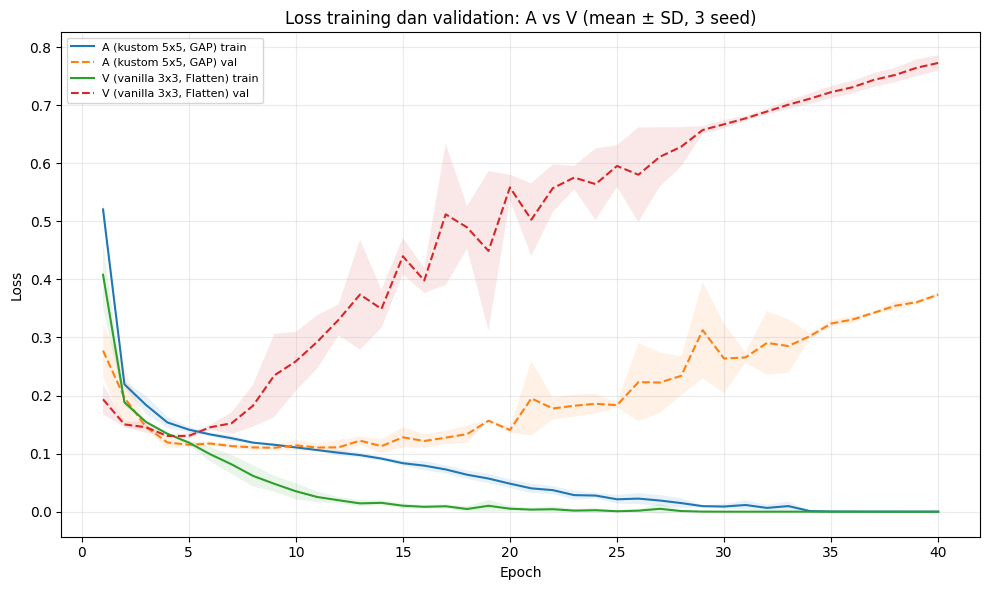

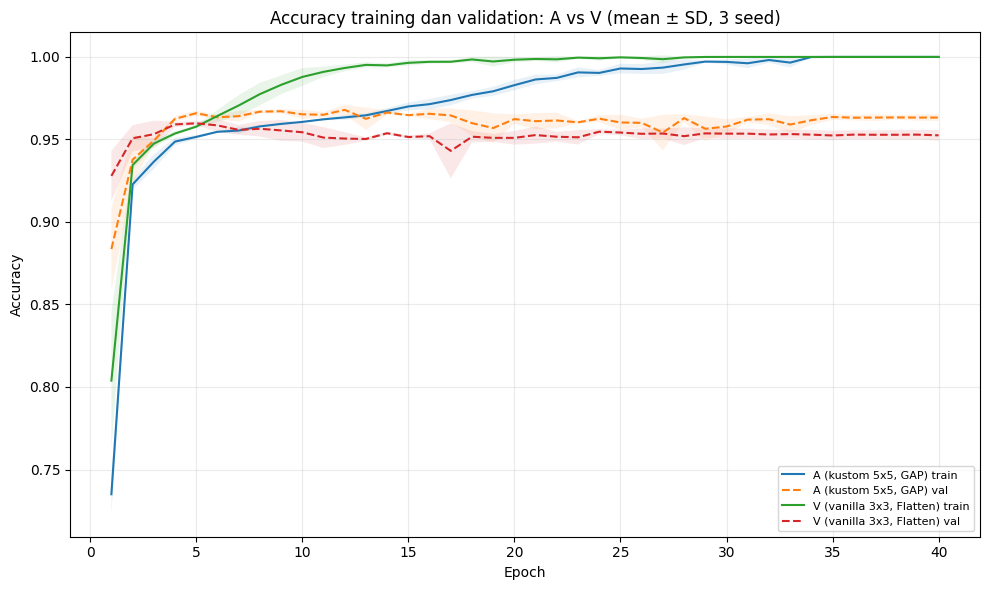

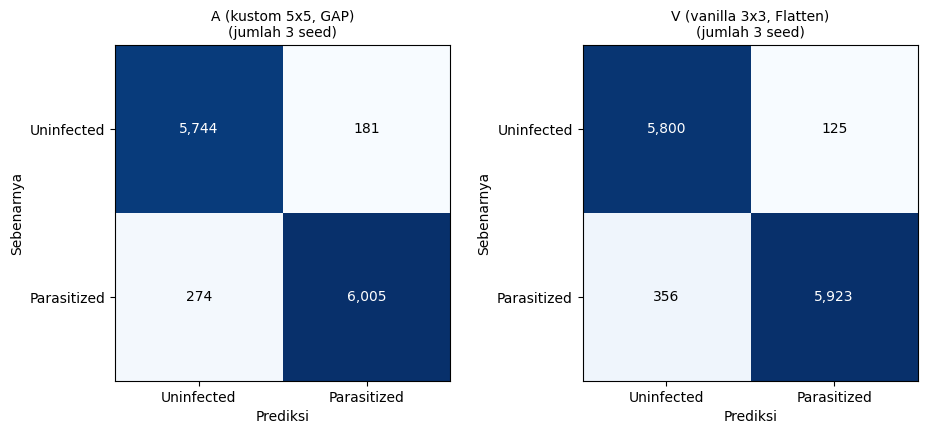

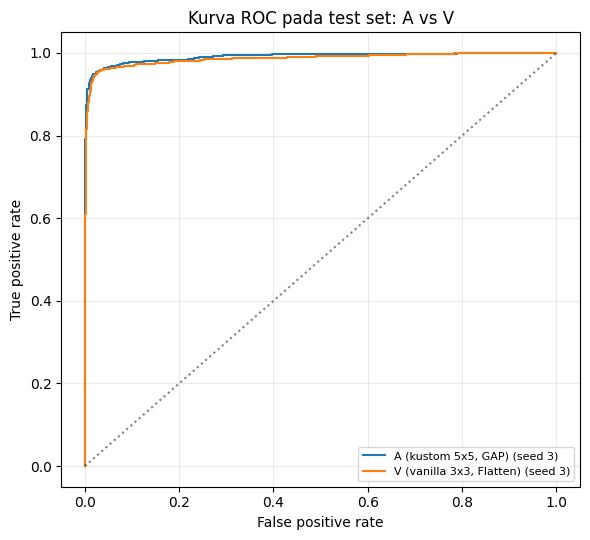

Tersimpan di plots/: kurva_loss_A_vs_V.png, kurva_akurasi_A_vs_V.png, confusion_matrix_A_vs_V.png, roc_A_vs_V.png


In [ ]:
# ---------------------------------------------------------------------------------
# 17.5 Kurva training, confusion matrix, dan ROC: A vs V (format sama dengan Bagian 13)
# ---------------------------------------------------------------------------------
if not V_ALL_DONE or not all((V_RUN_DIRS[s] / "test_metrics.json").exists() for s in SEEDS):
    print("Sel dilewati: pelatihan/evaluasi V belum lengkap.")
else:
    from sklearn.metrics import roc_curve
    from matplotlib.ticker import MaxNLocator

    _models = [(A_NAME, "A (kustom 5x5, GAP)"), (V_NAME, "V (vanilla 3x3, Flatten)")]
    (OUTPUT_DIR / "plots").mkdir(exist_ok=True)

    def _histories(name):
        frames = []
        for s in SEEDS:
            h = pd.read_csv(OUTPUT_DIR / "runs" / f"{name}_seed_{s}" / "history.csv")
            h["seed"] = int(s)
            frames.append(h)
        return pd.concat(frames, ignore_index=True)

    hist = {name: _histories(name) for name, _ in _models}

    # 1) Kurva loss dan akurasi train vs validation (mean ± SD lintas seed)
    for metric, ylabel, filename in [("loss", "Loss", "kurva_loss_A_vs_V.png"),
                                     ("accuracy", "Accuracy", "kurva_akurasi_A_vs_V.png")]:
        fig, ax = plt.subplots(figsize=(10, 6))
        for name, label in _models:
            for prefix, style, tag in [("", "-", "train"), ("val_", "--", "val")]:
                g = hist[name].groupby("epoch")[f"{prefix}{metric}"]
                mean, sd = g.mean(), g.std(ddof=1).fillna(0)
                ax.plot(mean.index, mean.values, style, label=f"{label} {tag}")
                ax.fill_between(mean.index, (mean - sd).values, (mean + sd).values, alpha=0.10)
        ax.set_xlabel("Epoch"); ax.set_ylabel(ylabel)
        ax.xaxis.set_major_locator(MaxNLocator(integer=True))
        ax.grid(alpha=0.25); ax.legend(fontsize=8)
        ax.set_title(f"{ylabel} training dan validation: A vs V (mean ± SD, {len(SEEDS)} seed)")
        fig.tight_layout()
        fig.savefig(OUTPUT_DIR / "plots" / filename, dpi=170)
        plt.show(); plt.close(fig)

    # 2) Confusion matrix (dijumlahkan lintas seed)
    _tm = {name: pd.DataFrame([read_json_safe(OUTPUT_DIR / "runs" / f"{name}_seed_{s}" / "test_metrics.json") for s in SEEDS])
           for name, _ in _models}
    fig, axes = plt.subplots(1, 2, figsize=(9.5, 4.4))
    for ax, (name, label) in zip(axes, _models):
        g = _tm[name]
        cm = np.array([[g.tn.sum(), g.fp.sum()], [g.fn.sum(), g.tp.sum()]])
        ax.imshow(cm, cmap="Blues")
        for i in range(2):
            for j in range(2):
                ax.text(j, i, f"{int(cm[i, j]):,}", ha="center", va="center", color="white" if cm[i, j] > cm.max() / 2 else "black")
        ax.set_xticks([0, 1]); ax.set_xticklabels(["Uninfected", "Parasitized"])
        ax.set_yticks([0, 1]); ax.set_yticklabels(["Uninfected", "Parasitized"])
        ax.set_xlabel("Prediksi"); ax.set_ylabel("Sebenarnya")
        ax.set_title(f"{label}\n(jumlah {len(g)} seed)", fontsize=10)
    fig.tight_layout()
    fig.savefig(OUTPUT_DIR / "plots" / "confusion_matrix_A_vs_V.png", dpi=170)
    plt.show(); plt.close(fig)

    # 3) ROC (seed representatif = F1 test paling dekat dengan rata-rata, aturan yang sama seperti Bagian 13)
    fig, ax = plt.subplots(figsize=(6, 5.5))
    for name, label in _models:
        g = _tm[name]
        rep_seed = int(g.assign(d=(g.f1_parasitized - g.f1_parasitized.mean()).abs()).sort_values("d").iloc[0].seed)
        pr = pd.read_csv(OUTPUT_DIR / "runs" / f"{name}_seed_{rep_seed}" / "test_predictions.csv")
        fpr, tpr, _ = roc_curve(pr.y_true, pr.y_probability_parasitized)
        ax.plot(fpr, tpr, label=f"{label} (seed {rep_seed})")
    ax.plot([0, 1], [0, 1], "k:", alpha=0.5)
    ax.set_xlabel("False positive rate"); ax.set_ylabel("True positive rate")
    ax.set_title("Kurva ROC pada test set: A vs V")
    ax.legend(fontsize=8); ax.grid(alpha=0.25)
    fig.tight_layout()
    fig.savefig(OUTPUT_DIR / "plots" / "roc_A_vs_V.png", dpi=170)
    plt.show(); plt.close(fig)

    print("Tersimpan di plots/: kurva_loss_A_vs_V.png, kurva_akurasi_A_vs_V.png, confusion_matrix_A_vs_V.png, roc_A_vs_V.png")